# Diagnóstico exploratorio de confiabilidad entre modalidades (Fase 1)

Clasificación morfológica binaria de galaxias MaNGA: `temprana` (0) vs `tardia` (1).

**Pregunta científica de esta fase:** ¿existen características observables y patrones de confianza —disponibles *durante inferencia*, sin conocer la etiqueta— que permitan distinguir, mejor que un baseline sencillo, cuándo confiar en el modelo visual (ResNet-18 RGB) y cuándo en el espectral (CNN + attention pooling sobre el espectro STARLIGHT)?

El objetivo **no** es demostrar que un gate funciona, sino decidir si hay evidencia suficiente para justificar desarrollarlo (Fase 2).

### Qué hace y qué no hace este notebook

| Sí | No |
|---|---|
| Reutiliza las `predictions.csv` existentes | Reentrena ResNet-18 ni las CNN espectrales |
| Mapas de probabilidad, confianza, calibración | Implementa nuevas arquitecturas ni un MLP de gating |
| Compara propiedades observacionales / STARLIGHT | Optimiza hiperparámetros |
| Entrena selectores **logísticos pequeños** con CV interna | Usa `test` para elegir variables, umbrales o modelos |

### Protocolo de particiones (restricción central)

* **`validation`** es la *única* partición usada para el diagnóstico y para el selector exploratorio.
* **`train`** solo se inspecciona en la auditoría: sus predicciones vienen de redes que ya vieron esas galaxias, por lo que no sirven para entrenar un selector.
* **`test`** queda reservado: solo se cuentan sus filas para verificar la alineación; después de la auditoría el notebook trabaja con un DataFrame que *no lo contiene* (se verifica con un `assert`).

> **Sesgo conocido de `validation`.** Los checkpoints de las redes base se eligieron con el ROC-AUC de `validation` (early stopping), así que sus predicciones allí son algo más favorables que en datos nuevos. Esto afecta por igual a RGB y espectro, pero el nivel absoluto de las métricas es optimista.

### Documentación de referencia consultada

`notebook/julio/markdowns/EXPERIMENT_GUIDELINES.md`, `notebook/julio/experiments/ANALISIS_EXPERIMENTOS_ABLACION.md` y `notebook/analisis_complementariedad_multimodal.ipynb`. El archivo `RESUMEN_INVESTIGACION_COMPLEMENTARIEDAD_MULTIMODAL.md` mencionado en el encargo **no existe en el repositorio**; su contenido se cubre con los otros tres documentos (§8 del análisis de ablación y el notebook de complementariedad).

### Estructura

0 Configuración · 1 Auditoría y preparación · **Parte I**: 2 Mapa de probabilidades · 3 Incertidumbre y desacuerdo · 4 Calibración · **Parte II**: 5 Análisis de desacuerdos · 6 Propiedades asociadas al rescate · **Parte III**: 7 Selector exploratorio · 8 Simulación de selección · **Parte IV**: 9 Interpretación de decisiones · 10 Conclusiones y recomendación · 11 Exportaciones · 12 Diagnóstico no lineal (XGBoost y árboles).

## 0. Configuración

Todo lo editable está en la celda siguiente. La raíz del proyecto se resuelve buscando `data/galaxy_manifest.csv`, así que el notebook funciona desde cualquier subcarpeta.

Decisiones fijadas **antes** de mirar resultados (para no ajustarlas con lo observado):

* Regresión logística L2 con `C = 1.0`, umbral de decisión 0.5 y **dos modos de decisión con los mismos rasgos**: `balanced` (`class_weight="balanced"`; la clase "gana espectro" es minoritaria, y sin ponderar un selector tiende a elegir siempre RGB; es el modo de las métricas balanceadas) y `prior` (sin ponderar; conserva la tasa base (la de victorias del espectro entre desacuerdos), que es la regla adecuada cuando el objetivo es la **ganancia neta** de aciertos, porque solo conviene cambiar a espectro cuando P(gana espectro) > 0.5 de verdad).
* Variantes `S3c/S4c/S5c`: añaden los rasgos de contexto a las probabilidades *y* las confianzas (S2). Se definieron **a posteriori**, tras ver que la señal estaba en la confianza, y son solo exploratorias.
* Imputación por mediana y estandarización dentro de cada fold mediante `Pipeline`.
* `StratifiedKFold(5, shuffle=True, random_state=42)` solo sobre los desacuerdos de `validation`.
* Mínimo de 15 galaxias por celda del mapa de confiabilidad y 20 por grupo morfológico para sacar conclusiones.

In [1]:
import json
import platform
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import Markdown, display
from scipy import stats
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (balanced_accuracy_score, brier_score_loss, confusion_matrix, f1_score,
                             log_loss, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 220, "display.max_columns", 50, "display.max_rows", 100,
              "display.float_format", "{:.4f}".format)


def find_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "data" / "galaxy_manifest.csv").exists():
            return p
    raise FileNotFoundError("No se encontró la raíz del proyecto (data/galaxy_manifest.csv).")


ROOT = find_root()
EXP_DIR = ROOT / "models" / "experiments"
OUT_DIR = ROOT / "models" / "analysis" / "diagnostico_gate_multimodal"   # carpeta nueva, solo de este notebook
MANIFEST = ROOT / "data" / "galaxy_manifest.csv"
STARLIGHT_INDEX = ROOT / "data" / "processed" / "starlight" / "propiedades" / "indice.csv"
assert EXP_DIR not in OUT_DIR.parents, "Las salidas no deben escribirse dentro de models/experiments"

SAVE_OUTPUTS = True          # False: no escribe tablas ni figuras
SEED = 42
N_FOLDS = 5
N_BOOT = 2000                # remuestreos bootstrap (intervalos de la simulación y de los mapas)
N_BOOT_AUC = 500             # remuestreos para IC de AUC (más caro)
ROBUSTNESS_SEEDS = list(range(10))   # solo chequeo de sensibilidad a la partición de folds

DEV_SPLIT = "validation"     # único split usado para desarrollar
RESERVED_SPLIT = "test"      # reservado: no se usa en ningún análisis
THRESHOLD = 0.5              # umbral de clasificación de los modelos base
ALPHA_FIXED = 0.85           # peso de la fusión tardía fija ya evaluada: 0.85*p_rgb + 0.15*p_spectrum

GRID_BINS = 5                # cuadrícula 5x5 del mapa de confiabilidad
MIN_CELL = 15                # mínimo de galaxias para interpretar una celda
CONF_EDGES = [0, 0.2, 0.4, 0.6, 0.8, 0.9, 1.0]    # intervalos de confianza = 2|p-0.5|
GAP_EDGES = [0, 0.1, 0.25, 0.5, 0.75, 1.0]        # intervalos de |p_rgb - p_spectrum|
HIGH_CONF = 0.8              # "confiado" = confianza >= 0.8, es decir p <= 0.1 o p >= 0.9
ECE_BINS = 10
MIN_GROUP = 20               # mínimo de galaxias para comentar un grupo morfológico
ROBUST_K = 5                 # sensibilidad: ganancia neta tras quitar los K rescates más favorables

LOGREG_C = 1.0

# Experimentos: rol -> carpeta en models/experiments (no se asumen nombres: se verifican abajo)
REQUIRED_MODELS = {
    "rgb":      "imagenes_resnet18_fov",                   # modelo visual principal: ResNet-18 RGB
    "spectrum": "espectros_starlight_cnn_attn_control",    # modelo espectral principal: CNN + attention pooling (STARLIGHT)
    "pop":      "poblaciones_starlight_mlp",               # referencia complementaria: MLP de poblaciones STARLIGHT
}
OPTIONAL_MODELS = {
    "rgb_cnn":  "experimento_binario_imagenes_cnn_gpu",    # CNN RGB compacta
    "spec_fov": "espectros_fov_cnn1d",                     # encoder espectral FoV
}
MODEL_LABELS = {"rgb": "ResNet-18 RGB", "spectrum": "CNN+atención espectro STARLIGHT",
                "pop": "MLP poblaciones STARLIGHT", "rgb_cnn": "CNN RGB compacta", "spec_fov": "CNN1D espectro FoV"}

# Variables del análisis de propiedades (Exp. 5)
VARS_OBS = ["nsa_z", "PETRO_TH90", "LogMass"]
VARS_QUALITY = ["sn_window", "adev_pct", "chi2_nl_eff"]
VARS_PHYS = ["age_mean_light_gyr", "age_mean_mass_gyr", "light_young_lt_100myr_pct",
             "mass_old_ge_1gyr_pct", "z_mean_light", "z_mean_mass", "vd_kms", "av_mag"]
VAR_GROUPS = {**{v: "A. observacional" for v in VARS_OBS}, **{v: "B. calidad espectral" for v in VARS_QUALITY},
              **{v: "C. física" for v in VARS_PHYS}}

# Variantes del selector (Exp. 6). Los features se fijan a priori; no se seleccionan por significancia.
P2 = ["p_rgb", "p_spectrum"]
SELECTOR_FEATURES = {
    "S2min": P2,
    "S2":    P2 + ["confidence_rgb", "confidence_spectrum", "probability_gap"],
    "S3":    P2 + ["nsa_z", "PETRO_TH90", "LogMass"],
    "S4":    P2 + ["sn_window", "adev_pct", "chi2_nl_eff"],
    "S5":    P2 + ["age_mean_light_gyr", "light_young_lt_100myr_pct", "vd_kms"],
}
P2C = P2 + ["confidence_rgb", "confidence_spectrum", "probability_gap"]
# Variantes complementarias definidas A POSTERIORI (tras ver que la señal estaba en la confianza): son exploratorias y
# no participan en la elección de la variante primaria.
SUPPLEMENTARY_FEATURES = {
    "S3c": P2C + ["nsa_z", "PETRO_TH90", "LogMass"],
    "S4c": P2C + ["sn_window", "adev_pct", "chi2_nl_eff"],
    "S5c": P2C + ["age_mean_light_gyr", "light_young_lt_100myr_pct", "vd_kms"],
}
# Modos de decisión (mismos rasgos, mismo umbral 0.5, solo cambia el peso de clases):
#   ""       -> class_weight="balanced": optimiza balanced accuracy / recall del espectro (métricas del §7)
#   "|prior" -> sin ponderar: la probabilidad conserva la tasa base de victorias del espectro, de modo que cambiar a
#               espectro con P>0.5 es la regla que maximiza la ganancia neta (aciertos totales)
MODES = {"": "balanced", "|prior": None}
N_PERM = 200                 # permutaciones de etiqueta para el nulo del AUC OOF
DECISION_MODE = "|prior"     # modo usado en la interpretación de decisiones (§9) y en los criterios de ganancia neta
# Qué hay que tener disponible en inferencia para cada variante
INFERENCE_NEEDS = {
    "S0": "RGB + espectro (solo para saber si discrepan)",
    "S1": "RGB + espectro",
    "S2min": "RGB + espectro",
    "S2": "RGB + espectro",
    "S3": "RGB + espectro + catálogo (z, PETRO_TH90, LogMass)",
    "S4": "RGB + espectro + ajuste STARLIGHT (S/N, adev, chi2)",
    "S5": "RGB + espectro + ajuste STARLIGHT (edad, fracción joven, dispersión de velocidades)",
    "S3c": "RGB + espectro + catálogo (z, PETRO_TH90, LogMass)",
    "S4c": "RGB + espectro + ajuste STARLIGHT (S/N, adev, chi2)",
    "S5c": "RGB + espectro + ajuste STARLIGHT (edad, fracción joven, dispersión de velocidades)",
}
FORBIDDEN_FEATURES = {"name", "label", "Ttype", "Type", "y_true", "y_pred", "correct", "selector_target",
                      "mini_tot", "mcor_tot", "correct_rgb", "correct_spectrum", "correct_selector"}
for _k, _f in {**SELECTOR_FEATURES, **SUPPLEMENTARY_FEATURES}.items():
    assert not (set(_f) & FORBIDDEN_FEATURES), f"{_k}: features prohibidos {set(_f) & FORBIDDEN_FEATURES}"

PRIMARY_SELECTOR = None      # None: entre S2min..S5 (modo balanced) se elige la de mayor ROC-AUC OOF (ver caveat en §7)

rng = np.random.default_rng(SEED)
if SAVE_OUTPUTS:
    (OUT_DIR / "figuras").mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    if SAVE_OUTPUTS:
        fig.savefig(OUT_DIR / "figuras" / f"{name}.png", dpi=130, bbox_inches="tight")


def save_table(df, name, index=False):
    if SAVE_OUTPUTS:
        df.to_csv(OUT_DIR / f"{name}.csv", index=index)


def wilson(k, n, conf=0.95):
    # IC de Wilson para una proporción k/n
    if n == 0:
        return np.nan, np.nan
    ci = stats.binomtest(int(k), int(n)).proportion_ci(confidence_level=conf, method="wilson")
    return ci.low, ci.high


def paired_diff_ci(correct_a, correct_b, n_boot=N_BOOT, rng=rng):
    # diferencia pareada de accuracy (b - a) con IC bootstrap percentil
    d = np.asarray(correct_b, dtype=int) - np.asarray(correct_a, dtype=int)
    n = len(d)
    if n == 0:
        return np.nan, np.nan, np.nan
    boots = d[rng.integers(0, n, (n_boot, n))].mean(axis=1)
    return d.mean(), *np.percentile(boots, [2.5, 97.5])


def holm(p):
    # ajuste de Holm-Bonferroni (controla la tasa de error por familia)
    p = np.asarray(p, dtype=float)
    out = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    pv = p[ok]
    order = np.argsort(pv)
    adj = np.maximum.accumulate((len(pv) - np.arange(len(pv))) * pv[order])
    res = np.empty_like(pv)
    res[order] = np.minimum(adj, 1.0)
    out[ok] = res
    return out


def auc_ci(y, s, n_boot=N_BOOT_AUC, rng=rng):
    y, s = np.asarray(y), np.asarray(s)
    if len(np.unique(y)) < 2:
        return np.nan, np.nan, np.nan
    vals = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) == 2:
            vals.append(roc_auc_score(y[i], s[i]))
    return roc_auc_score(y, s), *np.percentile(vals, [2.5, 97.5])


print(f"Raíz del proyecto: {ROOT}")
print(f"Salidas en:        {OUT_DIR}")
print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | python {platform.python_version()}")

Raíz del proyecto: /Users/juliovelazquez/Documents/maestria/proyecto_integrador/clasificacion-galaxias
Salidas en:        /Users/juliovelazquez/Documents/maestria/proyecto_integrador/clasificacion-galaxias/models/analysis/diagnostico_gate_multimodal
pandas 3.0.5 | numpy 1.26.4 | scikit-learn 1.9.0 | python 3.12.11


## 1. Auditoría y preparación

**Pregunta:** ¿podemos comparar los modelos galaxia por galaxia sin sorpresas?

**Método:** (i) descubrir qué experimentos existen realmente en `models/experiments/`; (ii) validar esquema, tipos, rango de probabilidades y que `y_proba` sea P(tardía); (iii) alinear por `(name, split)` —nunca por posición— con un `inner join` que verificamos que no descarte galaxias; (iv) integrar manifest y propiedades STARLIGHT por `name`; (v) cuantificar valores faltantes y rangos extremos.

**Por qué importa:** si dos modelos no evaluaron exactamente las mismas galaxias, una comparación pareada mezclaría diferencias de muestra con diferencias de modelo.

In [2]:
# Descubrimiento: todo experimento con predictions.csv, y qué rol (si alguno) le asignamos
found = sorted(p.parent.name for p in EXP_DIR.glob("*/predictions.csv"))
role_of = {v: k for k, v in {**REQUIRED_MODELS, **OPTIONAL_MODELS}.items()}
disc = pd.DataFrame({"experimento": found, "rol_en_este_notebook": [role_of.get(f, "(no usado)") for f in found]})
display(disc)

missing_req = {r: f for r, f in REQUIRED_MODELS.items() if f not in found}
assert not missing_req, f"Faltan experimentos requeridos (edita REQUIRED_MODELS): {missing_req}"
MODELS = dict(REQUIRED_MODELS)
for r, f in OPTIONAL_MODELS.items():
    if f in found:
        MODELS[r] = f
    else:
        print(f"[aviso] experimento opcional ausente, se omite: {r} -> {f}")

raw = {r: pd.read_csv(EXP_DIR / f / "predictions.csv") for r, f in MODELS.items()}
SPLITS = ["train", "validation", "test"]
EXPECTED = ["name", "split", "label", "y_true", "y_proba", "y_pred", "pred_label", "correct"]

rows = []
for r, d in raw.items():
    aud = {"rol": r, "experimento": MODELS[r], "filas": len(d),
           "columnas_esperadas": list(d.columns) == EXPECTED,
           "y_true_entero": pd.api.types.is_integer_dtype(d.y_true),
           "y_proba_float": pd.api.types.is_float_dtype(d.y_proba),
           "duplicados(name,split)": int(d.duplicated(["name", "split"]).sum()),
           "nulos": int(d[EXPECTED].isna().sum().sum()),
           "label==y_true": bool(((d.label == "tardia").astype(int) == d.y_true).all()),
           "pred_label coherente": bool(((d.pred_label == "tardia").astype(int) == d.y_pred).all()),
           "y_pred==(proba>=0.5)": float((d.y_pred == (d.y_proba >= THRESHOLD)).mean()),
           "correct==(y_pred==y_true)": bool((d.correct == (d.y_pred == d.y_true)).all()),
           "proba en [0,1]": bool(d.y_proba.between(0, 1).all())}
    # y_proba = P(tardía): media mayor en tardías y AUC > 0.5. Solo train/validation (no se mira test).
    for s in ["train", "validation"]:
        g = d[d.split == s]
        aud[f"P media|tardía-temprana ({s})"] = g.groupby("y_true").y_proba.mean().diff().iloc[-1]
        aud[f"AUC ({s})"] = roc_auc_score(g.y_true, g.y_proba)
    for s in SPLITS:
        aud[f"n_{s}"] = int((d.split == s).sum())
    rows.append(aud)
audit = pd.DataFrame(rows).set_index("rol")
display(audit.T)

bad = [c for c in ["columnas_esperadas", "y_true_entero", "y_proba_float", "label==y_true", "pred_label coherente",
                   "correct==(y_pred==y_true)", "proba en [0,1]"] if not audit[c].all()]
bad += [c for c in ["duplicados(name,split)", "nulos"] if (audit[c] != 0).any()]
assert not bad, f"Auditoría fallida en: {bad}"
assert (audit["P media|tardía-temprana (validation)"] > 0).all() and (audit["AUC (validation)"] > 0.5).all(), \
    "y_proba no parece P(tardía)"
print("Auditoría de esquema, etiquetas, duplicados y rango: OK")

,experimento,rol_en_este_notebook
0,espectros_fov_cnn1d,spec_fov
1,espectros_fov_cnn_attn_control,(no usado)
2,espectros_fov_cnn_bigru,(no usado)
3,espectros_fov_patch_bigru,(no usado)
4,espectros_starlight_cnn1d,(no usado)
5,espectros_starlight_cnn_attn_control,spectrum
6,espectros_starlight_cnn_bigru,(no usado)
7,espectros_starlight_patch_bigru,(no usado)
8,experimento_binario_imagenes_cnn_gpu,rgb_cnn
9,imagenes_resnet18_fov,rgb


rol,rgb,spectrum,pop,rgb_cnn,spec_fov
experimento,imagenes_resnet18_fov,espectros_starlight_cnn_attn_control,poblaciones_starlight_mlp,experimento_binario_imagenes_cnn_gpu,espectros_fov_cnn1d
filas,9351,9351,9351,9351,9351
columnas_esperadas,True,True,True,True,True
y_true_entero,True,True,True,True,True
y_proba_float,True,True,True,True,True
"duplicados(name,split)",0,0,0,0,0
nulos,0,0,0,0,0
label==y_true,True,True,True,True,True
pred_label coherente,True,True,True,True,True
y_pred==(proba>=0.5),1.0000,1.0000,1.0000,1.0000,1.0000


Auditoría de esquema, etiquetas, duplicados y rango: OK


In [3]:
# Alineación por (name, split): inner join con validación one_to_one y comprobación de que no se pierde ninguna galaxia
keys = {r: {s: set(d.loc[d.split == s, "name"]) for s in SPLITS} for r, d in raw.items()}
union = {s: set.union(*[keys[r][s] for r in keys]) for s in SPLITS}
inter = {s: set.intersection(*[keys[r][s] for r in keys]) for s in SPLITS}
cohort = pd.DataFrame({"union": {s: len(union[s]) for s in SPLITS}, "interseccion": {s: len(inter[s]) for s in SPLITS}})
cohort["faltantes_por_modelo"] = [{r: len(union[s]) - len(keys[r][s]) for r in keys if len(union[s]) != len(keys[r][s])} or "ninguno"
                                  for s in SPLITS]
display(cohort)
cross = {f"{a}&{b}": len(union[a] & union[b]) for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]}
print("Galaxias presentes en más de un split (debe ser 0):", cross)
assert all(v == 0 for v in cross.values())

wide = None
for r, d in raw.items():
    t = d[["name", "split", "label", "y_true", "y_proba"]].rename(
        columns={"y_proba": f"p_{r}", "y_true": f"yt_{r}", "label": f"lab_{r}"})
    wide = t if wide is None else wide.merge(t, on=["name", "split"], how="inner", validate="one_to_one")

dropped = {s: len(union[s]) - int((wide.split == s).sum()) for s in SPLITS}
assert all(v == 0 for v in dropped.values()), f"El join descartó galaxias: {dropped}"
yt_cols = [c for c in wide if c.startswith("yt_")]
lab_cols = [c for c in wide if c.startswith("lab_")]
assert (wide[yt_cols].nunique(axis=1) == 1).all() and (wide[lab_cols].nunique(axis=1) == 1).all(), \
    "Etiqueta verdadera inconsistente entre modalidades"
wide["y_true"], wide["label"] = wide[yt_cols[0]], wide[lab_cols[0]]
wide = wide.drop(columns=yt_cols + lab_cols)
print(f"Tabla alineada: {wide.shape} | galaxias descartadas por el join: {sum(dropped.values())} | etiqueta idéntica en los {len(raw)} modelos")
display(wide.groupby("split").agg(n=("name", "size"), tardias=("y_true", "sum"), frac_tardia=("y_true", "mean")).loc[SPLITS])

,union,interseccion,faltantes_por_modelo
train,6545,6545,ninguno
validation,1403,1403,ninguno
test,1403,1403,ninguno


Galaxias presentes en más de un split (debe ser 0): {'train&validation': 0, 'train&test': 0, 'validation&test': 0}


Tabla alineada: (9351, 9) | galaxias descartadas por el join: 0 | etiqueta idéntica en los 5 modelos


,n,tardias,frac_tardia
split,,,
train,6545,4078,0.6231
validation,1403,874,0.6230
test,1403,875,0.6237


In [4]:
# Integración de manifest y propiedades STARLIGHT por name
manifest = pd.read_csv(MANIFEST)
sl = pd.read_csv(STARLIGHT_INDEX)
assert manifest.name.is_unique and sl.name.is_unique

meta_cols = ["name", "Ttype", "Type", "LogMass", "nsa_z", "incl", "PETRO_TH90", "label", "fov_0_path"]
sl_cols = [c for c in VARS_QUALITY + VARS_PHYS if c in sl.columns]
absent = [c for c in VARS_QUALITY + VARS_PHYS if c not in sl.columns]
print("Propiedades STARLIGHT disponibles:", sl_cols, "| ausentes:", absent or "ninguna")

full = (wide.merge(manifest[meta_cols].rename(columns={"label": "label_manifest"}), on="name", how="left", validate="many_to_one")
            .merge(sl[["name", "nsa_z"] + sl_cols].rename(columns={"nsa_z": "nsa_z_sl"}), on="name", how="left", validate="many_to_one"))

print(f"Galaxias sin entrada en manifest: {int(full.label_manifest.isna().sum())} | "
      f"sin propiedades STARLIGHT: {int(full.nsa_z_sl.isna().sum())} (de {len(full)})")
print("Etiqueta distinta al manifest:", int((full.label_manifest.notna() & (full.label != full.label_manifest)).sum()))
print("Discrepancia de nsa_z manifest vs índice STARLIGHT (max abs):",
      float((full.nsa_z - full.nsa_z_sl).abs().max()))
print("Galaxias sin STARLIGHT por split:", full[full.nsa_z_sl.isna()].groupby("split").size().to_dict() or "ninguna")

# A partir de aquí solo se trabaja con validation. test no vuelve a aparecer.
dev = full[full.split == DEV_SPLIT].drop(columns=["label_manifest", "nsa_z_sl"]).reset_index(drop=True)
assert set(dev.split) == {DEV_SPLIT} and RESERVED_SPLIT not in set(dev.split)
print(f"\nMuestra de desarrollo ('{DEV_SPLIT}'): {len(dev)} galaxias | tardías: {int(dev.y_true.sum())} ({dev.y_true.mean():.1%})")

Propiedades STARLIGHT disponibles: ['sn_window', 'adev_pct', 'chi2_nl_eff', 'age_mean_light_gyr', 'age_mean_mass_gyr', 'light_young_lt_100myr_pct', 'mass_old_ge_1gyr_pct', 'z_mean_light', 'z_mean_mass', 'vd_kms', 'av_mag'] | ausentes: ninguna
Galaxias sin entrada en manifest: 0 | sin propiedades STARLIGHT: 0 (de 9351)
Etiqueta distinta al manifest: 0
Discrepancia de nsa_z manifest vs índice STARLIGHT (max abs): 0.0
Galaxias sin STARLIGHT por split: ninguna

Muestra de desarrollo ('validation'): 1403 galaxias | tardías: 874 (62.3%)


In [5]:
# Faltantes y rangos extremos en la muestra de desarrollo (no se elimina ni se imputa nada aquí)
num_vars = VARS_OBS + sl_cols
qa = []
for v in num_vars:
    x = dev[v]
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    qa.append({"variable": v, "grupo": VAR_GROUPS[v], "n_validos": int(x.notna().sum()), "n_faltantes": int(x.isna().sum()),
               "min": x.min(), "p01": x.quantile(0.01), "mediana": x.median(), "p99": x.quantile(0.99), "max": x.max(),
               "n_extremos(>3IQR)": int(((x < q1 - 3 * iqr) | (x > q3 + 3 * iqr)).sum()),
               "n_no_positivos": int((x <= 0).sum())})
qa = pd.DataFrame(qa).set_index("variable")
display(qa)
print("Faltantes en Ttype:", int(dev.Ttype.isna().sum()), "| en las 3 probabilidades:", int(dev[["p_rgb", "p_spectrum", "p_pop"]].isna().sum().sum()))

,grupo,n_validos,n_faltantes,min,p01,mediana,p99,max,n_extremos(>3IQR),n_no_positivos
variable,,,,,,,,,,
nsa_z,A. observacional,1403,0,0.0011,0.0142,0.0385,0.1390,0.1487,8,0
PETRO_TH90,A. observacional,1403,0,3.4388,4.4084,12.9932,53.4009,140.8784,24,0
LogMass,A. observacional,1403,0,8.3187,8.7417,10.1879,11.4170,11.8656,0,0
sn_window,B. calidad espectral,1403,0,2.1180,11.9676,31.9570,64.1758,80.0220,7,0
adev_pct,B. calidad espectral,1403,0,1.3230,1.6833,3.1816,9.7935,17.7189,13,0
chi2_nl_eff,B. calidad espectral,1403,0,0.0461,0.3432,1.1410,2.1973,2.6407,0,0
age_mean_light_gyr,C. física,1403,0,0.0028,0.3795,3.8583,11.7089,12.2962,0,0
age_mean_mass_gyr,C. física,1403,0,0.0027,0.8996,9.0925,12.5968,12.9692,0,0
light_young_lt_100myr_pct,C. física,1403,0,0.0000,0.0000,19.6881,71.5296,100.0000,0,130


Faltantes en Ttype: 0 | en las 3 probabilidades: 0


**Lectura de la auditoría.** Los resultados de las celdas anteriores se verifican con `assert`: si el esquema, las etiquetas, los duplicados o el rango de probabilidades fallaran, el notebook se detendría. El número de galaxias alineadas, los faltantes y los valores extremos se muestran en las tablas de arriba.

Los valores extremos **no se eliminan**: las colas largas (p. ej. `vd_kms`, `PETRO_TH90`, `nsa_z`) son esperables en una muestra astronómica. Los faltantes se manejarán dentro de cada fold con imputación por mediana (§7), nunca antes.

**Limitación:** el `inner join` se verificó contra la unión de nombres por split, de modo que ninguna galaxia se descartó silenciosamente.

### Variables derivadas

Para cada galaxia definimos (heurísticas de confianza, **no** probabilidades calibradas de acierto):

```
confidence_m  = 2 * |p_m - 0.5|          # 0 = indecisa, 1 = máxima confianza
uncertainty_m = 1 - confidence_m
probability_gap = |p_rgb - p_spectrum|
disagreement  = (p_rgb >= 0.5) != (p_spectrum >= 0.5)
selector_target = (y_pred_spectrum == y_true)   # solo si hay desacuerdo; 1 = gana el espectro, 0 = gana RGB
```

`selector_target` **nunca** se usa como característica: solo para entrenar y evaluar el selector.

In [6]:
def add_derived(df):
    df = df.copy()
    for m in ["rgb", "spectrum", "pop"]:
        df[f"pred_{m}"] = (df[f"p_{m}"] >= THRESHOLD).astype(int)
        df[f"correct_{m}"] = df[f"pred_{m}"] == df.y_true
    for m in ["rgb", "spectrum", "pop"]:
        df[f"confidence_{m}"] = 2 * (df[f"p_{m}"] - 0.5).abs()
        df[f"uncertainty_{m}"] = 1 - df[f"confidence_{m}"]
    df["probability_gap"] = (df.p_rgb - df.p_spectrum).abs()
    df["disagreement"] = df.pred_rgb != df.pred_spectrum
    df["selector_target"] = np.where(df.disagreement, (df.pred_spectrum == df.y_true).astype(float), np.nan)
    df["outcome"] = np.select(
        [df.correct_rgb & df.correct_spectrum, df.correct_rgb & ~df.correct_spectrum,
         ~df.correct_rgb & df.correct_spectrum], ["ambos aciertan", "solo RGB acierta", "solo espectro acierta"], "ambos fallan")
    df["direction"] = np.where(~df.disagreement, "acuerdo",
                               np.where(df.pred_rgb == 1, "RGB tardía / Esp. temprana", "RGB temprana / Esp. tardía"))
    return df


dev = add_derived(dev)
dis = dev[dev.disagreement].copy()

# En un desacuerdo binario exactamente uno de los dos modelos acierta
assert ((dis.correct_rgb.astype(int) + dis.correct_spectrum.astype(int)) == 1).all()
assert dis.selector_target.notna().all() and dev.loc[~dev.disagreement, "selector_target"].isna().all()

OUTCOME_ORDER = ["ambos aciertan", "solo RGB acierta", "solo espectro acierta", "ambos fallan"]
OUTCOME_COLORS = {"ambos aciertan": "#c7c7c7", "solo RGB acierta": "#1f77b4", "solo espectro acierta": "#d62728", "ambos fallan": "#2b2b2b"}
cnt = dev.outcome.value_counts().reindex(OUTCOME_ORDER)
display(pd.DataFrame({"n": cnt, "%": cnt / len(dev) * 100}))
print(f"Galaxias alineadas en {DEV_SPLIT}: {len(dev)} | desacuerdos: {len(dis)} ({len(dis)/len(dev):.1%}) | "
      f"gana RGB: {int((dis.selector_target == 0).sum())} | gana espectro: {int((dis.selector_target == 1).sum())}")

,n,%
outcome,,
ambos aciertan,1085,77.3343
solo RGB acierta,172,12.2594
solo espectro acierta,85,6.0584
ambos fallan,61,4.3478


Galaxias alineadas en validation: 1403 | desacuerdos: 257 (18.3%) | gana RGB: 172 | gana espectro: 85


**Qué muestra.** La tabla de resultados cruza acierto de RGB y espectro. Los desacuerdos son la fracción de galaxias donde las dos modalidades predicen clases distintas; solo ahí un selector puede cambiar el resultado respecto a usar RGB. Todo el diagnóstico posterior condiciona sobre esa fracción, lo que limita desde el inicio cuánta ganancia global es posible.

# PARTE I — Diagnóstico de confiabilidad

## 2. Experimento 1: mapa bidimensional de probabilidades

**Pregunta:** ¿existen regiones del espacio `(p_rgb, p_spectrum)` donde el espectro sea más fiable que RGB?

**Hipótesis:** el espectro debería ganar sobre todo donde RGB está cerca de 0.5 (indeciso) y el espectro está lejos de 0.5 (decidido).

**Método:** (1) scatter coloreado por etiqueta verdadera y por resultado de comparación, con las cuatro regiones delimitadas por 0.5; (2) cuadrícula `5×5` con n, accuracy de cada modelo, diferencia pareada (espectro − RGB) con IC bootstrap y tasa de desacuerdo por celda. Las celdas con menos de `MIN_CELL` galaxias se muestran pero no se interpretan.

**Cuidado con la cuadrícula:** la celda central `[0.4, 0.6)` contiene el umbral 0.5, así que mezcla predicciones de ambas clases. Los extremos acumulan casi todas las galaxias porque las probabilidades son bimodales.

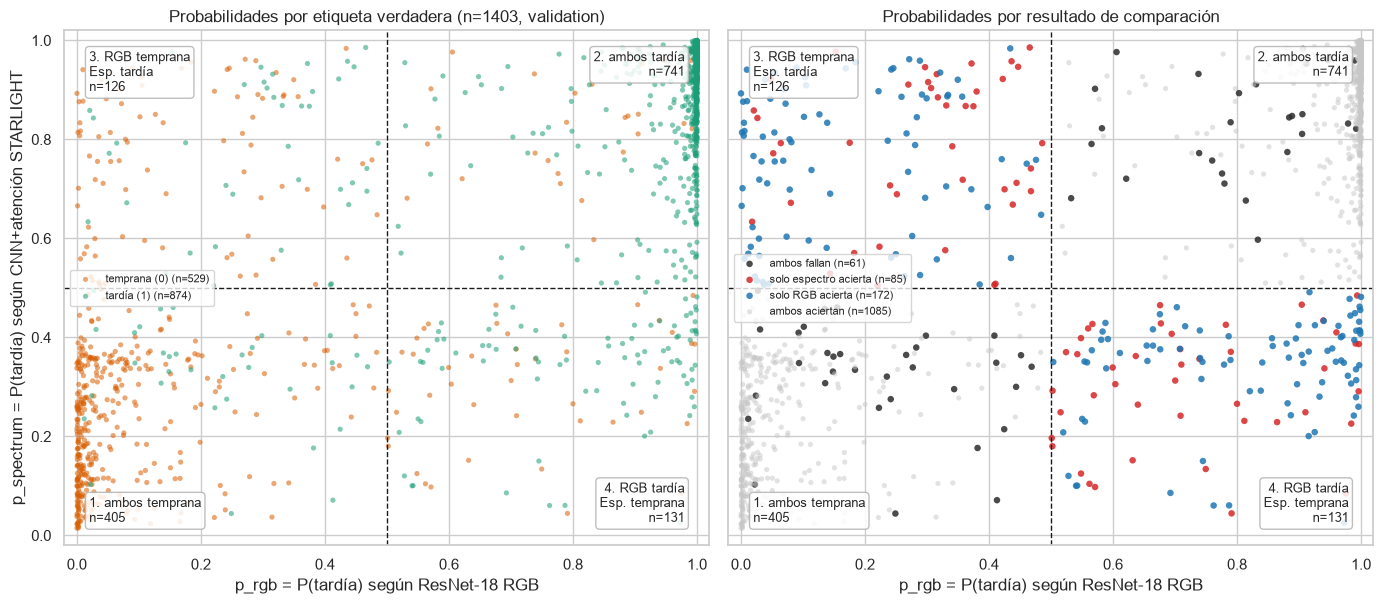

,n,frac_tardia,acc_rgb,acc_spectrum
q,,,,
1. ambos temprana,405,0.0815,0.9185,0.9185
2. ambos tardía,741,0.9622,0.9622,0.9622
3. RGB temprana / Esp. tardía,126,0.3254,0.6746,0.3254
4. RGB tardía / Esp. temprana,131,0.6641,0.6641,0.3359


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), sharex=True, sharey=True)

# (a) por etiqueta verdadera
for lab, col, name in [(0, "#d95f02", "temprana (0)"), (1, "#1b9e77", "tardía (1)")]:
    g = dev[dev.y_true == lab]
    axes[0].scatter(g.p_rgb, g.p_spectrum, s=14, alpha=0.55, c=col, label=f"{name} (n={len(g)})", edgecolors="none")
# (b) por resultado de comparación
for o in OUTCOME_ORDER[::-1]:
    g = dev[dev.outcome == o]
    axes[1].scatter(g.p_rgb, g.p_spectrum, s=14 if o == "ambos aciertan" else 22, alpha=0.5 if o == "ambos aciertan" else 0.85,
                    c=OUTCOME_COLORS[o], label=f"{o} (n={len(g)})", edgecolors="none")

q = dev.assign(q=np.select(
    [(dev.pred_rgb == 0) & (dev.pred_spectrum == 0), (dev.pred_rgb == 1) & (dev.pred_spectrum == 1),
     (dev.pred_rgb == 0) & (dev.pred_spectrum == 1)], ["Q1", "Q2", "Q3"], "Q4"))
qn = q.q.value_counts()
for ax in axes:
    ax.axvline(THRESHOLD, color="k", ls="--", lw=1)
    ax.axhline(THRESHOLD, color="k", ls="--", lw=1)
    ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
    ax.set_xlabel("p_rgb = P(tardía) según ResNet-18 RGB")
    for (x, y, t, key) in [(0.02, 0.02, "1. ambos temprana", "Q1"), (0.98, 0.98, "2. ambos tardía", "Q2"),
                           (0.02, 0.98, "3. RGB temprana\nEsp. tardía", "Q3"), (0.98, 0.02, "4. RGB tardía\nEsp. temprana", "Q4")]:
        ax.text(x, y, f"{t}\nn={qn.get(key, 0)}", ha="left" if x < 0.5 else "right", va="bottom" if y < 0.5 else "top",
                fontsize=9, bbox=dict(boxstyle="round", fc="white", ec="0.7", alpha=0.85))
axes[0].set_ylabel("p_spectrum = P(tardía) según CNN+atención STARLIGHT")
axes[0].set_title(f"Probabilidades por etiqueta verdadera (n={len(dev)}, validation)")
axes[1].set_title("Probabilidades por resultado de comparación")
axes[0].legend(loc="center left", fontsize=8); axes[1].legend(loc="center left", fontsize=8)
fig.tight_layout(); save_fig(fig, "exp1_scatter_probabilidades"); plt.show()

quad = q.groupby("q").agg(n=("name", "size"), frac_tardia=("y_true", "mean"), acc_rgb=("correct_rgb", "mean"),
                          acc_spectrum=("correct_spectrum", "mean"))
quad.index = quad.index.map({"Q1": "1. ambos temprana", "Q2": "2. ambos tardía", "Q3": "3. RGB temprana / Esp. tardía", "Q4": "4. RGB tardía / Esp. temprana"})
display(quad)

**Interpretación.** Las regiones 1 y 2 son los acuerdos; 3 y 4 son los desacuerdos. La tabla anterior muestra, para cada región, la fracción real de tardías y la accuracy de cada modelo: en las regiones de desacuerdo esas dos accuracies suman 1, y su reparto indica qué modalidad "tiene razón" más a menudo en cada dirección de discrepancia. El segundo panel permite ver si los puntos `solo espectro acierta` (rojo) se agrupan en alguna zona o se mezclan con `solo RGB acierta` (azul).

**Limitación:** es una vista marginal; no controla por el tipo morfológico ni por la calidad de los datos.

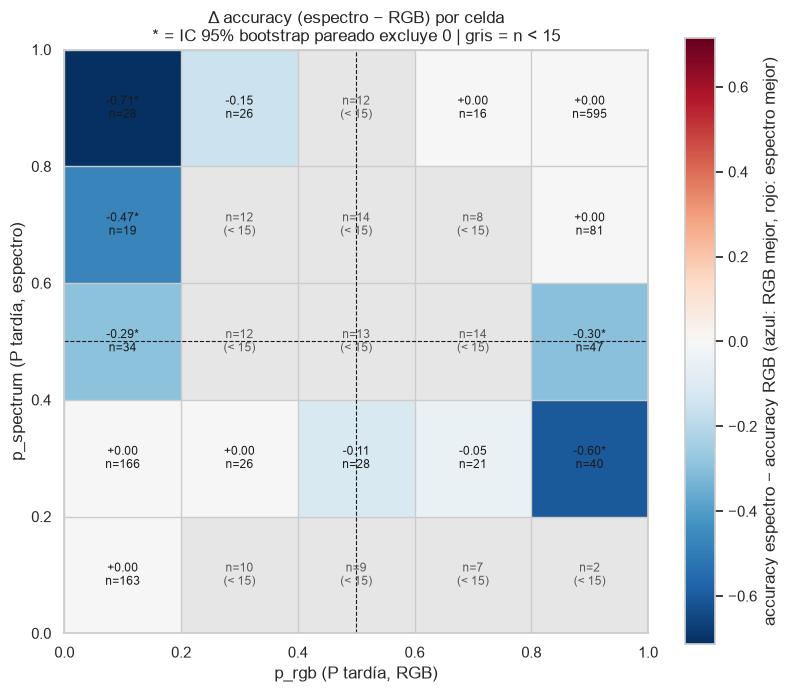

,rgb_rango,spec_rango,n,acc_rgb,acc_spectrum,diff_acc_esp_menos_rgb,diff_ci_low,diff_ci_high,tasa_desacuerdo,n_desacuerdos,interpretable
0,"[0.8, 1.0]","[0.8, 1.0]",595,0.9782,0.9782,0.0000,0.0000,0.0000,0.0000,0,True
1,"[0.0, 0.2]","[0.2, 0.4]",166,0.9458,0.9458,0.0000,0.0000,0.0000,0.0000,0,True
2,"[0.0, 0.2]","[0.0, 0.2]",163,0.9939,0.9939,0.0000,0.0000,0.0000,0.0000,0,True
3,"[0.8, 1.0]","[0.6, 0.8]",81,0.9753,0.9753,0.0000,0.0000,0.0000,0.0000,0,True
4,"[0.8, 1.0]","[0.4, 0.6]",47,0.8936,0.5957,-0.2979,-0.4681,-0.1277,0.4681,22,True
5,"[0.8, 1.0]","[0.2, 0.4]",40,0.8000,0.2000,-0.6000,-0.8500,-0.3500,1.0000,40,True
6,"[0.0, 0.2]","[0.4, 0.6]",34,0.7647,0.4706,-0.2941,-0.4706,-0.1176,0.4118,14,True
7,"[0.4, 0.6]","[0.2, 0.4]",28,0.5714,0.4643,-0.1071,-0.3929,0.1786,0.6071,17,True
8,"[0.0, 0.2]","[0.8, 1.0]",28,0.8571,0.1429,-0.7143,-0.9286,-0.4286,1.0000,28,True
9,"[0.2, 0.4]","[0.2, 0.4]",26,0.7308,0.7308,0.0000,0.0000,0.0000,0.0000,0,True


In [8]:
# Mapa de confiabilidad: cuadrícula GRID_BINS x GRID_BINS en (p_rgb, p_spectrum)
edges = np.linspace(0, 1, GRID_BINS + 1)
dev["bin_rgb"] = pd.cut(dev.p_rgb, edges, include_lowest=True, labels=False)
dev["bin_spec"] = pd.cut(dev.p_spectrum, edges, include_lowest=True, labels=False)

cells = []
for (i, j), g in dev.groupby(["bin_rgb", "bin_spec"]):
    diff, lo, hi = paired_diff_ci(g.correct_rgb, g.correct_spectrum) if len(g) >= MIN_CELL else (g.correct_spectrum.mean() - g.correct_rgb.mean(), np.nan, np.nan)
    cells.append({"bin_rgb": int(i), "bin_spec": int(j), "rgb_rango": f"[{edges[i]:.1f}, {edges[i+1]:.1f}]",
                  "spec_rango": f"[{edges[j]:.1f}, {edges[j+1]:.1f}]", "n": len(g),
                  "acc_rgb": g.correct_rgb.mean(), "acc_spectrum": g.correct_spectrum.mean(),
                  "diff_acc_esp_menos_rgb": diff, "diff_ci_low": lo, "diff_ci_high": hi,
                  "tasa_desacuerdo": g.disagreement.mean(), "n_desacuerdos": int(g.disagreement.sum()),
                  "interpretable": len(g) >= MIN_CELL})
grid = pd.DataFrame(cells)
save_table(grid, "reliability_grid")

fig, ax = plt.subplots(figsize=(8.2, 7))
mat = np.full((GRID_BINS, GRID_BINS), np.nan)
for _, r in grid.iterrows():
    if r.interpretable:
        mat[r.bin_spec, r.bin_rgb] = r.diff_acc_esp_menos_rgb
vmax = max(0.05, np.nanmax(np.abs(mat))) if np.isfinite(mat).any() else 1
im = ax.imshow(np.ma.masked_invalid(mat), origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="equal")
ax.set_facecolor("#e6e6e6")
for _, r in grid.iterrows():
    cx, cy = (r.bin_rgb + 0.5) / GRID_BINS, (r.bin_spec + 0.5) / GRID_BINS
    if r.interpretable:
        sig = "*" if (r.diff_ci_low > 0 or r.diff_ci_high < 0) else ""
        txt = f"{r.diff_acc_esp_menos_rgb:+.2f}{sig}\nn={r.n}"
    else:
        txt = f"n={r.n}\n(< {MIN_CELL})"
    ax.text(cx, cy, txt, ha="center", va="center", fontsize=8.5, color="k" if r.interpretable else "0.35")
ax.axvline(THRESHOLD, color="k", ls="--", lw=0.8); ax.axhline(THRESHOLD, color="k", ls="--", lw=0.8)
ax.set_xticks(edges); ax.set_yticks(edges)
ax.set_xlabel("p_rgb (P tardía, RGB)"); ax.set_ylabel("p_spectrum (P tardía, espectro)")
ax.set_title(f"Δ accuracy (espectro − RGB) por celda\n* = IC 95% bootstrap pareado excluye 0 | gris = n < {MIN_CELL}")
fig.colorbar(im, ax=ax, label="accuracy espectro − accuracy RGB (azul: RGB mejor, rojo: espectro mejor)")
fig.tight_layout(); save_fig(fig, "exp1_mapa_confiabilidad"); plt.show()

show = grid[grid.n > 0].sort_values("n", ascending=False)
display(show[["rgb_rango", "spec_rango", "n", "acc_rgb", "acc_spectrum", "diff_acc_esp_menos_rgb", "diff_ci_low", "diff_ci_high",
              "tasa_desacuerdo", "n_desacuerdos", "interpretable"]].reset_index(drop=True))

In [9]:
ok = grid[grid.interpretable]
esp = ok[ok.diff_ci_low > 0]
rgbw = ok[ok.diff_ci_high < 0]
n_cells = int((grid.n > 0).sum())
R = {}   # resultados clave que se reutilizan en las conclusiones
R["grid_cells_total"], R["grid_cells_interp"] = n_cells, len(ok)
R["grid_cells_spec_adv"], R["grid_cells_rgb_adv"] = len(esp), len(rgbw)

lines = [f"**Lectura automática del mapa.** {n_cells} celdas tienen galaxias; {len(ok)} alcanzan el mínimo de {MIN_CELL}."]
lines.append(f"* Celdas interpretables con ventaja del **espectro** (IC 95% > 0): {len(esp)}"
             + (": " + "; ".join(f"RGB {r.rgb_rango} × Esp. {r.spec_rango} (Δ={r.diff_acc_esp_menos_rgb:+.2f}, n={r.n})" for r in esp.itertuples()) if len(esp) else "."))
lines.append(f"* Celdas interpretables con ventaja de **RGB** (IC 95% < 0): {len(rgbw)}"
             + (": " + "; ".join(f"RGB {r.rgb_rango} × Esp. {r.spec_rango} (Δ={r.diff_acc_esp_menos_rgb:+.2f}, n={r.n})" for r in rgbw.itertuples()) if len(rgbw) else "."))
n_dis_cells = int(grid[~grid.interpretable].n_desacuerdos.sum())
lines.append(f"* Desacuerdos que caen en celdas con n < {MIN_CELL} (no interpretables celda a celda): {n_dis_cells} de {int(grid.n_desacuerdos.sum())}.")
display(Markdown("\n".join(lines)))

**Lectura automática del mapa.** 25 celdas tienen galaxias; 14 alcanzan el mínimo de 15.
* Celdas interpretables con ventaja del **espectro** (IC 95% > 0): 0.
* Celdas interpretables con ventaja de **RGB** (IC 95% < 0): 5: RGB [0.0, 0.2] × Esp. [0.4, 0.6] (Δ=-0.29, n=34); RGB [0.0, 0.2] × Esp. [0.6, 0.8] (Δ=-0.47, n=19); RGB [0.0, 0.2] × Esp. [0.8, 1.0] (Δ=-0.71, n=28); RGB [0.8, 1.0] × Esp. [0.2, 0.4] (Δ=-0.60, n=40); RGB [0.8, 1.0] × Esp. [0.4, 0.6] (Δ=-0.30, n=47)
* Desacuerdos que caen en celdas con n < 15 (no interpretables celda a celda): 70 de 257.

**Interpretación.** Una "ventaja consistente" exige que el IC pareado de la diferencia excluya 0 *y* que la celda tenga muestra suficiente. Con 25 celdas y un IC al 95%, es esperable que alguna salga marcada por azar: una celda aislada no es evidencia, un patrón contiguo (varias celdas vecinas con el mismo signo) sí sugiere estructura. La lectura automática de arriba lista, sin adornos, las celdas que cumplen el criterio.

**Limitación:** celdas con n pequeño casi siempre corresponden a las zonas donde se concentran los desacuerdos, justo las más interesantes; por eso el análisis continúa en el §5 con el subconjunto de desacuerdos completo.

## 3. Experimento 2: incertidumbre y desacuerdo

**Pregunta:** ¿la distancia de cada probabilidad respecto a 0.5 ayuda a anticipar qué modelo se equivoca?

**Hipótesis:** cuando RGB se acerca a 0.5 (mayor incertidumbre), el espectro es relativamente más útil (más rescates, más victorias en desacuerdos).

**Método:** agrupar por intervalos de `confidence_rgb` y de `confidence_spectrum`, y por `probability_gap`. Para cada intervalo: n, accuracy de cada modelo con IC de Wilson al 95%, **tasa de rescate** (de los errores de RGB en el intervalo, qué fracción corrige el espectro), tasa de desacuerdo y proporción de victorias del espectro entre desacuerdos. Además medimos el AUC de la confianza como detector de errores.

**Advertencia:** estas medidas son heurísticas; que una probabilidad esté lejos de 0.5 no la hace calibrada (ver §4).

In [10]:
def binned_table(df, col, edges, grupo):
    d = df.copy()
    d["bin"] = pd.cut(d[col], edges, include_lowest=True)
    rows = []
    for b, g in d.groupby("bin", observed=True):
        n = len(g)
        n_err = int((~g.correct_rgb).sum())
        resc = int((~g.correct_rgb & g.correct_spectrum).sum())
        n_dis = int(g.disagreement.sum())
        wins = int((g.selector_target == 1).sum())
        row = {"grupo": grupo, "bin": f"({b.left:.2f}, {b.right:.2f}]" if b.left > 0 else f"[0, {b.right:.2f}]", "n": n,
               "acc_rgb": g.correct_rgb.mean(), "acc_spectrum": g.correct_spectrum.mean(),
               "n_errores_rgb": n_err, "rescatados": resc, "tasa_rescate": resc / n_err if n_err else np.nan,
               "n_desacuerdos": n_dis, "tasa_desacuerdo": n_dis / n, "esp_gana_en_desacuerdo": wins / n_dis if n_dis else np.nan}
        for k, c in [("acc_rgb", int(g.correct_rgb.sum())), ("acc_spectrum", int(g.correct_spectrum.sum()))]:
            row[k + "_lo"], row[k + "_hi"] = wilson(c, n)
        row["tasa_rescate_lo"], row["tasa_rescate_hi"] = wilson(resc, n_err)
        row["tasa_desacuerdo_lo"], row["tasa_desacuerdo_hi"] = wilson(n_dis, n)
        row["esp_gana_lo"], row["esp_gana_hi"] = wilson(wins, n_dis)
        rows.append(row)
    return pd.DataFrame(rows)


t_rgb = binned_table(dev, "confidence_rgb", CONF_EDGES, "confidence_rgb")
t_spec = binned_table(dev, "confidence_spectrum", CONF_EDGES, "confidence_spectrum")
t_gap = binned_table(dev, "probability_gap", GAP_EDGES, "probability_gap")
conf_bins = pd.concat([t_rgb, t_spec, t_gap], ignore_index=True)
save_table(conf_bins, "confidence_bins")

cols = ["bin", "n", "acc_rgb", "acc_spectrum", "n_errores_rgb", "rescatados", "tasa_rescate", "n_desacuerdos", "tasa_desacuerdo", "esp_gana_en_desacuerdo"]
display(Markdown("**Por confianza de RGB**")); display(t_rgb[cols])
display(Markdown("**Por confianza del espectro**")); display(t_spec[cols])
display(Markdown("**Por diferencia de probabilidades**")); display(t_gap[cols])

**Por confianza de RGB**

,bin,n,acc_rgb,acc_spectrum,n_errores_rgb,rescatados,tasa_rescate,n_desacuerdos,tasa_desacuerdo,esp_gana_en_desacuerdo
0,"[0, 0.20]",76,0.5132,0.5789,37,26,0.7027,47,0.6184,0.5532
1,"(0.20, 0.40]",60,0.6167,0.6333,23,19,0.8261,37,0.6167,0.5135
2,"(0.40, 0.60]",92,0.6739,0.5000,30,16,0.5333,48,0.5217,0.3333
3,"(0.60, 0.80]",113,0.8053,0.6549,22,6,0.2727,29,0.2566,0.2069
4,"(0.80, 0.90]",122,0.8852,0.7623,14,7,0.5000,29,0.2377,0.2414
5,"(0.90, 1.00]",940,0.9787,0.9309,20,11,0.5500,67,0.0713,0.1642


**Por confianza del espectro**

,bin,n,acc_rgb,acc_spectrum,n_errores_rgb,rescatados,tasa_rescate,n_desacuerdos,tasa_desacuerdo,esp_gana_en_desacuerdo
0,"[0, 0.20]",120,0.7833,0.5500,26,17,0.6538,62,0.5167,0.2742
1,"(0.20, 0.40]",214,0.8271,0.6869,37,20,0.5405,70,0.3271,0.2857
2,"(0.40, 0.60]",201,0.8358,0.7910,33,20,0.6061,49,0.2438,0.4082
3,"(0.60, 0.80]",276,0.9130,0.8587,24,13,0.5417,41,0.1486,0.3171
4,"(0.80, 0.90]",244,0.9426,0.9221,14,10,0.7143,25,0.1025,0.4000
5,"(0.90, 1.00]",348,0.9655,0.9655,12,5,0.4167,10,0.0287,0.5000


**Por diferencia de probabilidades**

,bin,n,acc_rgb,acc_spectrum,n_errores_rgb,rescatados,tasa_rescate,n_desacuerdos,tasa_desacuerdo,esp_gana_en_desacuerdo
0,"[0, 0.10]",635,0.9528,0.9559,30,2,0.0667,2,0.0031,1.0000
1,"(0.10, 0.25]",348,0.9052,0.8879,33,11,0.3333,28,0.0805,0.3929
2,"(0.25, 0.50]",274,0.8285,0.7956,47,36,0.7660,81,0.2956,0.4444
3,"(0.50, 0.75]",119,0.7479,0.2521,30,30,1.0000,119,1.0000,0.2521
4,"(0.75, 1.00]",27,0.7778,0.2222,6,6,1.0000,27,1.0000,0.2222


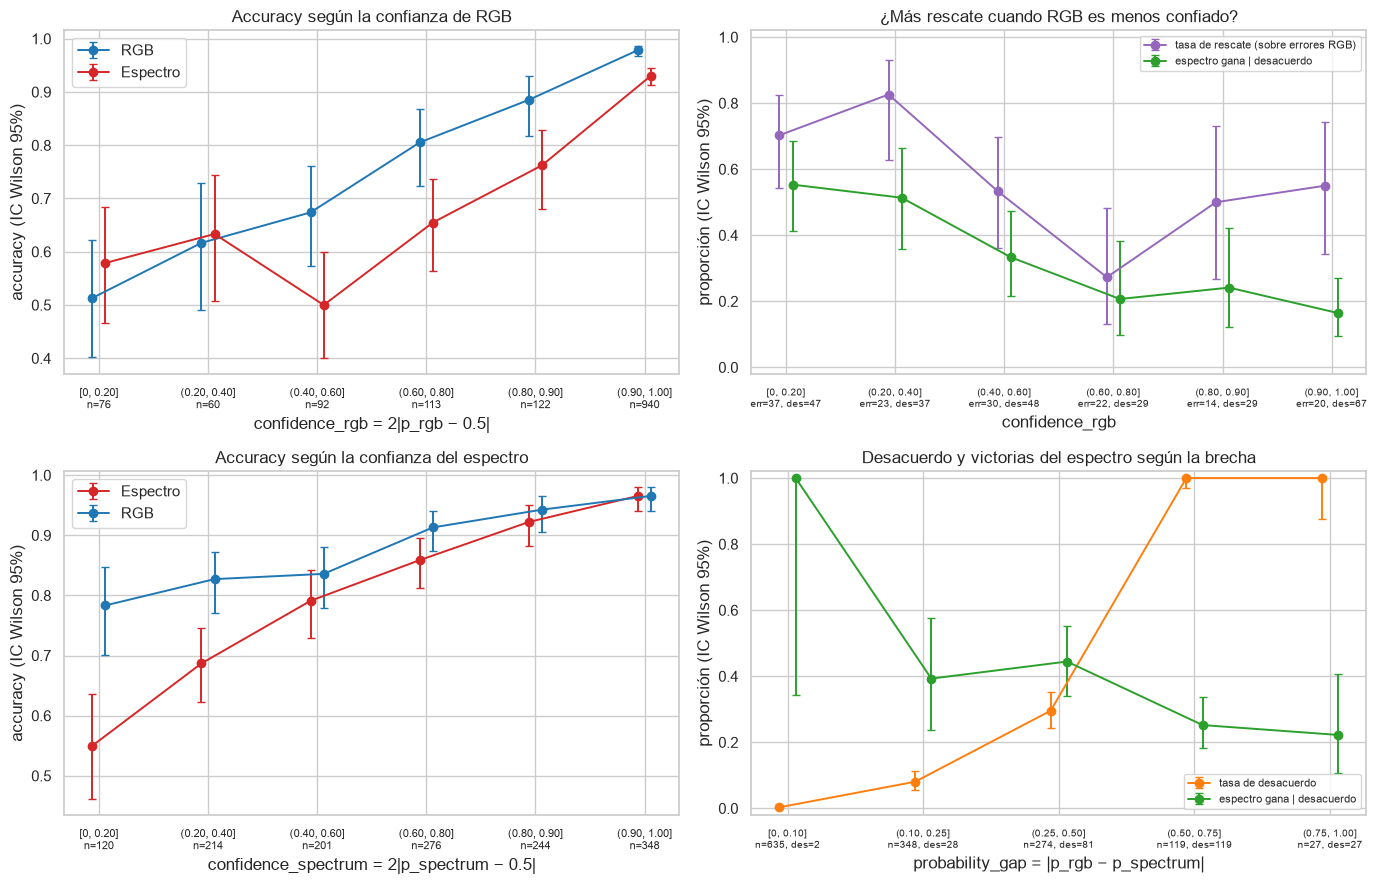

In [11]:
def errbar(ax, x, y, lo, hi, **kw):
    ax.errorbar(x, y, yerr=[np.asarray(y) - np.asarray(lo), np.asarray(hi) - np.asarray(y)], capsize=3, marker="o", lw=1.4, **kw)


fig, axes = plt.subplots(2, 2, figsize=(14, 9))
x = np.arange(len(t_rgb))
ax = axes[0, 0]
errbar(ax, x - 0.06, t_rgb.acc_rgb, t_rgb.acc_rgb_lo, t_rgb.acc_rgb_hi, label="RGB", color="#1f77b4")
errbar(ax, x + 0.06, t_rgb.acc_spectrum, t_rgb.acc_spectrum_lo, t_rgb.acc_spectrum_hi, label="Espectro", color="#d62728")
ax.set_xticks(x); ax.set_xticklabels([f"{b}\nn={n}" for b, n in zip(t_rgb.bin, t_rgb.n)], fontsize=8)
ax.set_xlabel("confidence_rgb = 2|p_rgb − 0.5|"); ax.set_ylabel("accuracy (IC Wilson 95%)")
ax.set_title("Accuracy según la confianza de RGB"); ax.legend()

ax = axes[0, 1]
m = t_rgb.n_errores_rgb > 0
errbar(ax, x[m] - 0.06, t_rgb.tasa_rescate[m], t_rgb.tasa_rescate_lo[m], t_rgb.tasa_rescate_hi[m], label="tasa de rescate (sobre errores RGB)", color="#9467bd")
m2 = t_rgb.n_desacuerdos > 0
errbar(ax, x[m2] + 0.06, t_rgb.esp_gana_en_desacuerdo[m2], t_rgb.esp_gana_lo[m2], t_rgb.esp_gana_hi[m2], label="espectro gana | desacuerdo", color="#2ca02c")
ax.set_xticks(x); ax.set_xticklabels([f"{b}\nerr={e}, des={d}" for b, e, d in zip(t_rgb.bin, t_rgb.n_errores_rgb, t_rgb.n_desacuerdos)], fontsize=7.5)
ax.set_xlabel("confidence_rgb"); ax.set_ylabel("proporción (IC Wilson 95%)"); ax.set_ylim(-0.02, 1.02)
ax.set_title("¿Más rescate cuando RGB es menos confiado?"); ax.legend(fontsize=8)

ax = axes[1, 0]
xs = np.arange(len(t_spec))
errbar(ax, xs - 0.06, t_spec.acc_spectrum, t_spec.acc_spectrum_lo, t_spec.acc_spectrum_hi, label="Espectro", color="#d62728")
errbar(ax, xs + 0.06, t_spec.acc_rgb, t_spec.acc_rgb_lo, t_spec.acc_rgb_hi, label="RGB", color="#1f77b4")
ax.set_xticks(xs); ax.set_xticklabels([f"{b}\nn={n}" for b, n in zip(t_spec.bin, t_spec.n)], fontsize=8)
ax.set_xlabel("confidence_spectrum = 2|p_spectrum − 0.5|"); ax.set_ylabel("accuracy (IC Wilson 95%)")
ax.set_title("Accuracy según la confianza del espectro"); ax.legend()

ax = axes[1, 1]
xg = np.arange(len(t_gap))
errbar(ax, xg - 0.06, t_gap.tasa_desacuerdo, t_gap.tasa_desacuerdo_lo, t_gap.tasa_desacuerdo_hi, label="tasa de desacuerdo", color="#ff7f0e")
m3 = t_gap.n_desacuerdos > 0
errbar(ax, xg[m3] + 0.06, t_gap.esp_gana_en_desacuerdo[m3], t_gap.esp_gana_lo[m3], t_gap.esp_gana_hi[m3], label="espectro gana | desacuerdo", color="#2ca02c")
ax.set_xticks(xg); ax.set_xticklabels([f"{b}\nn={n}, des={d}" for b, n, d in zip(t_gap.bin, t_gap.n, t_gap.n_desacuerdos)], fontsize=7.5)
ax.set_xlabel("probability_gap = |p_rgb − p_spectrum|"); ax.set_ylabel("proporción (IC Wilson 95%)"); ax.set_ylim(-0.02, 1.02)
ax.set_title("Desacuerdo y victorias del espectro según la brecha"); ax.legend(fontsize=8)
fig.tight_layout(); save_fig(fig, "exp2_confianza_desacuerdo"); plt.show()

In [12]:
# ¿Qué modalidad gana cuando son ambas confiadas / cuando RGB es confiado y se equivoca?
dis = dev[dev.disagreement].copy()
dis["rgb_confiado"] = np.where(dis.confidence_rgb >= HIGH_CONF, "RGB confiado", "RGB poco confiado")
dis["spec_confiado"] = np.where(dis.confidence_spectrum >= HIGH_CONF, "Esp. confiado", "Esp. poco confiado")
rows = []
for (a, b), g in dis.groupby(["rgb_confiado", "spec_confiado"]):
    w = int((g.selector_target == 1).sum()); lo, hi = wilson(w, len(g))
    rows.append({"RGB": a, "Espectro": b, "n_desacuerdos": len(g), "gana_espectro": w, "gana_RGB": len(g) - w,
                 "prop_gana_espectro": w / len(g), "IC95_lo": lo, "IC95_hi": hi})
both_tab = pd.DataFrame(rows)
display(Markdown(f"**Desacuerdos según confianza de cada modelo** (confiado = `confidence ≥ {HIGH_CONF}`, es decir p ≤ {(1-HIGH_CONF)/2:.2f} o p ≥ {(1+HIGH_CONF)/2:.2f})"))
display(both_tab)

# Errores de RGB cometidos con alta confianza
hc_err = dev[(~dev.correct_rgb) & (dev.confidence_rgb >= HIGH_CONF)]
all_err = dev[~dev.correct_rgb]
R["rgb_errors"] = len(all_err); R["rgb_hc_errors"] = len(hc_err)
R["rgb_hc_errors_rescued"] = int(hc_err.correct_spectrum.sum()); R["rgb_errors_rescued"] = int(all_err.correct_spectrum.sum())
hc_tab = pd.DataFrame({
    "errores RGB": [len(all_err), len(hc_err), len(all_err) - len(hc_err)],
    "rescatados por el espectro": [int(all_err.correct_spectrum.sum()), int(hc_err.correct_spectrum.sum()), int(all_err.correct_spectrum.sum() - hc_err.correct_spectrum.sum())],
}, index=["todos", f"RGB confiado (≥ {HIGH_CONF})", f"RGB poco confiado (< {HIGH_CONF})"])
hc_tab["tasa de rescate"] = hc_tab["rescatados por el espectro"] / hc_tab["errores RGB"]
display(Markdown("**Errores de RGB y rescate según la confianza de RGB**")); display(hc_tab)
R["rescue_rate_hc"] = hc_tab.iloc[1, 2]; R["rescue_rate_lc"] = hc_tab.iloc[2, 2]
display(Markdown(f"Entre los errores confiados de RGB, la mediana de `confidence_spectrum` es {hc_err.confidence_spectrum.median():.2f}; "
                 f"el espectro también falla en {int((~hc_err.correct_spectrum).sum())} de ellos (errores compartidos con alta confianza de RGB)."))

**Desacuerdos según confianza de cada modelo** (confiado = `confidence ≥ 0.8`, es decir p ≤ 0.10 o p ≥ 0.90)

,RGB,Espectro,n_desacuerdos,gana_espectro,gana_RGB,prop_gana_espectro,IC95_lo,IC95_hi
0,RGB confiado,Esp. confiado,8,2,6,0.2500,0.0715,0.5907
1,RGB confiado,Esp. poco confiado,88,16,72,0.1818,0.1151,0.2751
2,RGB poco confiado,Esp. confiado,27,13,14,0.4815,0.3074,0.6601
3,RGB poco confiado,Esp. poco confiado,134,54,80,0.4030,0.3238,0.4876


**Errores de RGB y rescate según la confianza de RGB**

,errores RGB,rescatados por el espectro,tasa de rescate
todos,146,85,0.5822
RGB confiado (≥ 0.8),34,18,0.5294
RGB poco confiado (< 0.8),112,67,0.5982


Entre los errores confiados de RGB, la mediana de `confidence_spectrum` es 0.54; el espectro también falla en 16 de ellos (errores compartidos con alta confianza de RGB).

In [13]:
# ¿La confianza detecta errores? AUC de confidence como detector de acierto (1 = el modelo acierta)
det = []
for name, y, s in [("RGB: confidence_rgb → acierto RGB", dev.correct_rgb, dev.confidence_rgb),
                   ("Espectro: confidence_spectrum → acierto espectro", dev.correct_spectrum, dev.confidence_spectrum)]:
    a, lo, hi = auc_ci(y.astype(int), s)
    det.append({"detector": name, "n": len(dev), "AUC": a, "IC95_lo": lo, "IC95_hi": hi})
# Entre los errores de RGB: ¿distingue la confianza de RGB los que el espectro rescata?
e = dev[~dev.correct_rgb]
a, lo, hi = auc_ci(e.correct_spectrum.astype(int), e.uncertainty_rgb)
det.append({"detector": "Entre errores RGB: uncertainty_rgb → espectro rescata", "n": len(e), "AUC": a, "IC95_lo": lo, "IC95_hi": hi})
# Entre desacuerdos: ¿la incertidumbre de RGB (o la diferencia de confianzas) predice que gana el espectro?
for nm, s in [("uncertainty_rgb", dis.uncertainty_rgb), ("confidence_spectrum − confidence_rgb", dis.confidence_spectrum - dis.confidence_rgb)]:
    a, lo, hi = auc_ci(dis.selector_target.astype(int), s)
    det.append({"detector": f"Entre desacuerdos: {nm} → gana espectro", "n": len(dis), "AUC": a, "IC95_lo": lo, "IC95_hi": hi})
det = pd.DataFrame(det)
display(det)
R["auc_conf_rgb_detect"] = det.iloc[0].to_dict(); R["auc_conf_spec_detect"] = det.iloc[1].to_dict()
R["auc_unc_rgb_rescue"] = det.iloc[2].to_dict(); R["auc_confdiff_dis"] = det.iloc[4].to_dict(); R["auc_unc_rgb_dis"] = det.iloc[3].to_dict()

,detector,n,AUC,IC95_lo,IC95_hi
0,RGB: confidence_rgb → acierto RGB,1403,0.8775,0.8543,0.9002
1,Espectro: confidence_spectrum → acierto espectro,1403,0.7540,0.7211,0.7859
2,Entre errores RGB: uncertainty_rgb → espectro ...,146,0.6316,0.5410,0.7145
3,Entre desacuerdos: uncertainty_rgb → gana espe...,257,0.6930,0.6195,0.7583
4,Entre desacuerdos: confidence_spectrum − confi...,257,0.6739,0.5994,0.7449


**Interpretación.** Un AUC de 0.5 significa que la confianza no ayuda a detectar errores; valores claramente por encima indican que los errores se concentran donde el modelo está menos seguro. Se reportan con IC bootstrap; si el IC incluye 0.5, no hay evidencia de señal. Los gráficos muestran el tamaño de muestra de cada intervalo: los intervalos extremos de confianza concentran muy pocos errores y sus IC son amplios, por lo que las diferencias entre intervalos adyacentes no deben leerse como tendencias firmes.

La tabla de errores confiados de RGB responde si el espectro rescata *también* los errores que RGB comete con mucha seguridad (el caso que más interesaría a un gate, porque la confianza de RGB no lo delata).

**Limitación:** los IC de Wilson asumen observaciones independientes; las galaxias con varias observaciones MaNGA relacionadas podrían violar levemente esa suposición (no se comprobó aquí).

## 4. Experimento 3: calibración

**Pregunta:** ¿las probabilidades de cada modalidad reflejan su frecuencia real de acierto? ¿Podría una diferencia de escala explicar por qué promediar probabilidades con peso casi igual perjudica?

**Método:** Brier score, log loss, diagrama de confiabilidad (10 intervalos de igual ancho) y ECE como diagnóstico secundario. Se calculan globalmente y por clase verdadera. No se aplica ninguna calibración aprendida.

**Sobre el ECE.** El ECE es el promedio ponderado de `|frecuencia observada − probabilidad media|` por intervalo, así que **depende de cómo se agrupan las probabilidades**: con intervalos de igual ancho, casi todas las galaxias caen en los extremos y el ECE refleja sobre todo esos dos intervalos; con intervalos por cuantiles puede cambiar. Se reportan ambas versiones para mostrar esa sensibilidad. Brier y log loss no dependen de agrupación.

In [14]:
def ece(y, p, bins=ECE_BINS, strategy="uniform"):
    y, p = np.asarray(y), np.asarray(p)
    if strategy == "uniform":
        idx = np.clip((p * bins).astype(int), 0, bins - 1)
    else:
        idx = pd.qcut(p, bins, labels=False, duplicates="drop")
    tot = 0.0
    for b in np.unique(idx):
        m = idx == b
        tot += m.mean() * abs(y[m].mean() - p[m].mean())
    return tot


dev["p_fusion"] = ALPHA_FIXED * dev.p_rgb + (1 - ALPHA_FIXED) * dev.p_spectrum
CAL_MODELS = [("rgb", "ResNet-18 RGB"), ("spectrum", "CNN+atención espectro SL"), ("pop", "MLP poblaciones SL")]
CAL_MODELS += [(m, MODEL_LABELS[m]) for m in ["rgb_cnn", "spec_fov"] if m in MODELS]
dev_cal = dev.copy()


def cal_metrics(df, pcol, y="y_true"):
    p = np.clip(df[pcol].values, 1e-12, 1 - 1e-12)
    yv = df[y].values
    pred = (p >= THRESHOLD).astype(int)
    conf_pred = np.where(pred == 1, p, 1 - p)
    return {"n": len(df), "accuracy": (pred == yv).mean(), "Brier": brier_score_loss(yv, p), "log_loss": log_loss(yv, p, labels=[0, 1]),
            "ECE_uniforme": ece(yv, p), "ECE_cuantiles": ece(yv, p, strategy="quantile"),
            "confianza_media_en_clase_predicha": conf_pred.mean(), "exceso_confianza(conf-acc)": conf_pred.mean() - (pred == yv).mean(),
            "pct_p_en_[.05,.95]": ((p > 0.05) & (p < 0.95)).mean() * 100, "std_logit": np.std(np.log(p / (1 - p)))}


rows = []
for key, nm in CAL_MODELS + [("fusion", f"Fusión fija α={ALPHA_FIXED} (referencia)")]:
    rows.append({"modelo": nm, "subconjunto": "global", **cal_metrics(dev, f"p_{key}")})
cal = pd.DataFrame(rows)
display(Markdown("**Calibración global (validation)**")); display(cal)

rows = []
for key, nm in CAL_MODELS:
    for cls, cn in [(0, "temprana"), (1, "tardía")]:
        g = dev[dev.y_true == cls]
        p = g[f"p_{key}"].clip(1e-12, 1 - 1e-12)
        pred = (p >= THRESHOLD).astype(int)
        rows.append({"modelo": nm, "clase_verdadera": cn, "n": len(g), "accuracy(recall)": (pred == cls).mean(),
                     "P(tardía) media": p.mean(), "Brier": brier_score_loss(g.y_true, p), "log_loss": log_loss(g.y_true, p, labels=[0, 1])})
cal_cls = pd.DataFrame(rows)
display(Markdown("**Calibración por clase verdadera.** `P(tardía) media` debería acercarse a 0 en tempranas y a 1 en tardías si el modelo fuera muy nítido y correcto."))
display(cal_cls)
save_table(pd.concat([cal.assign(clase_verdadera="todas"), cal_cls.assign(subconjunto="por clase")], ignore_index=True), "calibration_metrics")
R["cal"] = cal.set_index("modelo")

**Calibración global (validation)**

,modelo,subconjunto,n,accuracy,Brier,log_loss,ECE_uniforme,ECE_cuantiles,confianza_media_en_clase_predicha,exceso_confianza(conf-acc),"pct_p_en_[.05,.95]",std_logit
0,ResNet-18 RGB,global,1403,0.8959,0.0739,0.2429,0.0263,0.0250,0.9217,0.0258,33.0007,5.4154
1,CNN+atención espectro SL,global,1403,0.8339,0.1230,0.3924,0.0352,0.0311,0.8259,-0.0080,75.1960,2.2433
2,MLP poblaciones SL,global,1403,0.8268,0.1248,0.4032,0.0285,0.0244,0.8395,0.0127,77.0492,2.1544
3,CNN RGB compacta,global,1403,0.8995,0.0746,0.2537,0.0153,0.0117,0.8997,0.0002,44.1910,4.1410
4,CNN1D espectro FoV,global,1403,0.7869,0.1528,0.4747,0.0294,0.0271,0.8040,0.0171,91.6607,1.6453
5,Fusión fija α=0.85 (referencia),global,1403,0.8981,0.0715,0.2311,0.0212,0.0177,0.8960,-0.0021,46.5431,3.3240


**Calibración por clase verdadera.** `P(tardía) media` debería acercarse a 0 en tempranas y a 1 en tardías si el modelo fuera muy nítido y correcto.

,modelo,clase_verdadera,n,accuracy(recall),P(tardía) media,Brier,log_loss
0,ResNet-18 RGB,temprana,529,0.8639,0.1782,0.0998,0.3415
1,ResNet-18 RGB,tardía,874,0.9153,0.8996,0.0583,0.1832
2,CNN+atención espectro SL,temprana,529,0.7864,0.3469,0.1870,0.5913
3,CNN+atención espectro SL,tardía,874,0.8627,0.8134,0.0842,0.2721
4,MLP poblaciones SL,temprana,529,0.7826,0.3328,0.1767,0.5881
5,MLP poblaciones SL,tardía,874,0.8535,0.8097,0.0934,0.2913
6,CNN RGB compacta,temprana,529,0.8677,0.2002,0.1006,0.3555
7,CNN RGB compacta,tardía,874,0.9188,0.8847,0.0588,0.1921
8,CNN1D espectro FoV,temprana,529,0.6503,0.4188,0.2477,0.7417
9,CNN1D espectro FoV,tardía,874,0.8696,0.7835,0.0954,0.3131


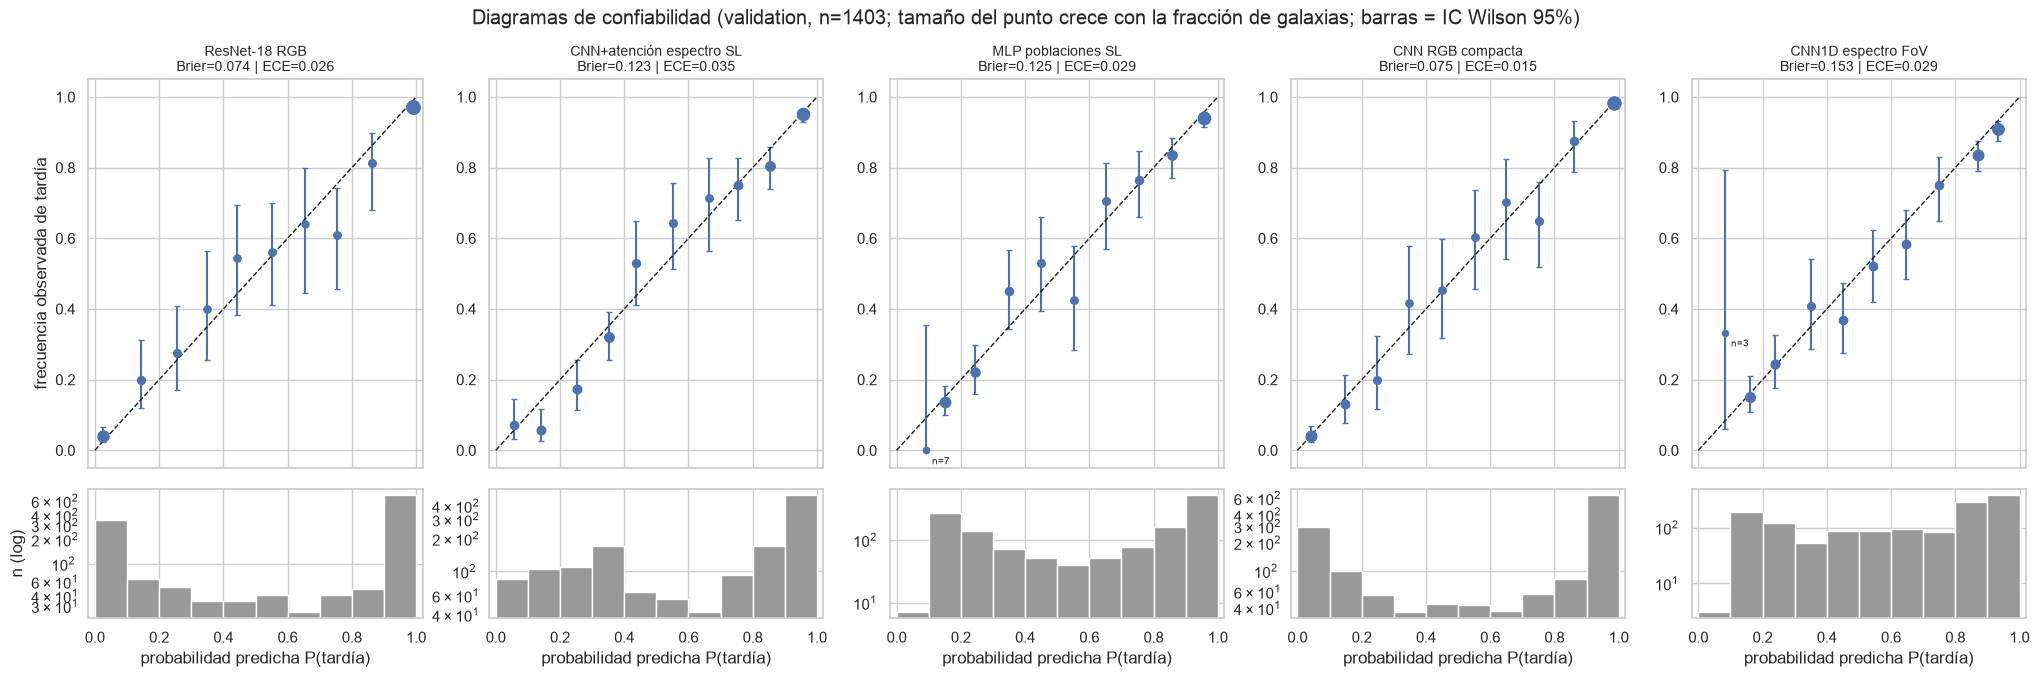

In [15]:
fig = plt.figure(figsize=(5 * len(CAL_MODELS), 7))
gs = fig.add_gridspec(2, len(CAL_MODELS), height_ratios=[3, 1], hspace=0.08)
bins = np.linspace(0, 1, ECE_BINS + 1)
for j, (key, nm) in enumerate(CAL_MODELS):
    ax = fig.add_subplot(gs[0, j]); axh = fig.add_subplot(gs[1, j], sharex=ax)
    p, y = dev[f"p_{key}"].values, dev.y_true.values
    idx = np.clip((p * ECE_BINS).astype(int), 0, ECE_BINS - 1)
    for b in range(ECE_BINS):
        m = idx == b
        if m.sum() == 0:
            continue
        lo, hi = wilson(int(y[m].sum()), int(m.sum()))
        ax.errorbar(p[m].mean(), y[m].mean(), yerr=[[y[m].mean() - lo], [hi - y[m].mean()]], fmt="o", color="C0", ms=4 + 8 * np.sqrt(m.mean()), capsize=2)
        if m.sum() < 15:
            ax.annotate(f"n={m.sum()}", (p[m].mean(), y[m].mean()), fontsize=7, xytext=(4, -10), textcoords="offset points")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_title(f"{nm}\nBrier={cal.set_index('modelo').loc[nm, 'Brier']:.3f} | ECE={cal.set_index('modelo').loc[nm, 'ECE_uniforme']:.3f}", fontsize=10)
    ax.set_ylabel("frecuencia observada de tardía" if j == 0 else ""); ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.05, 1.05)
    plt.setp(ax.get_xticklabels(), visible=False)
    axh.hist(p, bins=bins, color="0.6"); axh.set_yscale("log"); axh.set_xlabel("probabilidad predicha P(tardía)")
    axh.set_ylabel("n (log)" if j == 0 else "")
fig.suptitle(f"Diagramas de confiabilidad (validation, n={len(dev)}; tamaño del punto crece con la fracción de galaxias; barras = IC Wilson 95%)", y=0.98)
save_fig(fig, "exp3_reliability"); plt.show()

In [16]:
# Calibración *en los desacuerdos*: ¿qué tan seguro está el ganador y el perdedor?
rows = []
for m, nm in [("rgb", "RGB"), ("spectrum", "Espectro")]:
    conf_pred = np.where(dis[f"pred_{m}"] == 1, dis[f"p_{m}"], 1 - dis[f"p_{m}"])
    acc = dis[f"correct_{m}"].mean()
    rows.append({"modelo": nm, "n_desacuerdos": len(dis), "accuracy en desacuerdos": acc,
                 "prob. media asignada a su clase predicha": conf_pred.mean(), "exceso de confianza": conf_pred.mean() - acc,
                 "prob. media cuando acierta": conf_pred[dis[f"correct_{m}"].values].mean(),
                 "prob. media cuando falla": conf_pred[~dis[f"correct_{m}"].values].mean()})
cal_dis = pd.DataFrame(rows)
display(Markdown("**Confianza vs acierto dentro de los desacuerdos** (la clase predicha y su probabilidad)")); display(cal_dis)
R["cal_dis"] = cal_dis.set_index("modelo")

# Diferencia pareada de Brier espectro - RGB (bootstrap)
d_brier = (dev.p_spectrum - dev.y_true) ** 2 - (dev.p_rgb - dev.y_true) ** 2
bt = d_brier.values[rng.integers(0, len(dev), (N_BOOT, len(dev)))].mean(axis=1)
R["brier_diff"] = (d_brier.mean(), *np.percentile(bt, [2.5, 97.5]))
print(f"Δ Brier (espectro − RGB) = {R['brier_diff'][0]:+.4f}  IC95% bootstrap [{R['brier_diff'][1]:+.4f}, {R['brier_diff'][2]:+.4f}]")

**Confianza vs acierto dentro de los desacuerdos** (la clase predicha y su probabilidad)

,modelo,n_desacuerdos,accuracy en desacuerdos,prob. media asignada a su clase predicha,exceso de confianza,prob. media cuando acierta,prob. media cuando falla
0,RGB,257,0.6693,0.7920,0.1227,0.8284,0.7181
1,Espectro,257,0.3307,0.7186,0.3879,0.7375,0.7093


Δ Brier (espectro − RGB) = +0.0490  IC95% bootstrap [+0.0374, +0.0611]


**Interpretación.** Si un modelo asigna probabilidades más extremas de lo que justifica su accuracy (exceso de confianza positivo), en un promedio simple domina sobre el otro aunque no sea más fiable. La tabla de desacuerdos aísla ese efecto en el subconjunto donde las dos modalidades chocan: compara la probabilidad que cada una asigna a su propia predicción con su accuracy real allí. Los diagramas muestran dónde se desvía cada modelo de la diagonal; los histogramas inferiores (escala log) recuerdan cuántas galaxias hay realmente en cada tramo.

**Qué *no* se concluye:** que "calibrar" resolvería el problema. Una diferencia de escala es una hipótesis plausible para el mal rendimiento del promedio simple, pero no se probó aplicando calibración (eso requeriría un protocolo sin `test` y queda para otra fase).

**Limitación:** con unas pocas galaxias en los intervalos intermedios, los puntos de esa zona del diagrama tienen IC muy amplios; el ECE es dominado por los intervalos extremos.

# PARTE II — Predicción de confiabilidad relativa

## 5. Experimento 4: análisis restringido a desacuerdos

**Pregunta:** cuando RGB y espectro predicen clases distintas, ¿podemos anticipar cuál tiene razón?

**Definición del target.** En un desacuerdo binario exactamente uno acierta, así que
`selector_target = (y_pred_spectrum == y_true)`: **0** = RGB tiene razón, **1** = el espectro tiene razón. Solo se usa para entrenar/evaluar el selector, nunca como característica.

**Una observación importante.** Dentro de un desacuerdo, "el espectro tiene razón" equivale a "la clase verdadera es la que predice el espectro". Por tanto, predecir `selector_target` es, en el fondo, clasificar la morfología de esas galaxias difíciles usando las probabilidades de ambos modelos (y quizá otras variables). Esto no invalida el diseño, pero implica que cualquier señal debe interpretarse como "información útil para resolver casos en los que los modelos chocan", y que la dirección del desacuerdo (quién predice tardía) importa.

**Método:** conteo de victorias con IC de Wilson; comparación de distribuciones de `p_rgb`, `p_spectrum`, `confidence_*` y `probability_gap` entre ambos grupos con tamaño de efecto (AUC univariado, Cliff's δ) y Mann-Whitney con corrección de Holm (5 comparaciones).

In [17]:
n_dis = len(dis)
w_spec = int((dis.selector_target == 1).sum()); w_rgb = n_dis - w_spec
rows = []
for nm, k in [("gana RGB", w_rgb), ("gana espectro", w_spec)]:
    lo, hi = wilson(k, n_dis)
    rows.append({"resultado": nm, "n": k, "proporción": k / n_dis, "IC95_lo": lo, "IC95_hi": hi})
win_tab = pd.DataFrame(rows)
display(Markdown(f"**Desacuerdos en {DEV_SPLIT}: {n_dis} de {len(dev)} galaxias ({n_dis/len(dev):.1%}).**"))
display(win_tab)
R.update(n_dis=n_dis, w_spec=w_spec, w_rgb=w_rgb, n_dev=len(dev))
R["win_rate_spec"] = (w_spec / n_dis, *wilson(w_spec, n_dis))

rows = []
for d_, g in dis.groupby("direction"):
    w = int((g.selector_target == 1).sum()); lo, hi = wilson(w, len(g))
    rows.append({"dirección del desacuerdo": d_, "n": len(g), "gana_espectro": w, "gana_RGB": len(g) - w,
                 "prop_gana_espectro": w / len(g), "IC95_lo": lo, "IC95_hi": hi, "frac_tardía_real": g.y_true.mean()})
dir_tab = pd.DataFrame(rows)
display(Markdown("**Victorias según la dirección del desacuerdo.** Si en una dirección gana casi siempre el mismo modelo, una regla de 'confía en quien predice X' ya sería un baseline fuerte."))
display(dir_tab)
R["dir_tab"] = dir_tab

**Desacuerdos en validation: 257 de 1403 galaxias (18.3%).**

,resultado,n,proporción,IC95_lo,IC95_hi
0,gana RGB,172,0.6693,0.6096,0.7239
1,gana espectro,85,0.3307,0.2761,0.3904


**Victorias según la dirección del desacuerdo.** Si en una dirección gana casi siempre el mismo modelo, una regla de 'confía en quien predice X' ya sería un baseline fuerte.

,dirección del desacuerdo,n,gana_espectro,gana_RGB,prop_gana_espectro,IC95_lo,IC95_hi,frac_tardía_real
0,RGB tardía / Esp. temprana,131,44,87,0.3359,0.2607,0.4204,0.6641
1,RGB temprana / Esp. tardía,126,41,85,0.3254,0.2498,0.4113,0.3254


**Probabilidades y confianzas: gana RGB (0) vs gana espectro (1)**. `AUC_univariado` = P(valor en 'gana espectro' > valor en 'gana RGB'); 0.5 = distribuciones totalmente solapadas.

,variable,grupo,n_gana_rgb,n_gana_espectro,mediana_gana_rgb,mediana_gana_espectro,AUC_univariado,cliff_delta,cohen_d,p_mw,p_holm
0,p_rgb,probabilidades,172,85,0.5118,0.5023,0.5199,0.0398,0.0522,0.6044,1.0000
1,p_spectrum,probabilidades,172,85,0.4865,0.4660,0.4798,-0.0405,-0.0523,0.5981,1.0000
2,confidence_rgb,probabilidades,172,85,0.7729,0.3866,0.3070,-0.3859,-0.7158,0.0000,0.0000
3,confidence_spectrum,probabilidades,172,85,0.3595,0.4368,0.5614,0.1228,0.2081,0.1094,0.3283
4,probability_gap,probabilidades,172,85,0.5549,0.4664,0.3777,-0.2446,-0.4282,0.0014,0.0057


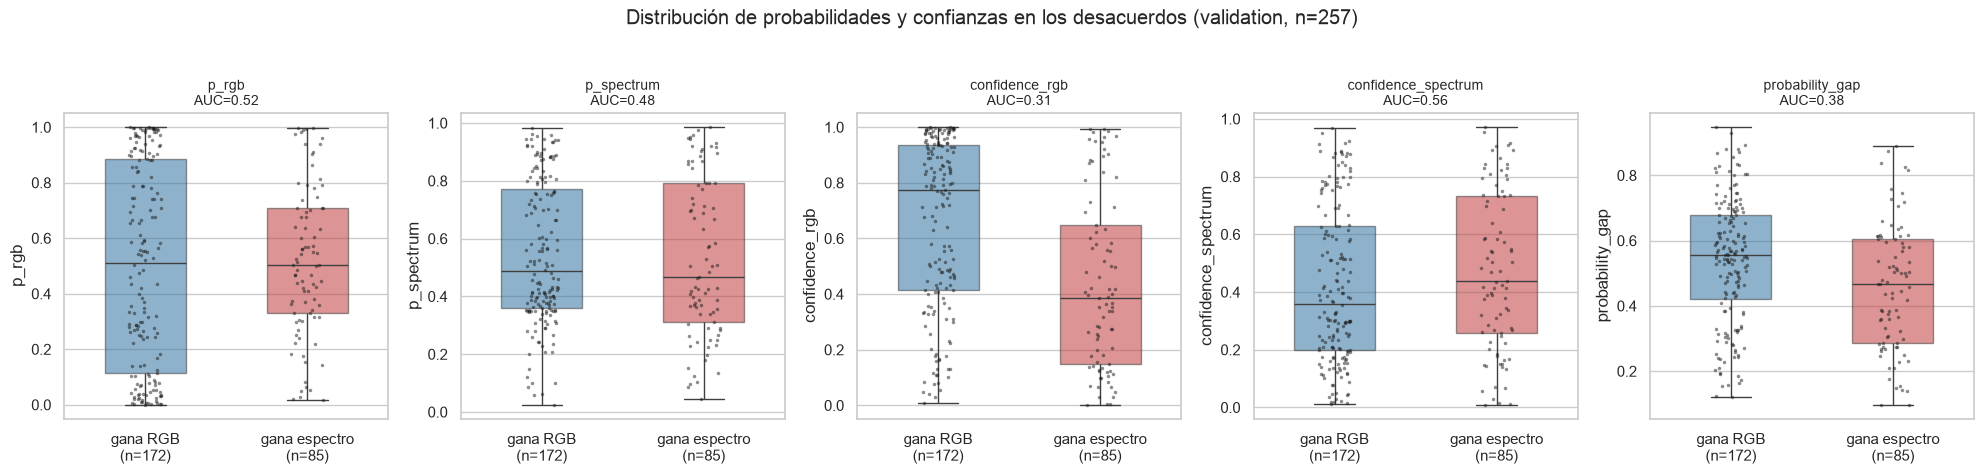

In [18]:
DIS_VARS = ["p_rgb", "p_spectrum", "confidence_rgb", "confidence_spectrum", "probability_gap"]


def compare_groups(df, variables, group_col="selector_target", min_n=5):
    # tamaño de efecto y prueba de Mann-Whitney entre grupo 1 (gana espectro) y grupo 0 (gana RGB)
    rows = []
    for v in variables:
        if v not in df.columns:
            rows.append({"variable": v, "disponible": False}); continue
        a = df.loc[df[group_col] == 0, v].dropna(); b = df.loc[df[group_col] == 1, v].dropna()
        row = {"variable": v, "grupo": VAR_GROUPS.get(v, "probabilidades"), "disponible": True, "n_gana_rgb": len(a), "n_gana_espectro": len(b),
               "mediana_gana_rgb": a.median(), "mediana_gana_espectro": b.median()}
        if len(a) >= min_n and len(b) >= min_n:
            u = stats.mannwhitneyu(b, a, alternative="two-sided")
            auc = u.statistic / (len(a) * len(b))
            sd = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
            row.update(AUC_univariado=auc, cliff_delta=2 * auc - 1, cohen_d=(b.mean() - a.mean()) / sd if sd > 0 else np.nan, p_mw=u.pvalue)
        else:
            row.update(AUC_univariado=np.nan, cliff_delta=np.nan, cohen_d=np.nan, p_mw=np.nan)
        rows.append(row)
    out = pd.DataFrame(rows)
    out["p_holm"] = holm(out.p_mw.values) if "p_mw" in out else np.nan
    return out


cmp_prob = compare_groups(dis, DIS_VARS)
display(Markdown("**Probabilidades y confianzas: gana RGB (0) vs gana espectro (1)**. `AUC_univariado` = P(valor en 'gana espectro' > valor en 'gana RGB'); 0.5 = distribuciones totalmente solapadas."))
display(cmp_prob.drop(columns=["disponible"]))
R["cmp_prob"] = cmp_prob.set_index("variable")

fig, axes = plt.subplots(1, 5, figsize=(20, 4.6))
pal = {0: "#1f77b4", 1: "#d62728"}
dis["ganador"] = dis.selector_target.map({0: "gana RGB", 1: "gana espectro"})
for ax, v in zip(axes, DIS_VARS):
    sns.boxplot(data=dis, x="ganador", y=v, order=["gana RGB", "gana espectro"], palette=[pal[0], pal[1]], showfliers=False, width=0.5, ax=ax, boxprops=dict(alpha=0.55))
    sns.stripplot(data=dis, x="ganador", y=v, order=["gana RGB", "gana espectro"], color="k", size=2.5, alpha=0.5, ax=ax)
    ax.set_xticks([0, 1]); ax.set_xticklabels([f"gana RGB\n(n={w_rgb})", f"gana espectro\n(n={w_spec})"]); ax.set_xlabel("")
    ax.set_title(v + f"\nAUC={cmp_prob.set_index('variable').loc[v, 'AUC_univariado']:.2f}", fontsize=10)
fig.suptitle(f"Distribución de probabilidades y confianzas en los desacuerdos (validation, n={n_dis})", y=1.03)
fig.tight_layout(); save_fig(fig, "exp4_distribuciones_desacuerdos"); plt.show()

**Pregunta clave: ¿hay separación visible o las distribuciones se solapan ampliamente?** Los diagramas de caja con los puntos individuales y el AUC univariado responden de forma directa: un AUC cercano a 0.5 y cajas que se traslapan indican que esa variable por sí sola no separa los grupos; un AUC alejado de 0.5 (en cualquier dirección) indica algo de separación. La columna `p_holm` es el p-valor ajustado por 5 comparaciones; un p-valor pequeño **no** implica una señal útil para predecir (puede haber separación estadística con solape grande).

**Recordatorio:** `p_rgb` y `p_spectrum` están acopladas por construcción en los desacuerdos (si una está sobre 0.5, la otra está bajo 0.5), y su relación con el target depende de la dirección del desacuerdo (tabla anterior). Por eso la comparación agregada puede ocultar patrones que van en sentidos opuestos según la dirección.

**Limitación:** subconjunto pequeño (n = número de desacuerdos), un solo split de desarrollo.

## 6. Experimento 5: propiedades asociadas con el rescate

**Pregunta:** ¿las características observacionales y físicas distinguen a las galaxias donde el espectro gana?

**Hipótesis (plausibles, no confirmadas):** (A) el espectro podría ganar en galaxias más lejanas o pequeñas (donde la imagen pierde resolución); (B) los ajustes STARLIGHT de peor calidad podrían hacer menos fiable al espectro; (C) ciertas poblaciones (p. ej. con mucha fracción joven o alta dispersión de velocidades) podrían resolver casos donde la imagen es ambigua.

**Método.** Solo en el subconjunto de desacuerdos. Por variable: n válido, mediana por grupo, tamaño de efecto sencillo (Cliff's δ y d de Cohen) y Mann-Whitney **con corrección de Holm sobre todas las variables** (14 comparaciones). No se seleccionan variables por significancia para luego reportar el selector: las variables del selector (§7) están fijadas a priori. Como control adicional, se repite la comparación separando por *dirección* del desacuerdo, porque la relación de una propiedad física con el target puede invertirse según qué modelo diga "tardía".

In [19]:
avail = [v for v in VARS_OBS + VARS_QUALITY + VARS_PHYS if v in dis.columns]
cmp_props = compare_groups(dis, VARS_OBS + VARS_QUALITY + VARS_PHYS)
cmp_props["abs_delta"] = cmp_props.cliff_delta.abs()
cmp_props = cmp_props.sort_values(["grupo", "abs_delta"], ascending=[True, False]).drop(columns="abs_delta").reset_index(drop=True)
display(cmp_props.drop(columns=["disponible"]))

# Por dirección del desacuerdo (control de confusión por dirección)
dir_cmp = []
for d_, g in dis.groupby("direction"):
    t = compare_groups(g, VARS_OBS + VARS_QUALITY + VARS_PHYS)
    t["direccion"] = d_
    dir_cmp.append(t)
dir_cmp = pd.concat(dir_cmp, ignore_index=True)
wide_dir = dir_cmp.pivot(index="variable", columns="direccion", values=["cliff_delta", "p_holm"]).reindex(VARS_OBS + VARS_QUALITY + VARS_PHYS)
n_dir = dir_cmp.groupby("direccion")[["n_gana_rgb", "n_gana_espectro"]].first()
display(Markdown("**Misma comparación separada por dirección del desacuerdo** (n pequeños: úsese solo como control). "
                 "n (gana RGB / gana espectro): " + "; ".join(f"{d_}: {int(r.n_gana_rgb)} / {int(r.n_gana_espectro)}" for d_, r in n_dir.iterrows())))
display(wide_dir)

sfc = pd.concat([cmp_props.assign(subconjunto="todos los desacuerdos"),
                 dir_cmp.rename(columns={"direccion": "subconjunto"})], ignore_index=True)
save_table(sfc, "starlight_feature_comparison")
R["cmp_props"] = cmp_props.set_index("variable")
R["n_props_sig"] = int((cmp_props.p_holm < 0.05).sum())

,variable,grupo,n_gana_rgb,n_gana_espectro,mediana_gana_rgb,mediana_gana_espectro,AUC_univariado,cliff_delta,cohen_d,p_mw,p_holm
0,LogMass,A. observacional,172,85,10.2336,10.2372,0.4701,-0.0598,-0.0994,0.4362,1.0000
1,PETRO_TH90,A. observacional,172,85,10.9123,10.3348,0.4739,-0.0521,0.0527,0.4973,1.0000
2,nsa_z,A. observacional,172,85,0.0389,0.0371,0.4856,-0.0289,-0.1090,0.7073,1.0000
3,sn_window,B. calidad espectral,172,85,29.0980,31.0250,0.5863,0.1726,0.1908,0.0244,0.3422
4,adev_pct,B. calidad espectral,172,85,3.2214,3.0691,0.4749,-0.0502,-0.0647,0.5133,1.0000
5,chi2_nl_eff,B. calidad espectral,172,85,0.9866,1.0073,0.5143,0.0286,0.0591,0.7100,1.0000
6,z_mean_light,C. física,172,85,0.0202,0.0175,0.4448,-0.1104,-0.1799,0.1503,1.0000
7,av_mag,C. física,172,85,0.2069,0.1652,0.4580,-0.0839,-0.1604,0.2742,1.0000
8,mass_old_ge_1gyr_pct,C. física,172,85,99.4473,99.7672,0.5348,0.0696,0.0738,0.3644,1.0000
9,z_mean_mass,C. física,172,85,0.0189,0.0185,0.4667,-0.0666,-0.1326,0.3855,1.0000


**Misma comparación separada por dirección del desacuerdo** (n pequeños: úsese solo como control). n (gana RGB / gana espectro): RGB tardía / Esp. temprana: 87 / 44; RGB temprana / Esp. tardía: 85 / 41

cliff_delta                                                p_holm                           
direccion                 RGB tardía / Esp. temprana RGB temprana / Esp. tardía RGB tardía / Esp. temprana RGB temprana / Esp. tardía
variable                                                                                                                             
nsa_z                                         0.0214                    -0.0846                     1.0000                     1.0000
PETRO_TH90                                   -0.0044                    -0.1260                     1.0000                     1.0000
LogMass                                      -0.0110                    -0.1036                     1.0000                     1.0000
sn_window                                     0.0695                     0.2849                     1.0000                     0.1373
adev_pct                                      0.0465                    -0.1352                     1.0000                     1.0000
chi2_nl_eff                                  -0.0084                     0.0703                     1.0000                     1.0000
age_mean_light_gyr                            0.0512                     0.0387                     1.0000                     1.0000
age_mean_mass_gyr                             0.0768                     0.0387                     1.0000                     1.0000
light_young_lt_100myr_pct                     0.0298                    -0.0422                     1.0000                     1.0000
mass_old_ge_1gyr_pct                          0.0878                     0.0560                     1.0000                     1.0000
z_mean_light                                  0.0016                    -0.2098                     1.0000                     0.7457
z_mean_mass                                   0.0141                    -0.1369                     1.0000                     1.0000
vd_kms                                        0.0645                    -0.1179                     1.0000                     1.0000
av_mag                                       -0.1460                    -0.0663                     1.0000                     1.0000

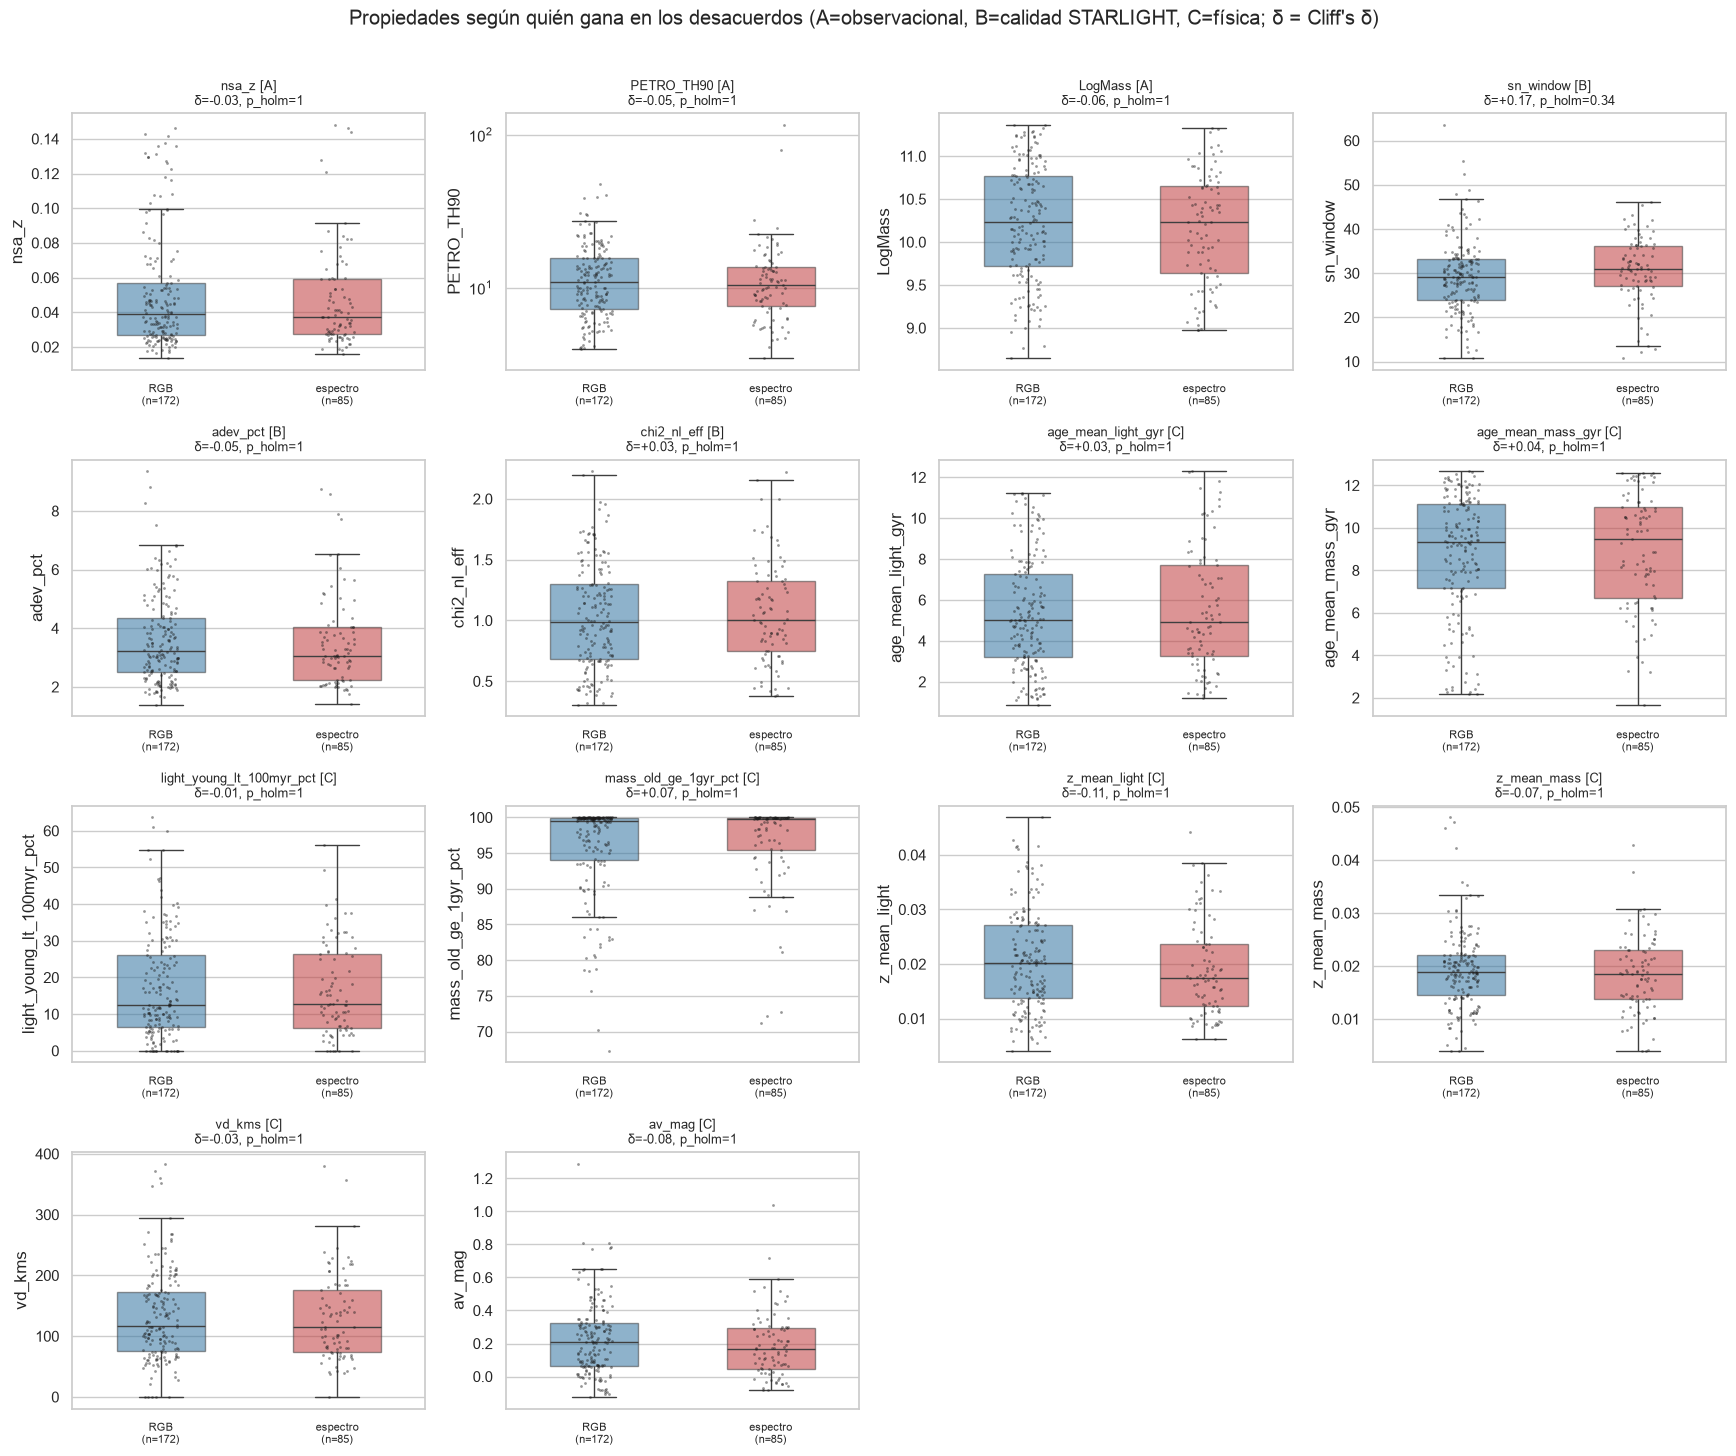

In [20]:
vs = [v for v in VARS_OBS + VARS_QUALITY + VARS_PHYS if v in dis.columns]
ncol = 4; nrow = int(np.ceil(len(vs) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.4 * ncol, 3.6 * nrow))
for ax, v in zip(axes.ravel(), vs):
    sns.boxplot(data=dis, x="ganador", y=v, order=["gana RGB", "gana espectro"], palette=[pal[0], pal[1]], showfliers=False, width=0.5, ax=ax, boxprops=dict(alpha=0.55))
    sns.stripplot(data=dis, x="ganador", y=v, order=["gana RGB", "gana espectro"], color="k", size=2, alpha=0.45, ax=ax)
    x_ = dis[v].dropna()
    if (x_ > 0).all() and x_.skew() > 2:
        ax.set_yscale("log")
    r_ = cmp_props.set_index("variable").loc[v]
    ax.set_title(f"{v} [{r_.grupo[0]}]\nδ={r_.cliff_delta:+.2f}, p_holm={r_.p_holm:.2g}", fontsize=9)
    ax.set_xlabel(""); ax.set_xticks([0, 1]); ax.set_xticklabels([f"RGB\n(n={int(r_.n_gana_rgb)})", f"espectro\n(n={int(r_.n_gana_espectro)})"], fontsize=8)
for ax in axes.ravel()[len(vs):]:
    ax.axis("off")
fig.suptitle("Propiedades según quién gana en los desacuerdos (A=observacional, B=calidad STARLIGHT, C=física; δ = Cliff's δ)", y=1.01)
fig.tight_layout(); save_fig(fig, "exp5_propiedades_ganador"); plt.show()

**Interpretación.** El tamaño de efecto (δ) importa más que el p-valor: con tan pocos desacuerdos solo detectaríamos efectos de tamaño moderado a grande. Si ninguna variable sobrevive a la corrección de Holm, eso **no demuestra ausencia** de asociación (poca potencia), solo que esta muestra no la respalda. Si alguna sobrevive, se trata de una asociación descriptiva, no causal; además las variables STARLIGHT están correlacionadas entre sí (edad, fracción joven y masa vieja miden aspectos relacionados), por lo que no son señales independientes.

Las variables de calidad (`sn_window`, `adev_pct`, `chi2_nl_eff`) describen el ajuste y los datos; no se asume que valores altos o bajos signifiquen mayor fiabilidad morfológica. Las variables físicas derivan del mismo espectro, así que no constituyen evidencia independiente sobre la fiabilidad del modelo espectral.

,grupo,n_galaxias,acc_rgb,acc_espectro,n_desacuerdos,tasa_desacuerdo,gana_espectro,prop_gana_espectro,IC95_lo,IC95_hi,interpretable
0,E (Ttype -5),234,0.9701,0.8761,32,0.1368,5,0.1562,0.0686,0.3175,True
1,S0 (Ttype -2),200,0.8450,0.7550,56,0.2800,19,0.3393,0.2292,0.4700,True
2,S0a (Ttype 0),95,0.6421,0.6316,41,0.4316,20,0.4878,0.3425,0.6352,True
3,Tardía frontera (Ttype 1),146,0.6781,0.6096,60,0.4110,25,0.4167,0.3006,0.5427,True
4,Tardía (Ttype 2),158,0.8797,0.7405,42,0.2658,10,0.2381,0.1348,0.3853,True
5,Tardía (Ttype ≥ 3),570,0.9860,0.9614,26,0.0456,6,0.2308,0.1103,0.4205,True


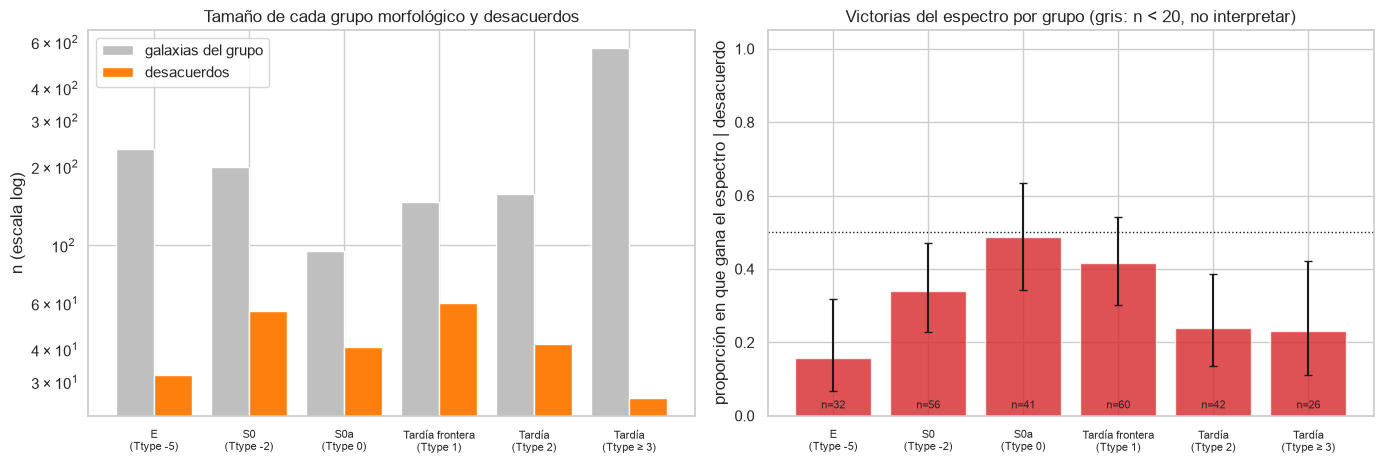

In [21]:
# Ttype: SOLO para interpretar; nunca como predictor
def ttype_group(t):
    if t == -5: return "E (Ttype -5)"
    if t == -2: return "S0 (Ttype -2)"
    if t == 0: return "S0a (Ttype 0)"
    if t == 1: return "Tardía frontera (Ttype 1)"
    if t == 2: return "Tardía (Ttype 2)"
    return "Tardía (Ttype ≥ 3)" if t >= 3 else np.nan


TT_ORDER = ["E (Ttype -5)", "S0 (Ttype -2)", "S0a (Ttype 0)", "Tardía frontera (Ttype 1)", "Tardía (Ttype 2)", "Tardía (Ttype ≥ 3)"]
dev["ttype_group"] = dev.Ttype.map(ttype_group)
dis = dev[dev.disagreement].copy()
dis["ganador"] = dis.selector_target.map({0: "gana RGB", 1: "gana espectro"})

rows = []
for g_ in TT_ORDER:
    a = dev[dev.ttype_group == g_]; b = dis[dis.ttype_group == g_]
    w = int((b.selector_target == 1).sum()); lo, hi = wilson(w, len(b))
    rows.append({"grupo": g_, "n_galaxias": len(a), "acc_rgb": a.correct_rgb.mean(), "acc_espectro": a.correct_spectrum.mean(),
                 "n_desacuerdos": len(b), "tasa_desacuerdo": len(b) / len(a) if len(a) else np.nan,
                 "gana_espectro": w, "prop_gana_espectro": w / len(b) if len(b) else np.nan, "IC95_lo": lo, "IC95_hi": hi,
                 "interpretable": len(b) >= MIN_GROUP})
tt = pd.DataFrame(rows)
display(tt)
R["tt"] = tt
save_table(tt, "ttype_desacuerdos")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
x = np.arange(len(tt))
ax = axes[0]
ax.bar(x - 0.2, tt.n_galaxias, 0.4, color="0.75", label="galaxias del grupo")
ax.bar(x + 0.2, tt.n_desacuerdos, 0.4, color="#ff7f0e", label="desacuerdos")
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels([g.replace(" (", "\n(") for g in tt.grupo], fontsize=8); ax.set_ylabel("n (escala log)")
ax.set_title("Tamaño de cada grupo morfológico y desacuerdos"); ax.legend()
ax = axes[1]
m = tt.n_desacuerdos > 0
colors = ["#d62728" if i else "#bbbbbb" for i in tt.interpretable[m]]
ax.bar(x[m], tt.prop_gana_espectro[m], color=colors, alpha=0.8)
ax.errorbar(x[m], tt.prop_gana_espectro[m], yerr=[tt.prop_gana_espectro[m] - tt.IC95_lo[m], tt.IC95_hi[m] - tt.prop_gana_espectro[m]], fmt="none", color="k", capsize=3)
for xi, r in zip(x, tt.itertuples()):
    ax.text(xi, 0.02, f"n={r.n_desacuerdos}", ha="center", fontsize=8)
ax.axhline(0.5, color="k", ls=":", lw=1); ax.set_ylim(0, 1.05)
ax.set_xticks(x); ax.set_xticklabels([g.replace(" (", "\n(") for g in tt.grupo], fontsize=8)
ax.set_ylabel("proporción en que gana el espectro | desacuerdo"); ax.set_title(f"Victorias del espectro por grupo (gris: n < {MIN_GROUP}, no interpretar)")
fig.tight_layout(); save_fig(fig, "exp5_ttype"); plt.show()

**Interpretación.** El gráfico de la derecha muestra, por tipo morfológico, en qué proporción de los desacuerdos gana el espectro, con IC de Wilson; las barras grises tienen menos de `MIN_GROUP` desacuerdos y no se interpretan. Nótese que la etiqueta binaria es función de `Ttype` (≥ 1 → tardía), así que dentro de cada grupo morfológico la clase verdadera es casi constante: el que gane el espectro en un grupo significa, en la práctica, que acierta la clase correspondiente a ese grupo. Esto refuerza que `Ttype` no puede ser un predictor: contiene la etiqueta.

**Limitación:** los grupos de frontera (Ttype 0 y 1) son los que más desacuerdos aportan; los grupos extremos tienen muy pocos desacuerdos y sus IC son muy amplios.

# PARTE III — Selector exploratorio

## 7. Experimento 6: ¿podemos aprender a elegir la modalidad?

Único experimento que entrena un modelo, y solo tabular y pequeño. **No se reentrena ninguna red.**

**Objetivo:** predecir `selector_target` (1 = gana el espectro) entre los desacuerdos de `validation`.

| Variante | Qué es | Entradas |
|---|---|---|
| **S0** | Baseline mayoritario: siempre RGB | — |
| **S1** | Regla de confianza: elegir el modelo con mayor `2·|p−0.5|` (sin ajuste) | `p_rgb`, `p_spectrum` |
| **S2min** | Logística mínima | `p_rgb`, `p_spectrum` |
| **S2** | Logística con probabilidades y transformaciones (redundantes: son funciones deterministas de las anteriores) | + `confidence_*`, `probability_gap` |
| **S3** | + contexto observacional | + `nsa_z`, `PETRO_TH90`, `LogMass` |
| **S4** | + calidad espectral | + `sn_window`, `adev_pct`, `chi2_nl_eff` |
| **S5** | + subconjunto físico pequeño | + `age_mean_light_gyr`, `light_young_lt_100myr_pct`, `vd_kms` |

**Validación:** `StratifiedKFold(5, shuffle=True, random_state=42)` solo sobre los desacuerdos de `validation`. En cada fold, dentro de un `Pipeline`: imputación por mediana → estandarización → regresión logística L2 (`C=1`, `class_weight="balanced"`), todo ajustado únicamente con el fold de entrenamiento. Se guardan las probabilidades *out-of-fold* (OOF).

**Hipótesis nula implícita:** el baseline "siempre RGB" es difícil de superar en accuracy, porque RGB gana en la mayoría de los desacuerdos. Por eso se reportan métricas balanceadas.

> **Advertencia obligatoria.** Estas predicciones OOF corresponden *únicamente al selector*. Las redes base **no** fueron reentrenadas por validación cruzada: sus pesos ya vieron `train`, y sus checkpoints se eligieron con `validation`. Este experimento es un **diagnóstico exploratorio**, no una validación definitiva de una arquitectura multimodal.

In [22]:
def make_pipeline(class_weight="balanced"):
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler()),
                     ("clf", LogisticRegression(C=LOGREG_C, class_weight=class_weight, max_iter=2000))])


def get_folds(y, seed=SEED, n_splits=N_FOLDS):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    fold = np.full(len(y), -1)
    for k, (_, te) in enumerate(skf.split(np.zeros(len(y)), y)):
        fold[te] = k
    return fold


def cv_logistic(X, y, features, seed=SEED, class_weight="balanced"):
    # imputación, escalado y ajuste SOLO con el fold de entrenamiento (Pipeline); devuelve P(gana espectro) fuera de fold
    y = np.asarray(y)
    fold = get_folds(y, seed)
    oof = np.full(len(y), np.nan)
    for k in range(N_FOLDS):
        tr, te = fold != k, fold == k
        pipe = make_pipeline(class_weight).fit(X.loc[tr, features], y[tr])
        oof[te] = pipe.predict_proba(X.loc[te, features])[:, 1]
    return oof, fold


def sel_metrics(y, choice, score=None):
    # y: 1 = gana espectro. choice: 1 = el selector elige espectro
    y, choice = np.asarray(y), np.asarray(choice)
    cm = confusion_matrix(y, choice, labels=[0, 1])
    out = {"n": len(y), "accuracy": (y == choice).mean(), "balanced_accuracy": balanced_accuracy_score(y, choice),
           "macro_F1": f1_score(y, choice, average="macro", labels=[0, 1], zero_division=0),
           "recall_gana_espectro": recall_score(y, choice, pos_label=1, zero_division=0),
           "precision_gana_espectro": precision_score(y, choice, pos_label=1, zero_division=0),
           "TN(RGB→RGB)": cm[0, 0], "FP(RGB→Esp)": cm[0, 1], "FN(Esp→RGB)": cm[1, 0], "TP(Esp→Esp)": cm[1, 1]}
    out["roc_auc"] = roc_auc_score(y, score) if score is not None and len(np.unique(y)) == 2 and np.std(score) > 0 else np.nan
    return out


# Panel de desacuerdos y folds (la asignación a folds es la misma para todas las variantes)
dis = dis.reset_index(drop=True)
y_dis = dis.selector_target.astype(int).values
folds = get_folds(y_dis)
print(f"Desacuerdos: {len(dis)} | gana espectro: {int(y_dis.sum())} ({y_dis.mean():.1%}) | gana RGB: {int((1-y_dis).sum())}")
print("Tamaño de cada fold:", np.bincount(folds).tolist(), "| positivos por fold:", [int(y_dis[folds == k].sum()) for k in range(N_FOLDS)])
assert min(int(y_dis.sum()), int((1 - y_dis).sum())) >= N_FOLDS * 2, "Clase demasiado pequeña para validación cruzada estratificada"

LR_SPECS = {**SELECTOR_FEATURES, **SUPPLEMENTARY_FEATURES}
base = lambda v: v.split("|")[0]
mode_of = lambda v: "prior" if "|prior" in v else "balanced"

oof_proba, choice, score = {}, {}, {}
choice["S0"] = np.zeros(len(dis), dtype=int); score["S0"] = np.zeros(len(dis))
score["S1"] = (dis.confidence_spectrum - dis.confidence_rgb).values
choice["S1"] = (score["S1"] > 0).astype(int)
for k, feats in LR_SPECS.items():
    miss = [f for f in feats if f not in dis.columns]
    assert not miss, f"{k}: faltan columnas {miss}"
    for suf, cw in MODES.items():
        oof_proba[k + suf], _ = cv_logistic(dis, y_dis, feats, class_weight=cw)
        choice[k + suf] = (oof_proba[k + suf] >= THRESHOLD).astype(int)
        score[k + suf] = oof_proba[k + suf]
LR_BAL = list(LR_SPECS)                                   # nombres de las variantes en modo balanced
VARIANTS = ["S0", "S1"] + LR_BAL + [k + "|prior" for k in LR_SPECS]
PLOT_VARIANTS = ["S0", "S1"] + LR_BAL
FEATURES_OF = {"S0": [], "S1": P2, **{k + s: f for k, f in LR_SPECS.items() for s in MODES}}
nan_feats = {k: int(dis[f].isna().sum().sum()) for k, f in LR_SPECS.items()}
print("Valores faltantes a imputar (suma de celdas):", nan_feats)
print("Variantes:", VARIANTS)

Desacuerdos: 257 | gana espectro: 85 (33.1%) | gana RGB: 172
Tamaño de cada fold: [52, 52, 51, 51, 51] | positivos por fold: [17, 17, 17, 17, 17]
Valores faltantes a imputar (suma de celdas): {'S2min': 0, 'S2': 0, 'S3': 0, 'S4': 0, 'S5': 0, 'S3c': 0, 'S4c': 0, 'S5c': 0}
Variantes: ['S0', 'S1', 'S2min', 'S2', 'S3', 'S4', 'S5', 'S3c', 'S4c', 'S5c', 'S2min|prior', 'S2|prior', 'S3|prior', 'S4|prior', 'S5|prior', 'S3c|prior', 'S4c|prior', 'S5c|prior']


### ¿Es el AUC OOF distinguible del azar? Prueba de permutación

**Por qué hace falta.** Con pocos datos y validación cruzada, un predictor *sin ninguna señal* no da un AUC OOF de 0.5: tiende a dar **menos de 0.5** (cada fold retenido tiene una tasa base ligeramente distinta a la del entrenamiento, y eso induce una anticorrelación artificial). Por tanto, un AUC OOF por debajo de 0.5 **no** indica una "señal inversa", y un AUC cercano a 0.5 puede ya ser ligeramente informativo. La referencia correcta es la distribución nula obtenida permutando el target y repitiendo toda la CV (con las mismas particiones). Se reporta el AUC nulo medio y el p-valor unilateral de permutación.

In [23]:
def permutation_null(feats, n_perm=N_PERM, seed=SEED):
    r_ = np.random.default_rng(seed)
    nulls = []
    for _ in range(n_perm):
        yp = r_.permutation(y_dis)
        o, _ = cv_logistic(dis, yp, feats, class_weight="balanced")
        nulls.append(roc_auc_score(yp, o))
    return np.array(nulls)


perm_rows = []
for k, feats in LR_SPECS.items():
    obs = roc_auc_score(y_dis, oof_proba[k])
    nl = permutation_null(feats)
    perm_rows.append({"variante": k, "auc_obs": obs, "auc_nulo_medio": nl.mean(), "auc_nulo_p2.5": np.percentile(nl, 2.5),
                      "auc_nulo_p97.5": np.percentile(nl, 97.5), "p_perm_(AUC>=obs)": (1 + (nl >= obs).sum()) / (len(nl) + 1)})
perm = pd.DataFrame(perm_rows).set_index("variante")
display(perm)
R["perm"] = perm

,auc_obs,auc_nulo_medio,auc_nulo_p2.5,auc_nulo_p97.5,p_perm_(AUC>=obs)
variante,,,,,
S2min,0.3977,0.4888,0.3828,0.5735,0.9552
S2,0.6756,0.4918,0.3779,0.5792,0.0050
S3,0.3570,0.4908,0.4035,0.5766,0.9950
S4,0.5277,0.4932,0.3839,0.5870,0.2587
S5,0.3114,0.4911,0.3771,0.5759,1.0000
S3c,0.6314,0.4934,0.4013,0.5710,0.0050
S4c,0.6713,0.4947,0.3943,0.5972,0.0050
S5c,0.6351,0.4928,0.3820,0.5833,0.0050


In [24]:
# Métricas OOF agregadas y por fold
pooled, per_fold = [], []
for v in VARIANTS:
    m = sel_metrics(y_dis, choice[v], score[v]); m.update(variante=v, nivel="agregado_OOF"); pooled.append(m)
    for k in range(N_FOLDS):
        mk = folds == k
        f = sel_metrics(y_dis[mk], choice[v][mk], score[v][mk]); f.update(variante=v, nivel=f"fold_{k}"); per_fold.append(f)
pooled, per_fold = pd.DataFrame(pooled), pd.DataFrame(per_fold)

ci_rows = []
for v in VARIANTS:
    if v == "S0":
        continue
    a, lo, hi = auc_ci(y_dis, score[v])
    bs = []
    for _ in range(N_BOOT_AUC):
        i = rng.integers(0, len(y_dis), len(y_dis))
        if len(np.unique(y_dis[i])) == 2:
            bs.append(balanced_accuracy_score(y_dis[i], choice[v][i]))
    ci_rows.append({"variante": v, "auc_lo": lo, "auc_hi": hi, "bal_acc_lo": np.percentile(bs, 2.5), "bal_acc_hi": np.percentile(bs, 97.5)})
pooled = pooled.merge(pd.DataFrame(ci_rows), on="variante", how="left")
fold_sum = per_fold.groupby("variante")[["balanced_accuracy", "macro_F1", "roc_auc", "recall_gana_espectro"]].agg(["mean", "std"])
fold_sum.columns = [f"{a}_{b}_folds" for a, b in fold_sum.columns]
pooled = pooled.merge(fold_sum.reset_index(), on="variante")
pooled["folds_con_AUC>0.5"] = pooled.variante.map(per_fold.assign(ok=per_fold.roc_auc > 0.5).groupby("variante").ok.sum())
pooled["modo"] = pooled.variante.map(lambda v: "reglas" if v in ("S0", "S1") else mode_of(v))
pooled["rasgos"] = pooled.variante.map(lambda v: ", ".join(FEATURES_OF[v]) if FEATURES_OF[v] else "—")
pooled["requiere_en_inferencia"] = pooled.variante.map(lambda v: INFERENCE_NEEDS[base(v)])
pooled = pooled.merge(perm[["auc_nulo_medio", "p_perm_(AUC>=obs)"]].reset_index(), on="variante", how="left")

show_cols = ["variante", "accuracy", "balanced_accuracy", "bal_acc_lo", "bal_acc_hi", "macro_F1", "recall_gana_espectro", "precision_gana_espectro",
             "roc_auc", "auc_lo", "auc_hi", "TN(RGB→RGB)", "FP(RGB→Esp)", "FN(Esp→RGB)", "TP(Esp→Esp)"]
display(Markdown(f"**Métricas OOF — modo `balanced`** (n={len(dis)} desacuerdos; positivo = 'gana espectro'; S0 = siempre RGB; S3c–S5c son complementarias post-hoc)"))
display(pooled[pooled.variante.isin(PLOT_VARIANTS)][show_cols + ["auc_nulo_medio", "p_perm_(AUC>=obs)"]])
display(Markdown("**Métricas OOF — modo `prior`** (sin ponderar clases; el AUC es casi el mismo, cambia el punto de operación)"))
display(pooled[pooled.variante.str.endswith("|prior")][show_cols])
display(Markdown("**Variabilidad entre folds** (media ± sd sobre 5 folds; modo `balanced`)"))
display(pooled[pooled.variante.isin(PLOT_VARIANTS)][["variante", "balanced_accuracy_mean_folds", "balanced_accuracy_std_folds", "roc_auc_mean_folds", "roc_auc_std_folds", "folds_con_AUC>0.5"]])

cv_metrics = pd.concat([pooled.assign(nivel="agregado_OOF"), per_fold], ignore_index=True)
save_table(cv_metrics, "selector_cv_metrics")
R["pooled"] = pooled.set_index("variante"); R["per_fold"] = per_fold

**Métricas OOF — modo `balanced`** (n=257 desacuerdos; positivo = 'gana espectro'; S0 = siempre RGB; S3c–S5c son complementarias post-hoc)

,variante,accuracy,balanced_accuracy,bal_acc_lo,bal_acc_hi,macro_F1,recall_gana_espectro,precision_gana_espectro,roc_auc,auc_lo,auc_hi,TN(RGB→RGB),FP(RGB→Esp),FN(Esp→RGB),TP(Esp→Esp),auc_nulo_medio,p_perm_(AUC>=obs)
0,S0,0.6693,0.5000,NaN,NaN,0.4009,0.0000,0.0000,NaN,NaN,NaN,172,0,85,0,NaN,NaN
1,S1,0.6459,0.6165,0.5507,0.6805,0.6120,0.5294,0.4688,0.6739,0.6136,0.7371,121,51,40,45,NaN,NaN
2,S2min,0.4358,0.4238,0.3503,0.4856,0.4171,0.3882,0.2619,0.3977,0.3224,0.4671,79,93,52,33,0.4888,0.9552
3,S2,0.6265,0.6287,0.5628,0.6912,0.6099,0.6353,0.4538,0.6756,0.6043,0.7381,107,65,31,54,0.4918,0.0050
4,S3,0.3774,0.3742,0.3069,0.4401,0.3657,0.3647,0.2263,0.3570,0.2882,0.4320,66,106,54,31,0.4908,0.9950
5,S4,0.5642,0.5465,0.4833,0.6168,0.5382,0.4941,0.3784,0.5277,0.4530,0.6009,103,69,43,42,0.4932,0.2587
6,S5,0.3541,0.3449,0.2890,0.4048,0.3404,0.3176,0.2000,0.3114,0.2497,0.3906,64,108,58,27,0.4911,1.0000
7,S3c,0.6070,0.6142,0.5426,0.6703,0.5928,0.6353,0.4355,0.6314,0.5529,0.7016,102,70,31,54,0.4934,0.0050
8,S4c,0.6304,0.6316,0.5675,0.6930,0.6133,0.6353,0.4576,0.6713,0.5978,0.7325,108,64,31,54,0.4947,0.0050
9,S5c,0.6031,0.6083,0.5381,0.6674,0.5881,0.6235,0.4309,0.6351,0.5612,0.7012,102,70,32,53,0.4928,0.0050


**Métricas OOF — modo `prior`** (sin ponderar clases; el AUC es casi el mismo, cambia el punto de operación)

,variante,accuracy,balanced_accuracy,bal_acc_lo,bal_acc_hi,macro_F1,recall_gana_espectro,precision_gana_espectro,roc_auc,auc_lo,auc_hi,TN(RGB→RGB),FP(RGB→Esp),FN(Esp→RGB),TP(Esp→Esp)
10,S2min|prior,0.6693,0.5000,0.5000,0.5000,0.4009,0.0000,0.0000,0.3999,0.3293,0.4803,172,0,85,0
11,S2|prior,0.6887,0.5949,0.5370,0.6474,0.5962,0.3176,0.5510,0.6753,0.6004,0.7482,150,22,58,27
12,S3|prior,0.6732,0.5059,0.5000,0.5211,0.4135,0.0118,1.0000,0.3570,0.2830,0.4326,172,0,84,1
13,S4|prior,0.6498,0.4855,0.4722,0.4971,0.3939,0.0000,0.0000,0.5190,0.4456,0.5957,167,5,85,0
14,S5|prior,0.6654,0.4971,0.4909,0.5000,0.3995,0.0000,0.0000,0.3109,0.2326,0.3867,171,1,85,0
15,S3c|prior,0.6537,0.5598,0.5063,0.6165,0.5571,0.2824,0.4615,0.6324,0.5529,0.7083,144,28,61,24
16,S4c|prior,0.6770,0.5802,0.5225,0.6377,0.5790,0.2941,0.5208,0.6686,0.5988,0.7336,149,23,60,25
17,S5c|prior,0.6732,0.5713,0.5174,0.6249,0.5675,0.2706,0.5111,0.6357,0.5569,0.6983,150,22,62,23


**Variabilidad entre folds** (media ± sd sobre 5 folds; modo `balanced`)

,variante,balanced_accuracy_mean_folds,balanced_accuracy_std_folds,roc_auc_mean_folds,roc_auc_std_folds,folds_con_AUC>0.5
0,S0,0.5000,0.0000,NaN,NaN,0
1,S1,0.6169,0.1205,0.6761,0.1243,4
2,S2min,0.4236,0.0732,0.4146,0.0516,0
3,S2,0.6290,0.0785,0.6787,0.0969,5
4,S3,0.3735,0.0763,0.3642,0.0517,0
5,S4,0.5462,0.1187,0.5579,0.1266,3
6,S5,0.3447,0.0918,0.3261,0.0555,0
7,S3c,0.6145,0.0790,0.6350,0.0989,4
8,S4c,0.6319,0.0809,0.6862,0.1006,5
9,S5c,0.6086,0.0590,0.6358,0.0793,5


In [25]:
# Sensibilidad a la partición en folds (no es búsqueda de hiperparámetros: solo repetición de la CV con otras semillas)
rob = []
for v, feats in LR_SPECS.items():
    for s in ROBUSTNESS_SEEDS:
        o, _ = cv_logistic(dis, y_dis, feats, seed=s)
        rob.append({"variante": v, "seed": s, "roc_auc": roc_auc_score(y_dis, o), "balanced_accuracy": balanced_accuracy_score(y_dis, (o >= THRESHOLD).astype(int))})
rob = pd.DataFrame(rob)
rob_sum = rob.groupby("variante").agg(auc_media=("roc_auc", "mean"), auc_sd=("roc_auc", "std"), auc_min=("roc_auc", "min"),
                                       balacc_media=("balanced_accuracy", "mean"), balacc_sd=("balanced_accuracy", "std"), balacc_min=("balanced_accuracy", "min"))
display(Markdown(f"**Repetición de la CV con {len(ROBUSTNESS_SEEDS)} semillas de partición (modo `balanced`)**"))
display(rob_sum.loc[LR_BAL])
R["rob"] = rob_sum

# Coeficientes (solo interpretación descriptiva: ajuste sobre todos los desacuerdos; variables correlacionadas)
coefs = []
for v, feats in LR_SPECS.items():
    pipe = make_pipeline().fit(dis[feats], y_dis)
    for f, c in zip(feats, pipe.named_steps["clf"].coef_[0]):
        coefs.append({"variante": v, "variable": f, "coef_estandarizado": c})
coefs = pd.DataFrame(coefs).pivot(index="variable", columns="variante", values="coef_estandarizado")
order_vars = list(dict.fromkeys(sum(LR_SPECS.values(), [])))
display(Markdown("**Coeficientes estandarizados (modo `balanced`, ajuste sobre todos los desacuerdos; positivo → favorece 'gana espectro').** No son efectos causales: las variables están correlacionadas y `p_rgb`/`p_spectrum` están acopladas; `confidence_*` es función no lineal de `p_*`."))
display(coefs.reindex(order_vars)[LR_BAL])

**Repetición de la CV con 10 semillas de partición (modo `balanced`)**

,auc_media,auc_sd,auc_min,balacc_media,balacc_sd,balacc_min
variante,,,,,,
S2min,0.4310,0.0327,0.3956,0.4460,0.0292,0.4032
S2,0.6706,0.0127,0.6465,0.6387,0.0108,0.6258
S3,0.4258,0.0181,0.3984,0.4470,0.0248,0.3972
S4,0.5367,0.0177,0.5148,0.5353,0.0155,0.5113
S5,0.3926,0.0280,0.3458,0.4215,0.0277,0.3856
S3c,0.6511,0.0143,0.6293,0.6355,0.0124,0.6169
S4c,0.6709,0.0138,0.6460,0.6342,0.0071,0.6198
S5c,0.6521,0.0141,0.6232,0.6263,0.0104,0.6051


**Coeficientes estandarizados (modo `balanced`, ajuste sobre todos los desacuerdos; positivo → favorece 'gana espectro').** No son efectos causales: las variables están correlacionadas y `p_rgb`/`p_spectrum` están acopladas; `confidence_*` es función no lineal de `p_*`.

variante,S2min,S2,S3,S4,S5,S3c,S4c,S5c
variable,,,,,,,,
p_rgb,0.0381,0.1628,0.0047,0.0519,0.0234,0.1620,0.1744,0.1734
p_spectrum,-0.0251,0.0029,-0.0485,-0.0481,0.0237,0.0160,0.0035,0.0335
confidence_rgb,NaN,-0.5160,NaN,NaN,NaN,-0.5201,-0.5035,-0.5249
confidence_spectrum,NaN,0.3080,NaN,NaN,NaN,0.3004,0.2586,0.3213
probability_gap,NaN,-0.2147,NaN,NaN,NaN,-0.2234,-0.2388,-0.2129
nsa_z,NaN,NaN,-0.0512,NaN,NaN,0.0634,NaN,NaN
PETRO_TH90,NaN,NaN,0.0601,NaN,NaN,0.1041,NaN,NaN
LogMass,NaN,NaN,-0.0942,NaN,NaN,-0.0991,NaN,NaN
sn_window,NaN,NaN,NaN,0.4332,NaN,NaN,0.3906,NaN


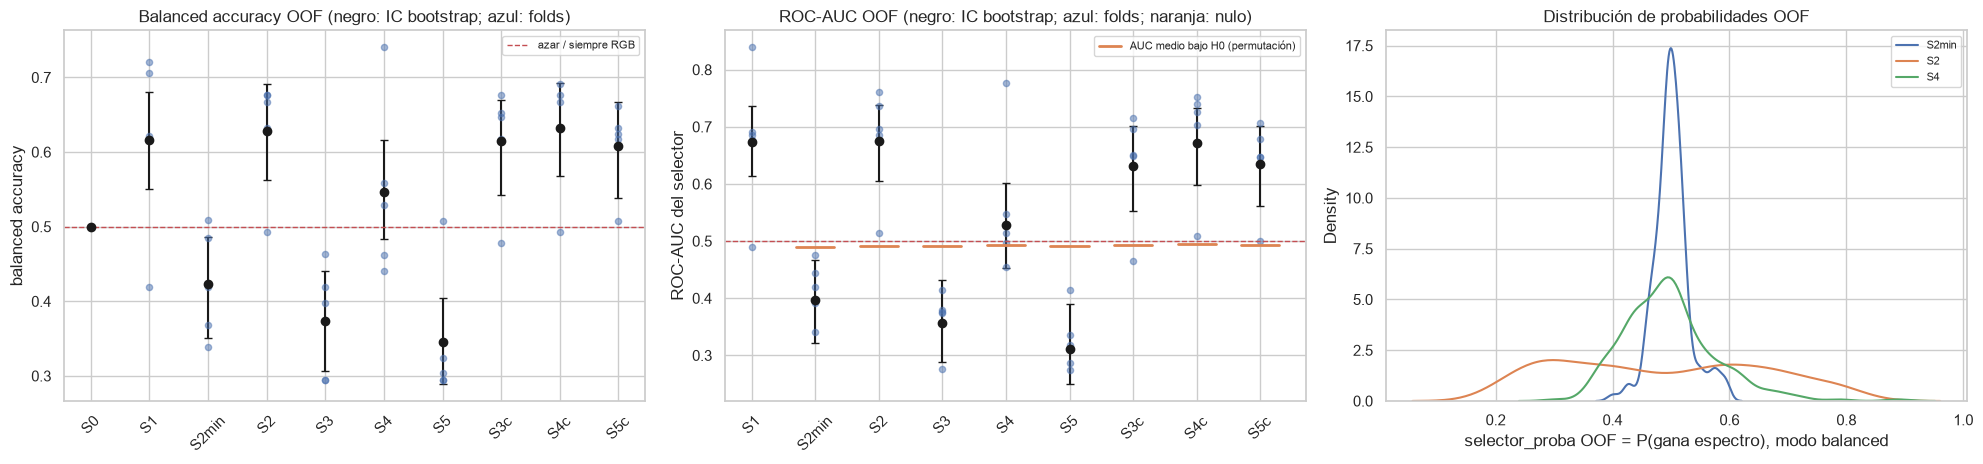

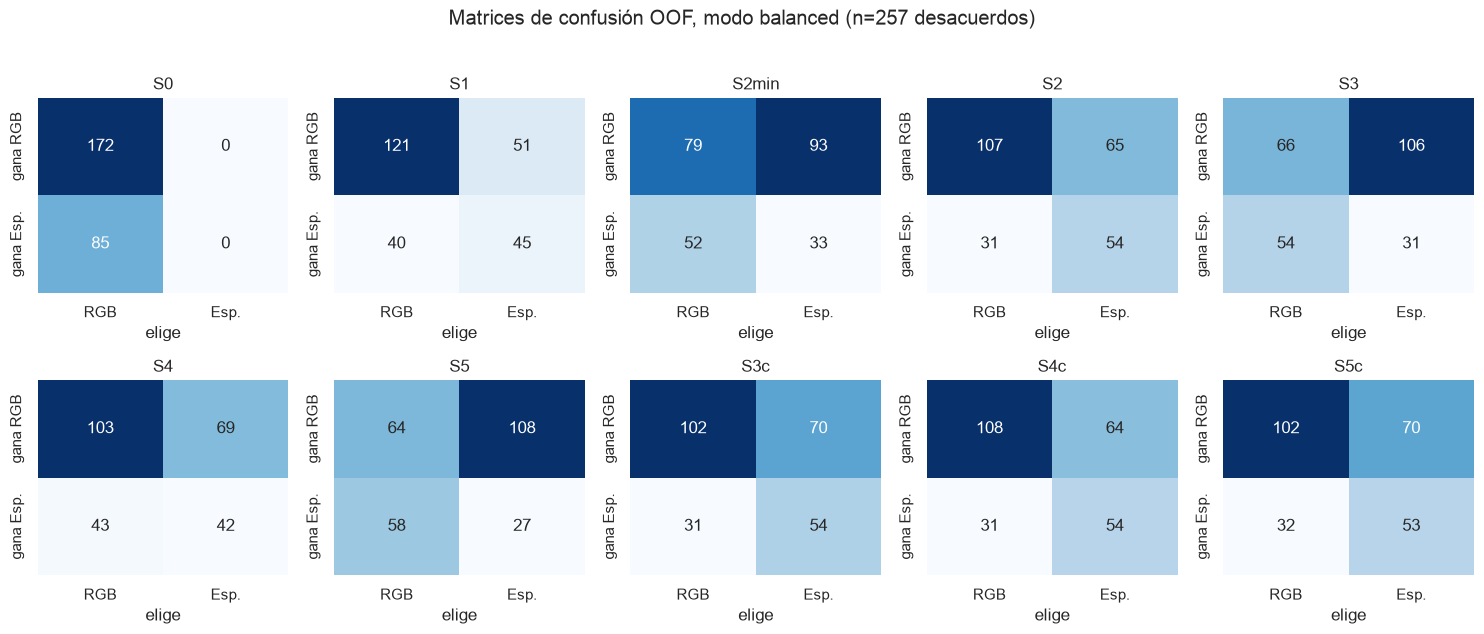

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
pv = pooled.set_index("variante")
ax = axes[0]
for i, v in enumerate(PLOT_VARIANTS):
    r = pv.loc[v]
    ax.scatter(i, r.balanced_accuracy, color="k", zorder=3)
    if v != "S0":
        ax.errorbar(i, r.balanced_accuracy, yerr=[[r.balanced_accuracy - r.bal_acc_lo], [r.bal_acc_hi - r.balanced_accuracy]], color="k", capsize=3)
    ax.scatter([i] * N_FOLDS, per_fold[per_fold.variante == v].balanced_accuracy, color="C0", alpha=0.5, s=20, zorder=2)
ax.axhline(0.5, color="r", ls="--", lw=1, label="azar / siempre RGB")
ax.set_xticks(range(len(PLOT_VARIANTS))); ax.set_xticklabels(PLOT_VARIANTS, rotation=45); ax.set_ylabel("balanced accuracy"); ax.legend(fontsize=8)
ax.set_title("Balanced accuracy OOF (negro: IC bootstrap; azul: folds)")
ax = axes[1]
vs_ = [v for v in PLOT_VARIANTS if v != "S0"]
for i, v in enumerate(vs_):
    r = pv.loc[v]
    ax.scatter(i, r.roc_auc, color="k", zorder=3)
    ax.errorbar(i, r.roc_auc, yerr=[[r.roc_auc - r.auc_lo], [r.auc_hi - r.roc_auc]], color="k", capsize=3)
    ax.scatter([i] * N_FOLDS, per_fold[per_fold.variante == v].roc_auc, color="C0", alpha=0.5, s=20, zorder=2)
    if v in perm.index:
        ax.plot([i - 0.3, i + 0.3], [perm.loc[v, "auc_nulo_medio"]] * 2, color="C1", lw=2, label="AUC medio bajo H0 (permutación)" if i == 1 else None)
ax.axhline(0.5, color="r", ls="--", lw=1); ax.set_xticks(range(len(vs_))); ax.set_xticklabels(vs_, rotation=45); ax.set_ylabel("ROC-AUC del selector")
ax.legend(fontsize=8); ax.set_title("ROC-AUC OOF (negro: IC bootstrap; azul: folds; naranja: nulo)")
ax = axes[2]
for v in ["S2min", "S2", "S4"]:
    sns.kdeplot(oof_proba[v], ax=ax, label=v, clip=(0, 1), bw_adjust=0.8)
ax.set_xlabel("selector_proba OOF = P(gana espectro), modo balanced"); ax.set_title("Distribución de probabilidades OOF"); ax.legend(fontsize=8)
fig.tight_layout(); save_fig(fig, "exp6_selector_metricas"); plt.show()

# Matrices de confusión
nplot = len(PLOT_VARIANTS); ncols = 5; nrows = int(np.ceil(nplot / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3.1 * nrows))
for ax, v in zip(axes.ravel(), PLOT_VARIANTS):
    cm = confusion_matrix(y_dis, choice[v], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=["RGB", "Esp."], yticklabels=["gana RGB", "gana Esp."])
    ax.set_title(v); ax.set_xlabel("elige")
for ax in axes.ravel()[nplot:]:
    ax.axis("off")
fig.suptitle(f"Matrices de confusión OOF, modo balanced (n={len(dis)} desacuerdos)", y=1.02)
fig.tight_layout(); save_fig(fig, "exp6_matrices_confusion"); plt.show()

**Interpretación.** El baseline S0 tiene balanced accuracy 0.5 por construcción (nunca elige espectro) y su accuracy iguala la proporción de victorias de RGB. Un selector útil debe superar 0.5 en balanced accuracy y ROC-AUC con IC que excluya 0.5 **y** un AUC por encima de lo esperable bajo la hipótesis nula de permutación, de manera estable entre folds y semillas. Los puntos azules muestran la dispersión por fold: con solo unas decenas de desacuerdos por fold, la variabilidad entre folds suele ser grande.

**Lectura de las variantes.** `S2min` solo ve `p_rgb` y `p_spectrum` de forma lineal; la confianza `2|p−0.5|` es una función *no monótona* de la probabilidad, así que una logística lineal en `p` no puede reproducirla. Por eso `S2` (que añade `confidence_*` y `probability_gap`) no es solo "redundante": es la única versión que puede expresar "desconfía de quien está cerca de 0.5". Los AUC OOF de variantes sin señal quedan por debajo de 0.5 (ver el nulo de permutación): no se interpretan como relación inversa.

**Modos de decisión.** El modo `balanced` maximiza el equilibrio entre clases (balanced accuracy, recall del espectro) pero cambia a espectro con una probabilidad real de acierto cercana a la tasa base de victorias del espectro: tiende a *perder* aciertos totales. El modo `prior` conserva la tasa base y solo cambia cuando P(gana espectro) > 0.5, que es la regla coherente con maximizar la ganancia neta; se evalúa en la simulación (§8). No se ajustó ningún umbral con los datos.

Compárese cada variante contextual con `S2min` y con `S2` (el mejor punto de partida basado solo en probabilidades). Dado que se comparan varias variantes sobre los mismos datos, la mejor tenderá a verse algo optimista; esa variante se usa en las secciones siguientes solo con fines de diagnóstico.

**Limitaciones:** (i) muestra pequeña; (ii) un solo split de validación; (iii) las redes base tienen sesgo favorable en `validation` (sus checkpoints se eligieron allí); (iv) los IC bootstrap del AUC OOF no incorporan la variabilidad de reentrenar el selector.

## 8. Experimento 7: simulación de un sistema de selección

**Pregunta:** si se usara el selector, ¿cuántos aciertos de RGB se corrigen y cuántos se pierden?

**Regla del sistema:** si RGB y espectro coinciden → predicción de RGB; si discrepan → el selector (predicciones OOF) elige cuál adoptar. Es un **selector binario**, no una fusión suave.

**Definiciones.** `rescued = RGB falla ∧ el sistema acierta`; `lost = RGB acierta ∧ el sistema falla`; `net_gain = rescued − lost`.

**Probabilidades del sistema (para AUC y Brier).** El sistema es una conmutación dura, así que se define explícitamente `p_sistema = p_spectrum` si el selector elige espectro, y `p_rgb` en cualquier otro caso. **No** es una probabilidad calibrada: la conmutación introduce saltos en la probabilidad, por lo que AUC y Brier del sistema son indicativos y no equivalentes a los de un modelo probabilístico.

**Comparaciones:** RGB sola, espectro solo, selección mayoritaria (S0 = RGB), fusión fija α=0.85 (misma muestra), regla de confianza S1, y un **oráculo** (elige siempre al ganador; cota superior inalcanzable, solo para dimensionar el margen). Todas las comparaciones usan exactamente las mismas galaxias de `validation`.

In [27]:
def label_of(v):
    if v == "S0": return "S0 selección mayoritaria (siempre RGB)"
    if v == "S1": return "S1 regla de confianza"
    return f"{base(v)} logística OOF ({mode_of(v)})"


def system_eval(df, choose_spec, label, key=None):
    # choose_spec: bool por galaxia (solo relevante donde hay desacuerdo)
    cs = np.asarray(choose_spec, dtype=bool) & df.disagreement.values
    pred = np.where(cs, df.pred_spectrum, df.pred_rgb)
    p = np.where(cs, df.p_spectrum, df.p_rgb)
    ok = pred == df.y_true.values
    rescued = int((~df.correct_rgb.values & ok).sum()); lost = int((df.correct_rgb.values & ~ok).sum())
    d = ok.astype(int) - df.correct_rgb.values.astype(int)
    boots = d[rng.integers(0, len(d), (N_BOOT, len(d)))]
    return {"sistema": label, "variante": key, "n": len(df), "accuracy": ok.mean(), "balanced_accuracy": balanced_accuracy_score(df.y_true, pred),
            "macro_F1": f1_score(df.y_true, pred, average="macro"), "roc_auc": roc_auc_score(df.y_true, p), "brier": brier_score_loss(df.y_true, p),
            "n_cambios_a_espectro": int(cs.sum()), "rescued_rgb_errors": rescued, "lost_rgb_correct": lost, "net_gain": rescued - lost,
            "net_gain_lo": np.percentile(boots.sum(axis=1), 2.5), "net_gain_hi": np.percentile(boots.sum(axis=1), 97.5),
            "net_gain_menos_K": rescued - lost - ROBUST_K,
            "delta_acc_vs_rgb": d.mean(), "delta_acc_lo": np.percentile(boots.mean(axis=1), 2.5), "delta_acc_hi": np.percentile(boots.mean(axis=1), 97.5)}


idx_dis = dev.index[dev.disagreement].values            # posiciones de los desacuerdos en dev
assert (dev.loc[idx_dis, "name"].values == dis["name"].values).all(), "orden de desacuerdos inconsistente entre dev y dis"


def full_choice(v):
    c = np.zeros(len(dev), dtype=bool)
    c[idx_dis] = choice[v].astype(bool)
    return c


rows = [system_eval(dev, np.zeros(len(dev), bool), "RGB sola"), system_eval(dev, np.ones(len(dev), bool), "Espectro solo")]
# Donde coinciden, RGB y espectro predicen igual; solo AUC y Brier difieren y se recalculan con p_spectrum
rows[1].update(roc_auc=roc_auc_score(dev.y_true, dev.p_spectrum), brier=brier_score_loss(dev.y_true, dev.p_spectrum))

fus_pred = (dev.p_fusion >= THRESHOLD).astype(int)
ok_f = (fus_pred == dev.y_true).values
d_f = ok_f.astype(int) - dev.correct_rgb.values.astype(int)
bf = d_f[rng.integers(0, len(d_f), (N_BOOT, len(d_f)))]
rows.append({"sistema": f"Fusión fija α={ALPHA_FIXED}", "variante": None, "n": len(dev), "accuracy": ok_f.mean(), "balanced_accuracy": balanced_accuracy_score(dev.y_true, fus_pred),
             "macro_F1": f1_score(dev.y_true, fus_pred, average="macro"), "roc_auc": roc_auc_score(dev.y_true, dev.p_fusion), "brier": brier_score_loss(dev.y_true, dev.p_fusion),
             "n_cambios_a_espectro": np.nan, "rescued_rgb_errors": int((~dev.correct_rgb.values & ok_f).sum()), "lost_rgb_correct": int((dev.correct_rgb.values & ~ok_f).sum()),
             "net_gain": int(d_f.sum()), "net_gain_lo": np.percentile(bf.sum(axis=1), 2.5), "net_gain_hi": np.percentile(bf.sum(axis=1), 97.5),
             "net_gain_menos_K": int(d_f.sum()) - ROBUST_K, "delta_acc_vs_rgb": d_f.mean(), "delta_acc_lo": np.percentile(bf.mean(axis=1), 2.5),
             "delta_acc_hi": np.percentile(bf.mean(axis=1), 97.5)})
for v in VARIANTS:
    rows.append(system_eval(dev, full_choice(v), label_of(v), v))
oracle = np.zeros(len(dev), bool); oracle[idx_dis] = dis.selector_target.values == 1
rows.append(system_eval(dev, oracle, "Oráculo (cota superior, no alcanzable)"))
sim = pd.DataFrame(rows)
save_table(sim, "selection_simulation")
display(Markdown(f"**Simulación sobre las mismas {len(dev)} galaxias de validation** (IC95% por bootstrap sobre galaxias, con las decisiones OOF fijas)"))
display(sim[["sistema", "accuracy", "balanced_accuracy", "macro_F1", "roc_auc", "brier", "n_cambios_a_espectro", "rescued_rgb_errors",
             "lost_rgb_correct", "net_gain", "net_gain_lo", "net_gain_hi", "delta_acc_vs_rgb", "delta_acc_lo", "delta_acc_hi"]])
R["sim"] = sim.set_index("sistema")

**Simulación sobre las mismas 1403 galaxias de validation** (IC95% por bootstrap sobre galaxias, con las decisiones OOF fijas)

,sistema,accuracy,balanced_accuracy,macro_F1,roc_auc,brier,n_cambios_a_espectro,rescued_rgb_errors,lost_rgb_correct,net_gain,net_gain_lo,net_gain_hi,delta_acc_vs_rgb,delta_acc_lo,delta_acc_hi
0,RGB sola,0.8959,0.8896,0.8893,0.9644,0.0739,0.0000,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000
1,Espectro solo,0.8339,0.8245,0.8237,0.8985,0.1230,257.0000,85,172,-87,-118.0000,-57.0000,-0.0620,-0.0841,-0.0406
2,Fusión fija α=0.85,0.8981,0.8921,0.8916,0.9667,0.0715,NaN,12,9,3,-6.0000,12.0000,0.0021,-0.0043,0.0086
3,S0 selección mayoritaria (siempre RGB),0.8959,0.8896,0.8893,0.9644,0.0739,0.0000,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000
4,S1 regla de confianza,0.8917,0.8824,0.8842,0.9582,0.0840,96.0000,45,51,-6,-25.0000,13.0000,-0.0043,-0.0178,0.0093
5,S2min logística OOF (balanced),0.8532,0.8512,0.8459,0.9514,0.0930,126.0000,33,93,-60,-81.0000,-39.0000,-0.0428,-0.0577,-0.0278
6,S2 logística OOF (balanced),0.8881,0.8822,0.8812,0.9595,0.0831,119.0000,54,65,-11,-32.0000,11.0000,-0.0078,-0.0228,0.0078
7,S3 logística OOF (balanced),0.8425,0.8381,0.8342,0.9479,0.0990,137.0000,31,106,-75,-98.0000,-54.0000,-0.0535,-0.0699,-0.0385
8,S4 logística OOF (balanced),0.8767,0.8730,0.8698,0.9577,0.0843,111.0000,42,69,-27,-49.0000,-6.0000,-0.0192,-0.0349,-0.0043
9,S5 logística OOF (balanced),0.8382,0.8336,0.8297,0.9462,0.0994,135.0000,27,108,-81,-105.0000,-58.0000,-0.0577,-0.0748,-0.0413


**Ganancia neta por fold** (rescued − lost dentro de los desacuerdos de cada fold)

fold,0,1,2,3,4,suma,folds_con_ganancia_>0,media_por_fold,sd_por_fold
variante,,,,,,,,,
S1,-11,-1,3,-2,5,-6,2,-1.2000,6.1806
S2min,-11,-10,-9,-14,-16,-60,0,-12.0000,2.9155
S2,-9,-1,0,-2,1,-11,1,-2.2000,3.9623
S3,-12,-10,-21,-14,-18,-75,0,-15.0000,4.4721
S4,-8,2,-5,-5,-11,-27,1,-5.4000,4.8270
S5,-9,-19,-20,-16,-17,-81,0,-16.2000,4.3243
S3c,-10,-2,-2,-3,1,-16,1,-3.2000,4.0866
S4c,-9,-1,0,-2,2,-10,1,-2.0000,4.1833
S5c,-9,-3,-3,-3,1,-17,1,-3.4000,3.5777


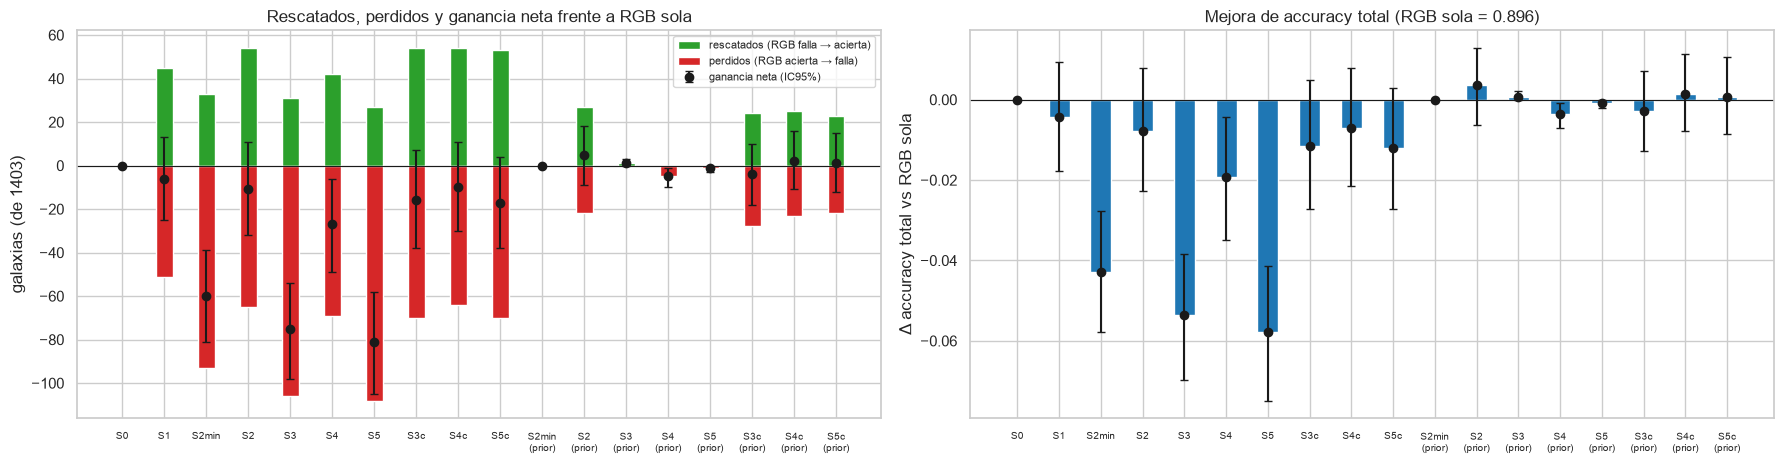

In [28]:
# Variabilidad por fold: ganancia neta dentro de los desacuerdos retenidos de cada fold
rows = []
for v in VARIANTS[1:]:
    for k in range(N_FOLDS):
        m = folds == k
        ch = choice[v][m].astype(bool)
        ok = np.where(ch, dis.pred_spectrum[m], dis.pred_rgb[m]) == dis.y_true[m]
        resc = int((~dis.correct_rgb[m].values & ok).sum()); lost = int((dis.correct_rgb[m].values & ~ok).sum())
        rows.append({"variante": v, "fold": k, "n_desacuerdos": int(m.sum()), "rescued": resc, "lost": lost, "net_gain": resc - lost})
fold_gain = pd.DataFrame(rows)
fg = fold_gain.pivot(index="variante", columns="fold", values="net_gain").loc[VARIANTS[1:]]
fg["suma"] = fg[list(range(N_FOLDS))].sum(axis=1); fg["folds_con_ganancia_>0"] = (fg[list(range(N_FOLDS))] > 0).sum(axis=1)
fg["media_por_fold"] = fg[list(range(N_FOLDS))].mean(axis=1); fg["sd_por_fold"] = fg[list(range(N_FOLDS))].std(axis=1)
display(Markdown("**Ganancia neta por fold** (rescued − lost dentro de los desacuerdos de cada fold)")); display(fg)
R["fold_gain"] = fg
save_table(fold_gain, "selection_simulation_folds")

fig, axes = plt.subplots(1, 2, figsize=(18, 4.8))
s_ = sim[sim.variante.notna()].reset_index(drop=True)
x = np.arange(len(s_))
xl = [v.replace("|prior", "\n(prior)") for v in s_.variante]
ax = axes[0]
ax.bar(x, s_.rescued_rgb_errors, 0.4, color="#2ca02c", label="rescatados (RGB falla → acierta)")
ax.bar(x, -s_.lost_rgb_correct, 0.4, color="#d62728", label="perdidos (RGB acierta → falla)")
ax.errorbar(x, s_.net_gain, yerr=[s_.net_gain - s_.net_gain_lo, s_.net_gain_hi - s_.net_gain], fmt="ko", capsize=3, label="ganancia neta (IC95%)")
ax.axhline(0, color="k", lw=0.8); ax.set_xticks(x); ax.set_xticklabels(xl, fontsize=7.5); ax.set_ylabel(f"galaxias (de {len(dev)})")
ax.set_title("Rescatados, perdidos y ganancia neta frente a RGB sola"); ax.legend(fontsize=8)
ax = axes[1]
ax.bar(x, s_.delta_acc_vs_rgb, 0.5, color="#1f77b4")
ax.errorbar(x, s_.delta_acc_vs_rgb, yerr=[s_.delta_acc_vs_rgb - s_.delta_acc_lo, s_.delta_acc_hi - s_.delta_acc_vs_rgb], fmt="ko", capsize=3)
ax.axhline(0, color="k", lw=0.8); ax.set_xticks(x); ax.set_xticklabels(xl, fontsize=7.5); ax.set_ylabel("Δ accuracy total vs RGB sola")
ax.set_title(f"Mejora de accuracy total (RGB sola = {sim.set_index('sistema').loc['RGB sola', 'accuracy']:.3f})")
fig.tight_layout(); save_fig(fig, "exp7_simulacion"); plt.show()

**Interpretación.** Una tasa alta de selección correcta *dentro de los desacuerdos* no garantiza una mejora global relevante: los desacuerdos son solo una fracción de la muestra (ver §1), y cada cambio incorrecto cuesta tanto como cada rescate. Por eso el indicador clave es la ganancia neta con su IC, y su estabilidad por fold. La fila del **oráculo** dimensiona el máximo teórico de ganancia, y la de **espectro solo** muestra cuánto se pierde si se confía siempre en la otra modalidad.

La columna `net_gain_menos_K` resta `K` rescates (parámetro `ROBUST_K`) a la ganancia neta: si sigue siendo positiva, la mejora no depende de unas pocas galaxias.

**Limitaciones:** (i) el AUC/Brier del sistema usa una definición de probabilidad por conmutación (no calibrada); (ii) el IC bootstrap trata las decisiones OOF como fijas, por lo que no incorpora la incertidumbre de reentrenar el selector; (iii) la fusión fija α=0.85 se eligió en un trabajo previo usando `validation`, así que su comparación aquí es favorable para ella.

# PARTE IV — Interpretación y decisiones

## 9. Interpretación de las decisiones del selector

Se analiza la variante *primaria*: la que defina `PRIMARY_SELECTOR`, o si es `None`, la variante logística (S2min–S5, definidas a priori) con mayor ROC-AUC OOF. **Esa elección usa los mismos datos de evaluación y es, por tanto, algo optimista**; se usa solo para el diagnóstico de decisiones, no como afirmación de rendimiento. Las decisiones se analizan en el modo `DECISION_MODE` (por defecto `prior`, la regla coherente con maximizar la ganancia neta).

In [29]:
PRIMARY = PRIMARY_SELECTOR or R["pooled"].loc[list(SELECTOR_FEATURES), "roc_auc"].idxmax()   # solo variantes definidas a priori
DKEY = PRIMARY + DECISION_MODE                                                                      # variante + modo de decisión
print(f"Variante primaria: {PRIMARY}  (ROC-AUC OOF = {R['pooled'].loc[PRIMARY, 'roc_auc']:.3f}; rasgos: {', '.join(FEATURES_OF[PRIMARY])})")
print(f"Modo de decisión usado en esta sección: {mode_of(DKEY)} ({DKEY})")
print(f"Se necesita en inferencia: {INFERENCE_NEEDS[PRIMARY]}")

dis["selector_proba"] = oof_proba[DKEY]
dis["selector_choice"] = np.where(choice[DKEY] == 1, "espectro", "RGB")
dis["fold"] = folds
dis["correct_selector"] = np.where(choice[DKEY] == 1, dis.correct_spectrum, dis.correct_rgb)
dis["decision"] = np.select(
    [(choice[DKEY] == 1) & ~dis.correct_rgb, (choice[DKEY] == 1) & dis.correct_rgb,
     (choice[DKEY] == 0) & dis.correct_spectrum], ["cambio correcto (RGB→espectro)", "cambio incorrecto (perjudica a RGB)", "selector favorece RGB pero espectro tenía razón"],
    "mantiene RGB correctamente")
DEC_ORDER = ["cambio correcto (RGB→espectro)", "cambio incorrecto (perjudica a RGB)", "selector favorece RGB pero espectro tenía razón", "mantiene RGB correctamente"]
display(dis.decision.value_counts().reindex(DEC_ORDER).rename("n").to_frame())

# Exportación completa: todas las galaxias de validation (sin desacuerdo: elige RGB por definición del sistema)
out = dev[["name", "split", "y_true", "p_rgb", "p_spectrum", "p_pop", "disagreement", "selector_target", "correct_rgb", "correct_spectrum",
           "Ttype", "Type", "LogMass", "nsa_z", "incl", "PETRO_TH90"] + [c for c in sl_cols if c in dev.columns]].copy()
extra = dis.set_index("name")[["selector_proba", "selector_choice", "correct_selector", "fold", "decision"]]
out = out.merge(extra, left_on="name", right_index=True, how="left")
out["selector_choice"] = out.selector_choice.fillna("RGB")                 # sin desacuerdo se usa RGB
out["correct_selector"] = out.correct_selector.fillna(out.correct_rgb)
out["variante_selector"] = DKEY
out = out.rename(columns={"Ttype": "Ttype_solo_analisis", "Type": "Type_solo_analisis"})
oof_all = pd.concat([pd.DataFrame({"name": dis.name, "variante": v, "fold": folds, "selector_target": y_dis,
                                   "selector_proba": oof_proba.get(v, np.nan), "selector_choice": np.where(choice[v] == 1, "espectro", "RGB")}) for v in VARIANTS])
save_table(out, "selector_oof_predictions")
save_table(oof_all, "selector_oof_predictions_todas_las_variantes")
dis_export = dis.drop(columns=["ganador", "rgb_confiado", "spec_confiado"], errors="ignore")
save_table(dis_export, "disagreement_analysis")
print(f"Exportado selector_oof_predictions.csv: {len(out)} filas | desacuerdos con selector_proba: {int(out.selector_proba.notna().sum())}")

Variante primaria: S2  (ROC-AUC OOF = 0.676; rasgos: p_rgb, p_spectrum, confidence_rgb, confidence_spectrum, probability_gap)
Modo de decisión usado en esta sección: prior (S2|prior)
Se necesita en inferencia: RGB + espectro


,n
decision,
cambio correcto (RGB→espectro),27
cambio incorrecto (perjudica a RGB),22
selector favorece RGB pero espectro tenía razón,58
mantiene RGB correctamente,150


Exportado selector_oof_predictions.csv: 1403 filas | desacuerdos con selector_proba: 257


,grupo,n_desacuerdos,cambio correcto (RGB→espectro),cambio incorrecto (perjudica a RGB),selector favorece RGB pero espectro tenía razón,mantiene RGB correctamente,acc_selector,acc_siempre_RGB,ganancia_neta,interpretable
0,E (Ttype -5),32,1,1,4,26,0.8438,0.8438,0,True
1,S0 (Ttype -2),56,7,6,12,31,0.6786,0.6607,1,True
2,S0a (Ttype 0),41,6,2,14,19,0.6098,0.5122,4,True
3,Tardía frontera (Ttype 1),60,5,7,20,28,0.5500,0.5833,-2,True
4,Tardía (Ttype 2),42,5,2,5,30,0.8333,0.7619,3,True
5,Tardía (Ttype ≥ 3),26,3,4,3,16,0.7308,0.7692,-1,True


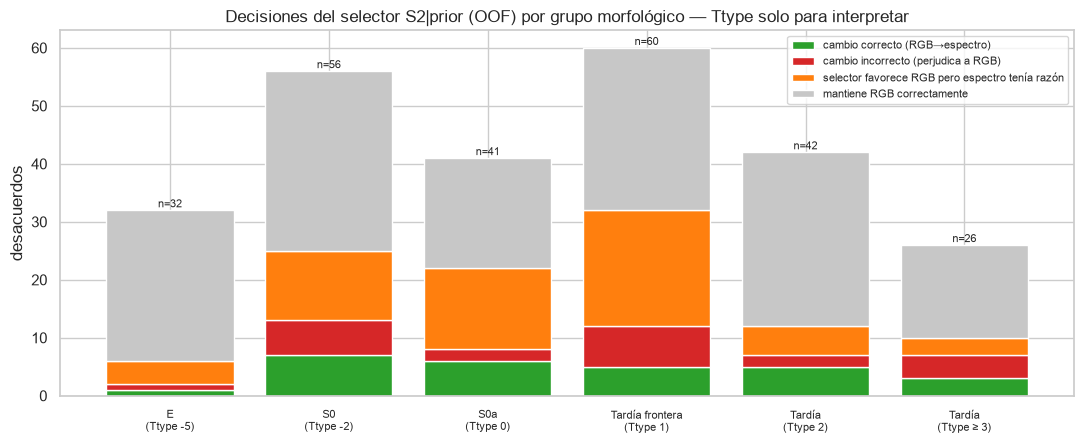

In [30]:
# Errores del selector por grupo morfológico (Ttype solo como etiqueta de interpretación)
rows = []
for g_ in TT_ORDER:
    g = dis[dis.ttype_group == g_]
    rows.append({"grupo": g_, "n_desacuerdos": len(g), **{d: int((g.decision == d).sum()) for d in DEC_ORDER},
                 "acc_selector": g.correct_selector.mean() if len(g) else np.nan, "acc_siempre_RGB": g.correct_rgb.mean() if len(g) else np.nan,
                 "ganancia_neta": int((g.decision == DEC_ORDER[0]).sum() - (g.decision == DEC_ORDER[1]).sum()), "interpretable": len(g) >= MIN_GROUP})
dec_tt = pd.DataFrame(rows)
display(dec_tt)
R["dec_tt"] = dec_tt

fig, ax = plt.subplots(figsize=(11, 4.6))
colors = ["#2ca02c", "#d62728", "#ff7f0e", "#c7c7c7"]
bottom = np.zeros(len(dec_tt))
for d, c in zip(DEC_ORDER, colors):
    ax.bar(range(len(dec_tt)), dec_tt[d], bottom=bottom, color=c, label=d); bottom += dec_tt[d].values
for i, r in enumerate(dec_tt.itertuples()):
    ax.text(i, bottom[i] + 0.5, f"n={r.n_desacuerdos}" + ("" if r.interpretable else "\n(<min)"), ha="center", fontsize=8)
ax.set_xticks(range(len(dec_tt))); ax.set_xticklabels([g.replace(" (", "\n(") for g in dec_tt.grupo], fontsize=8)
ax.set_ylabel("desacuerdos"); ax.set_title(f"Decisiones del selector {DKEY} (OOF) por grupo morfológico — Ttype solo para interpretar"); ax.legend(fontsize=8)
fig.tight_layout(); save_fig(fig, "parte4_decisiones_ttype"); plt.show()

,categoria,name,Type,Ttype,p_rgb,p_spectrum,selector_proba,y_true
0,cambio correcto,manga-8482-3702,Sbc,4,0.4223,0.9221,0.6682,1
1,cambio correcto,manga-11974-1902,Sa,1,0.4658,0.9856,0.6577,1
2,cambio correcto,manga-8453-3701,S0,-2,0.5485,0.1249,0.6576,0
3,cambio correcto,manga-11950-3703,S0a,0,0.5711,0.0977,0.6482,0
4,cambio incorrecto,manga-8455-1902,S0,-2,0.4343,0.9838,0.7074,0
5,cambio incorrecto,manga-11823-3704,SABa,1,0.5405,0.1001,0.6646,1
6,cambio incorrecto,manga-8727-3703,S0,-2,0.4759,0.7586,0.6640,0
7,cambio incorrecto,manga-11951-3704,Sa,1,0.5282,0.1201,0.6560,1
8,rescate perdido,manga-12066-6103,SB0a,0,0.9937,0.4846,0.1124,0
9,rescate perdido,manga-8143-3703,SABa,1,0.0181,0.6336,0.1215,1


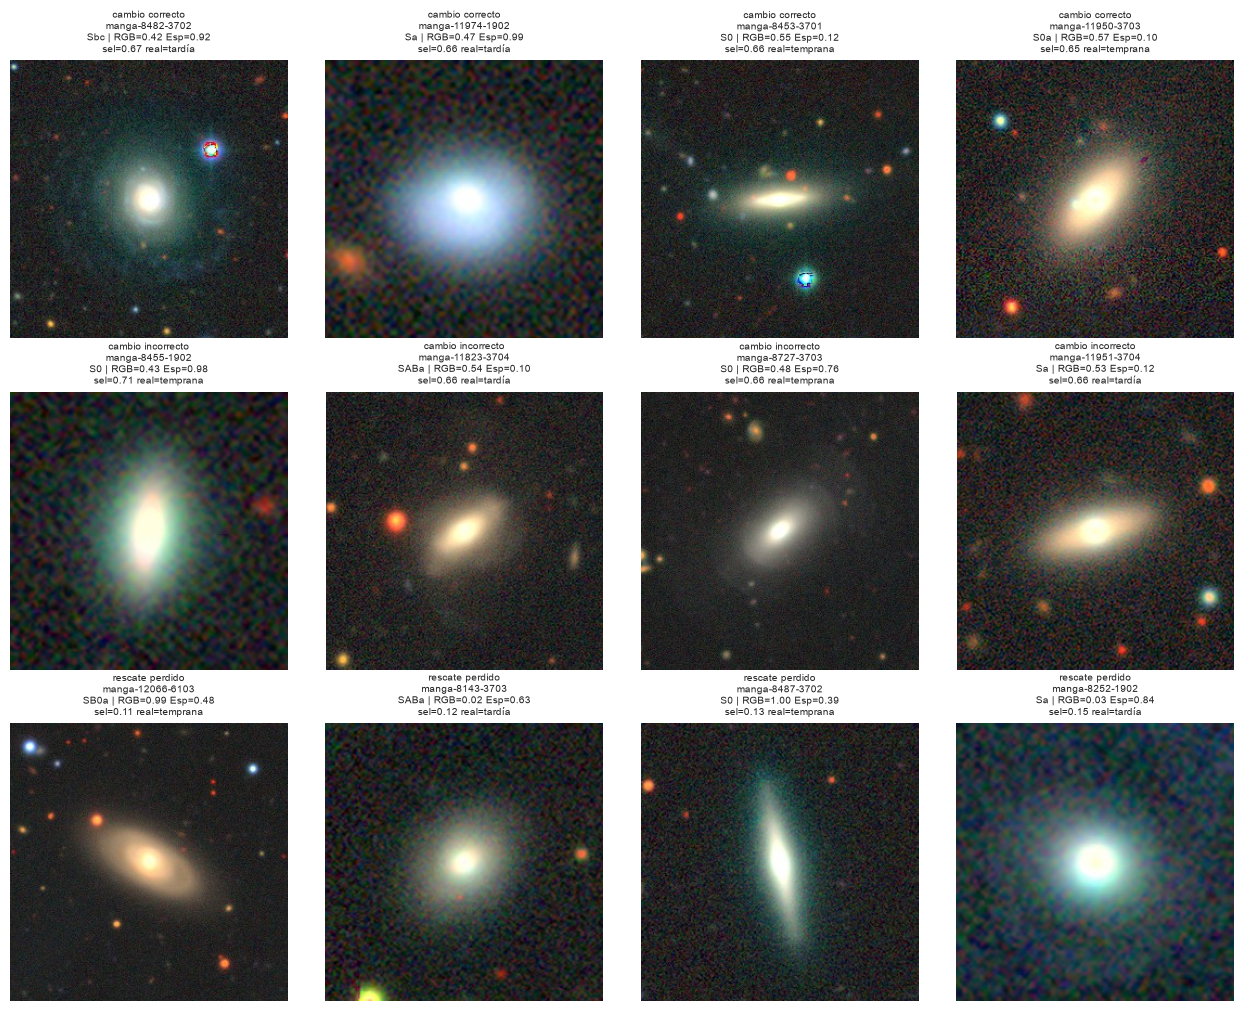

In [31]:
# Galaxias de mayor interés diagnóstico por categoría de decisión (selección reproducible:
# mayor confianza del selector |P-0.5|, desempate por nombre). Galería completa: ver analisis_complementariedad_multimodal.ipynb
N_GAL = 4
paths = manifest.set_index("name").fov_0_path
cats = [("cambio correcto (RGB→espectro)", "cambio correcto"), ("cambio incorrecto (perjudica a RGB)", "cambio incorrecto"),
        ("selector favorece RGB pero espectro tenía razón", "rescate perdido")]
sel = []
for dname, short in cats:
    g = dis[dis.decision == dname].assign(conf=lambda d: (d.selector_proba - 0.5).abs()).sort_values(["conf", "name"], ascending=[False, True]).head(N_GAL)
    sel.append((dname, short, g))
tabs = pd.concat([g.assign(categoria=short) for _, short, g in sel])
display(tabs[["categoria", "name", "Type", "Ttype", "p_rgb", "p_spectrum", "selector_proba", "y_true"]].reset_index(drop=True))

fig, axes = plt.subplots(len(cats), N_GAL, figsize=(3.2 * N_GAL, 3.4 * len(cats)))
for i, (dname, short, g) in enumerate(sel):
    for j in range(N_GAL):
        ax = axes[i, j]; ax.axis("off")
        if j >= len(g):
            continue
        r = g.iloc[j]
        p = ROOT / paths[r["name"]]
        if p.exists():
            ax.imshow(plt.imread(p))
        ax.set_title(f"{short}\n{r['name']}\n{r.Type} | RGB={r.p_rgb:.2f} Esp={r.p_spectrum:.2f}\nsel={r.selector_proba:.2f} real={'tardía' if r.y_true else 'temprana'}", fontsize=7.5)
fig.tight_layout(); save_fig(fig, "parte4_galeria_decisiones"); plt.show()

**Interpretación.** Las cuatro categorías de decisión descomponen la ganancia neta: *cambios correctos* (rescates) menos *cambios incorrectos* (pérdidas), más los *rescates perdidos* (el espectro tenía razón pero el selector se quedó con RGB). El gráfico por grupo morfológico indica si los errores del selector se concentran en la frontera morfológica (Ttype 0–1); los grupos con menos de `MIN_GROUP` desacuerdos no se interpretan. La galería es un muestreo cualitativo (mayor confianza del selector) y sirve para formular hipótesis (morfologías peculiares, inclinación, compañeras), no para concluir.

**Limitación:** una inspección visual de unos pocos objetos no demuestra nada; las hipótesis que surjan requieren un análisis cuantitativo posterior.

## 10. Conclusiones y recomendación

Las respuestas siguientes se **generan a partir de los resultados calculados arriba** (no se escriben a mano), de modo que cambian si cambian los datos. Cada respuesta distingue lo **observado** de lo que solo es **hipótesis plausible**; las hipótesis y limitaciones están en la sección final.

In [32]:
P = R["pooled"]; S = R["sim"]; CP = R["cmp_props"]; PM = R["perm"]
f3 = lambda x: f"{x:.3f}"
ci = lambda a, lo, hi: f"{a:.3f} [IC95% {lo:.3f}, {hi:.3f}]"
simv = lambda v: S.loc[label_of(v)]


def grp_summary(letter):
    t = CP[CP.grupo.str.startswith(letter)].dropna(subset=["cliff_delta"])
    sig = t[t.p_holm < 0.05]
    top = t.loc[t.cliff_delta.abs().idxmax()]
    return (f"{len(sig)} de {len(t)} variables con p_Holm < 0.05" + (f" ({', '.join(sig.index)})" if len(sig) else "")
            + f"; mayor efecto: {top.name} (δ de Cliff = {top.cliff_delta:+.2f})")


def perm_txt(v):
    r = PM.loc[v]
    return f"AUC {f3(r.auc_obs)} (nulo medio {f3(r.auc_nulo_medio)}, p de permutación = {r['p_perm_(AUC>=obs)']:.3f})"


s1, s2min, s2, prim = P.loc["S1"], P.loc["S2min"], P.loc["S2"], P.loc[PRIMARY]
dprim_b, dprim_p = P.loc[PRIMARY], P.loc[DKEY]
sp_b, sp_p = simv(PRIMARY), simv(DKEY)
fus = S.loc[f"Fusión fija α={ALPHA_FIXED}"]; orc = S.loc["Oráculo (cota superior, no alcanzable)"]
both = both_tab[(both_tab.RGB == "RGB confiado") & (both_tab["Espectro"] == "Esp. confiado")]
both_txt = (f"{int(both.iloc[0].n_desacuerdos)} desacuerdos con ambos modelos confiados; el espectro gana {both.iloc[0].prop_gana_espectro:.1%} "
            f"[IC95% {both.iloc[0].IC95_lo:.1%}, {both.iloc[0].IC95_hi:.1%}]") if len(both) else "no hay desacuerdos con ambos modelos confiados"
cal = R["cal"]; cd = R["cal_dis"]
rgb_cal = cal.loc["ResNet-18 RGB"]; sp_cal = cal.loc["CNN+atención espectro SL"]
a_r = R["auc_conf_rgb_detect"]; a_u = R["auc_unc_rgb_rescue"]; a_d = R["auc_unc_rgb_dis"]
half = lambda r: (r.auc_hi - r.auc_lo) / 2

ans = []
ans.append(f"**1. ¿Las probabilidades contienen información para identificar qué modalidad tiene razón?** "
           f"Observado: la información está en la **confianza** (distancia a 0.5), no en el valor lineal de las probabilidades. "
           f"La regla S1 (elegir al más confiado) da AUC {f3(s1.roc_auc)} [{f3(s1.auc_lo)}, {f3(s1.auc_hi)}]; S2 (probabilidades + confianzas): {perm_txt('S2')}, balanced accuracy {f3(s2.balanced_accuracy)}. "
           f"S2min (solo `p_rgb`, `p_spectrum`, lineal): {perm_txt('S2min')}, es decir, sin señal lineal. "
           f"Nota: en un desacuerdo, acertar al elegir equivale a predecir la clase verdadera, y las señales deben leerse junto con el ancho de sus IC.")
ans.append(f"**2. ¿La incertidumbre RGB ayuda a detectar errores visuales?** `confidence_rgb` como detector de acierto de RGB: AUC {ci(a_r['AUC'], a_r['IC95_lo'], a_r['IC95_hi'])} (sobre las {len(dev)} galaxias). "
           f"Pero de {R['rgb_errors']} errores de RGB, {R['rgb_hc_errors']} se cometen con confianza ≥ {HIGH_CONF}; el espectro rescata {R['rescue_rate_hc']:.1%} de esos y {R['rescue_rate_lc']:.1%} de los cometidos con menor confianza. "
           f"Entre desacuerdos, `uncertainty_rgb` anticipa que gane el espectro con AUC {ci(a_d['AUC'], a_d['IC95_lo'], a_d['IC95_hi'])}.")
ans.append(f"**3. ¿Qué pasa cuando ambos están confiados y discrepan?** {both_txt}.")
ans.append(f"**4. ¿La calibración es comparable?** RGB: Brier {f3(rgb_cal.Brier)}, log loss {f3(rgb_cal.log_loss)}, ECE {f3(rgb_cal.ECE_uniforme)} (exceso de confianza {rgb_cal['exceso_confianza(conf-acc)']:+.3f}); "
           f"espectro: Brier {f3(sp_cal.Brier)}, log loss {f3(sp_cal.log_loss)}, ECE {f3(sp_cal.ECE_uniforme)} (exceso {sp_cal['exceso_confianza(conf-acc)']:+.3f}). "
           f"Δ Brier espectro−RGB = {R['brier_diff'][0]:+.4f} [IC95% {R['brier_diff'][1]:+.4f}, {R['brier_diff'][2]:+.4f}]. "
           f"La *escala* sí difiere (desviación estándar del logit: {rgb_cal.std_logit:.2f} en RGB vs {sp_cal.std_logit:.2f} en el espectro). "
           f"Dentro de los desacuerdos, RGB asigna en promedio {cd.loc['RGB', 'prob. media asignada a su clase predicha']:.3f} a su predicción (accuracy real {cd.loc['RGB', 'accuracy en desacuerdos']:.3f}) y el espectro "
           f"{cd.loc['Espectro', 'prob. media asignada a su clase predicha']:.3f} (accuracy real {cd.loc['Espectro', 'accuracy en desacuerdos']:.3f}).")
ans.append(f"**5. ¿Variables observacionales asociadas con las victorias del espectro?** Grupo A: {grp_summary('A')}. "
           f"El selector S3 (probabilidades + contexto): {perm_txt('S3')}; S3c (con confianzas, post-hoc): AUC {f3(P.loc['S3c'].roc_auc)} frente a {f3(s2.roc_auc)} de S2 (Δ = {P.loc['S3c'].roc_auc - s2.roc_auc:+.3f}; semiancho del IC de S2 = {half(s2):.3f}).")
ans.append(f"**6. ¿La calidad STARLIGHT ayuda a anticipar cuándo confiar en el espectro?** Grupo B: {grp_summary('B')}. "
           f"S4: {perm_txt('S4')}; S4c (con confianzas, post-hoc): AUC {f3(P.loc['S4c'].roc_auc)} frente a {f3(s2.roc_auc)} de S2 (Δ = {P.loc['S4c'].roc_auc - s2.roc_auc:+.3f}; semiancho del IC de S2 = {half(s2):.3f}).")
ans.append(f"**7. ¿Las propiedades físicas aportan señal adicional?** Grupo C: {grp_summary('C')}. "
           f"S5: {perm_txt('S5')}; S5c (con confianzas, post-hoc): AUC {f3(P.loc['S5c'].roc_auc)} frente a {f3(s2.roc_auc)} de S2 (Δ = {P.loc['S5c'].roc_auc - s2.roc_auc:+.3f}; semiancho del IC de S2 = {half(s2):.3f}).")
ans.append(f"**8. ¿Un selector regularizado supera al baseline que siempre elige RGB?** El baseline tiene balanced accuracy 0.5 y accuracy {P.loc['S0'].accuracy:.3f} entre desacuerdos. "
           f"Variante primaria {PRIMARY} (elegida por AUC OOF entre las definidas a priori, por lo que es algo optimista), modo balanced: balanced accuracy {ci(dprim_b.balanced_accuracy, dprim_b.bal_acc_lo, dprim_b.bal_acc_hi)}, "
           f"AUC {ci(dprim_b.roc_auc, dprim_b.auc_lo, dprim_b.auc_hi)}, recall de 'gana espectro' {f3(dprim_b.recall_gana_espectro)}, precision {f3(dprim_b.precision_gana_espectro)}, accuracy {f3(dprim_b.accuracy)} entre desacuerdos "
           f"(inferior a la del baseline, {P.loc['S0'].accuracy:.3f}, porque cambia a espectro más de lo que conviene). "
           f"En modo prior: balanced accuracy {f3(dprim_p.balanced_accuracy)}, recall {f3(dprim_p.recall_gana_espectro)}, precision {f3(dprim_p.precision_gana_espectro)}, accuracy {f3(dprim_p.accuracy)}. "
           f"Sensibilidad a la partición de folds: AUC medio {f3(R['rob'].loc[PRIMARY, 'auc_media'])} (mín. {f3(R['rob'].loc[PRIMARY, 'auc_min'])}) en {len(ROBUSTNESS_SEEDS)} semillas.")
ans.append(f"**9. ¿Corrige más errores de los que introduce?** {PRIMARY} modo balanced: {int(sp_b.rescued_rgb_errors)} errores de RGB corregidos, {int(sp_b.lost_rgb_correct)} aciertos perdidos, "
           f"ganancia neta {int(sp_b.net_gain):+d} [IC95% {sp_b.net_gain_lo:.0f}, {sp_b.net_gain_hi:.0f}]. "
           f"Modo prior: {int(sp_p.rescued_rgb_errors)} corregidos, {int(sp_p.lost_rgb_correct)} perdidos, ganancia neta {int(sp_p.net_gain):+d} [IC95% {sp_p.net_gain_lo:.0f}, {sp_p.net_gain_hi:.0f}]; "
           f"Δ accuracy total vs RGB {sp_p.delta_acc_vs_rgb:+.4f} [{sp_p.delta_acc_lo:+.4f}, {sp_p.delta_acc_hi:+.4f}] (n={int(sp_p.n)}). "
           f"Referencias en las mismas galaxias: S1 {int(simv('S1').net_gain):+d}, fusión fija α={ALPHA_FIXED} {int(fus.net_gain):+d} [{fus.net_gain_lo:.0f}, {fus.net_gain_hi:.0f}], oráculo {int(orc.net_gain):+d}, espectro solo {int(S.loc['Espectro solo'].net_gain):+d}. "
           f"Ganancia neta por fold ({DKEY}): {R['fold_gain'].loc[DKEY, list(range(N_FOLDS))].astype(int).tolist()}.")
display(Markdown("\n\n".join(ans)))

**1. ¿Las probabilidades contienen información para identificar qué modalidad tiene razón?** Observado: la información está en la **confianza** (distancia a 0.5), no en el valor lineal de las probabilidades. La regla S1 (elegir al más confiado) da AUC 0.674 [0.614, 0.737]; S2 (probabilidades + confianzas): AUC 0.676 (nulo medio 0.492, p de permutación = 0.005), balanced accuracy 0.629. S2min (solo `p_rgb`, `p_spectrum`, lineal): AUC 0.398 (nulo medio 0.489, p de permutación = 0.955), es decir, sin señal lineal. Nota: en un desacuerdo, acertar al elegir equivale a predecir la clase verdadera, y las señales deben leerse junto con el ancho de sus IC.

**2. ¿La incertidumbre RGB ayuda a detectar errores visuales?** `confidence_rgb` como detector de acierto de RGB: AUC 0.878 [IC95% 0.854, 0.900] (sobre las 1403 galaxias). Pero de 146 errores de RGB, 34 se cometen con confianza ≥ 0.8; el espectro rescata 52.9% de esos y 59.8% de los cometidos con menor confianza. Entre desacuerdos, `uncertainty_rgb` anticipa que gane el espectro con AUC 0.693 [IC95% 0.620, 0.758].

**3. ¿Qué pasa cuando ambos están confiados y discrepan?** 8 desacuerdos con ambos modelos confiados; el espectro gana 25.0% [IC95% 7.1%, 59.1%].

**4. ¿La calibración es comparable?** RGB: Brier 0.074, log loss 0.243, ECE 0.026 (exceso de confianza +0.026); espectro: Brier 0.123, log loss 0.392, ECE 0.035 (exceso -0.008). Δ Brier espectro−RGB = +0.0490 [IC95% +0.0374, +0.0611]. La *escala* sí difiere (desviación estándar del logit: 5.42 en RGB vs 2.24 en el espectro). Dentro de los desacuerdos, RGB asigna en promedio 0.792 a su predicción (accuracy real 0.669) y el espectro 0.719 (accuracy real 0.331).

**5. ¿Variables observacionales asociadas con las victorias del espectro?** Grupo A: 0 de 3 variables con p_Holm < 0.05; mayor efecto: LogMass (δ de Cliff = -0.06). El selector S3 (probabilidades + contexto): AUC 0.357 (nulo medio 0.491, p de permutación = 0.995); S3c (con confianzas, post-hoc): AUC 0.631 frente a 0.676 de S2 (Δ = -0.044; semiancho del IC de S2 = 0.067).

**6. ¿La calidad STARLIGHT ayuda a anticipar cuándo confiar en el espectro?** Grupo B: 0 de 3 variables con p_Holm < 0.05; mayor efecto: sn_window (δ de Cliff = +0.17). S4: AUC 0.528 (nulo medio 0.493, p de permutación = 0.259); S4c (con confianzas, post-hoc): AUC 0.671 frente a 0.676 de S2 (Δ = -0.004; semiancho del IC de S2 = 0.067).

**7. ¿Las propiedades físicas aportan señal adicional?** Grupo C: 0 de 8 variables con p_Holm < 0.05; mayor efecto: z_mean_light (δ de Cliff = -0.11). S5: AUC 0.311 (nulo medio 0.491, p de permutación = 1.000); S5c (con confianzas, post-hoc): AUC 0.635 frente a 0.676 de S2 (Δ = -0.041; semiancho del IC de S2 = 0.067).

**8. ¿Un selector regularizado supera al baseline que siempre elige RGB?** El baseline tiene balanced accuracy 0.5 y accuracy 0.669 entre desacuerdos. Variante primaria S2 (elegida por AUC OOF entre las definidas a priori, por lo que es algo optimista), modo balanced: balanced accuracy 0.629 [IC95% 0.563, 0.691], AUC 0.676 [IC95% 0.604, 0.738], recall de 'gana espectro' 0.635, precision 0.454, accuracy 0.626 entre desacuerdos (inferior a la del baseline, 0.669, porque cambia a espectro más de lo que conviene). En modo prior: balanced accuracy 0.595, recall 0.318, precision 0.551, accuracy 0.689. Sensibilidad a la partición de folds: AUC medio 0.671 (mín. 0.647) en 10 semillas.

**9. ¿Corrige más errores de los que introduce?** S2 modo balanced: 54 errores de RGB corregidos, 65 aciertos perdidos, ganancia neta -11 [IC95% -32, 11]. Modo prior: 27 corregidos, 22 perdidos, ganancia neta +5 [IC95% -9, 18]; Δ accuracy total vs RGB +0.0036 [-0.0064, +0.0128] (n=1403). Referencias en las mismas galaxias: S1 -6, fusión fija α=0.85 +3 [-6, 12], oráculo +85, espectro solo -87. Ganancia neta por fold (S2|prior): [-4, 1, 3, 2, 3].

In [33]:
# Criterios previamente definidos para recomendar la Fase 2. Señal: variante primaria (modo balanced).
# Ganancia neta: variante primaria en el modo de decisión DECISION_MODE (regla coherente con maximizar aciertos totales).
fgp = R["fold_gain"].loc[DKEY]
pp = PM.loc[PRIMARY, "p_perm_(AUC>=obs)"]
crit = [
    ("Señal predictiva OOF (AUC y balanced accuracy con IC95% > 0.5 y AUC por encima del nulo de permutación, p < 0.05)",
     bool(prim.auc_lo > 0.5 and prim.bal_acc_lo > 0.5 and pp < 0.05),
     f"AUC {prim.roc_auc:.3f} [{prim.auc_lo:.3f}, {prim.auc_hi:.3f}]; bal.acc {prim.balanced_accuracy:.3f} [{prim.bal_acc_lo:.3f}, {prim.bal_acc_hi:.3f}]; p_perm {pp:.3f}"),
    ("Señal estable entre folds y semillas (AUC > 0.5 en ≥ 4/5 folds y en todas las semillas)",
     bool(prim["folds_con_AUC>0.5"] >= 4 and R["rob"].loc[PRIMARY, "auc_min"] > 0.5),
     f"folds con AUC>0.5: {int(prim['folds_con_AUC>0.5'])}/5; AUC mínimo entre semillas: {R['rob'].loc[PRIMARY, 'auc_min']:.3f}"),
    (f"Ganancia neta positiva frente a RGB (IC95% > 0), modo {mode_of(DKEY)}",
     bool(sp_p.net_gain_lo > 0), f"net_gain {int(sp_p.net_gain)} [{sp_p.net_gain_lo:.0f}, {sp_p.net_gain_hi:.0f}]; folds con ganancia > 0: {int(fgp['folds_con_ganancia_>0'])}/5"),
    (f"No depende de muy pocas galaxias (ganancia neta − {ROBUST_K} > 0)", bool(sp_p.net_gain_menos_K > 0), f"net_gain − {ROBUST_K} = {int(sp_p.net_gain_menos_K)}"),
    ("Rasgos disponibles en inferencia, sin etiquetas ni Ttype",
     bool(not (set(FEATURES_OF[PRIMARY]) & FORBIDDEN_FEATURES)), f"{INFERENCE_NEEDS[PRIMARY]}"),
]
crit_df = pd.DataFrame(crit, columns=["criterio", "cumple", "evidencia"])
crit_df["cumple"] = crit_df.cumple.map({True: "✔", False: "✘"})
pd.set_option("display.max_colwidth", 200)
display(Markdown(f"**Criterios de decisión para la Fase 2 (variante primaria {PRIMARY}; decisión en modo {mode_of(DKEY)})**"))
display(crit_df)

n_ok = sum(c[1] for c in crit)
signal_ok, stable_ok, gain_ok = crit[0][1], crit[1][1], crit[2][1]
if n_ok == len(crit):
    verdict = "EVIDENCIA SUFICIENTE para avanzar a la Fase 2 (entrenar un gate adaptativo), con la salvedad de que es evidencia exploratoria."
elif signal_ok and gain_ok:
    verdict = "EVIDENCIA PARCIAL: hay señal y ganancia neta, pero falla algún criterio de robustez; conviene confirmar antes de invertir en el gate."
elif signal_ok:
    verdict = ("SEÑAL SIN GANANCIA NETA DEMOSTRADA: la confianza de los modelos contiene información modesta sobre cuál acierta, "
               "pero no se traduce en una mejora neta de aciertos frente a RGB sola; no se justifica todavía un gate adaptativo.")
else:
    verdict = "EVIDENCIA INSUFICIENTE: no hay señal predictiva distinguible del azar para elegir la modalidad con las variables evaluadas."
R["verdict"] = verdict; R["n_crit_ok"] = n_ok
display(Markdown(f"### Veredicto automático: {verdict}\n\n({n_ok} de {len(crit)} criterios cumplidos)"))

display(Markdown(
    f"**Margen disponible.** Hay {R['n_dis']} desacuerdos entre {R['n_dev']} galaxias ({R['n_dis']/R['n_dev']:.1%}); el espectro tiene razón en {R['w_spec']} ({R['win_rate_spec'][0]:.1%}). "
    f"El oráculo lograría una ganancia neta de {int(orc.net_gain)} galaxias (Δ accuracy {orc.delta_acc_vs_rgb:+.3f}); la fusión fija α={ALPHA_FIXED} logra {int(fus.net_gain):+d}, "
    f"y {PRIMARY} {int(sp_b.net_gain):+d} (balanced) / {int(sp_p.net_gain):+d} (prior)."))

**Criterios de decisión para la Fase 2 (variante primaria S2; decisión en modo prior)**

,criterio,cumple,evidencia
0,"Señal predictiva OOF (AUC y balanced accuracy con IC95% > 0.5 y AUC por encima del nulo de permutación, p < 0.05)",✔,"AUC 0.676 [0.604, 0.738]; bal.acc 0.629 [0.563, 0.691]; p_perm 0.005"
1,Señal estable entre folds y semillas (AUC > 0.5 en ≥ 4/5 folds y en todas las semillas),✔,folds con AUC>0.5: 5/5; AUC mínimo entre semillas: 0.647
2,"Ganancia neta positiva frente a RGB (IC95% > 0), modo prior",✘,"net_gain 5 [-9, 18]; folds con ganancia > 0: 4/5"
3,No depende de muy pocas galaxias (ganancia neta − 5 > 0),✘,net_gain − 5 = 0
4,"Rasgos disponibles en inferencia, sin etiquetas ni Ttype",✔,RGB + espectro


### Veredicto automático: SEÑAL SIN GANANCIA NETA DEMOSTRADA: la confianza de los modelos contiene información modesta sobre cuál acierta, pero no se traduce en una mejora neta de aciertos frente a RGB sola; no se justifica todavía un gate adaptativo.

(3 de 5 criterios cumplidos)

**Margen disponible.** Hay 257 desacuerdos entre 1403 galaxias (18.3%); el espectro tiene razón en 85 (33.1%). El oráculo lograría una ganancia neta de 85 galaxias (Δ accuracy +0.061); la fusión fija α=0.85 logra +3, y S2 -11 (balanced) / +5 (prior).

### Hipótesis plausibles (no probadas aquí)

* Si el selector logra algo, es probable que lo haga explotando la *dirección* del desacuerdo y la magnitud de las probabilidades, es decir, que actúe como un clasificador de la morfología en los casos difíciles, más que como un detector de "calidad del espectro".
* Las diferencias de escala entre las probabilidades de RGB y del espectro podrían explicar parte del rendimiento del promedio simple; esto habría que probarlo con un protocolo de calibración que no use `test`.
* Las variables STARLIGHT (edad, fracción joven, dispersión de velocidades) contienen información sobre la morfología por sí mismas; si mejoran el selector, podrían estar actuando como un clasificador directo y no como medida de fiabilidad.
* Los errores se concentran en la frontera morfológica (Ttype 0–1; ver §8.4 de `ANALISIS_EXPERIMENTOS_ABLACION.md` y la tabla del §6), donde la etiqueta binaria corta una variable física continua: parte del "error" puede ser ambigüedad de la etiqueta y no un fallo de la modalidad.

### Limitaciones de esta fase

* **Muestra pequeña:** los desacuerdos son una fracción reducida de `validation`; los IC son amplios y las comparaciones entre variantes tienen poca potencia.
* **Un solo split y una sola semilla de las redes base**; los checkpoints se eligieron con `validation`, por lo que sus predicciones allí son algo favorables.
* **Las redes base no se reentrenaron con validación cruzada:** el selector se evalúa con OOF *solo del selector*.
* **Selección optimista de la variante primaria** (elegida por AUC OOF sobre los mismos datos).
* Un selector lineal no captura interacciones con la dirección del desacuerdo; los IC bootstrap de la simulación no incluyen la incertidumbre de reentrenar el selector.
* El AUC/Brier del sistema de conmutación usa una definición de probabilidad no calibrada.
* Se desconoce si observaciones MaNGA relacionadas violan la independencia asumida por los IC.
* `test` no se utilizó: no hay evidencia confirmatoria.

### Experimentos posteriores justificados

* **Si el veredicto es suficiente o parcial:** diseñar la evaluación confirmatoria con *predicciones OOF de los propios encoders* (validación cruzada de RGB y espectro) y un conjunto final reservado; entrenar entonces un gate adaptativo pequeño con las variables mínimas que hayan mostrado señal, comparándolo con la regla S2min y con la fusión fija.
* **Si alguna variable STARLIGHT mejora el selector:** compararla contra un clasificador tabular que use esas mismas variables para predecir directamente la morfología, para separar "fiabilidad" de "información morfológica adicional".
* **Si el veredicto es insuficiente:** distinguir entre baja predictibilidad de la modalidad correcta, número insuficiente de desacuerdos, variables poco informativas, calibración inadecuada o dependencia excesiva de RGB, antes de invertir en el gate; por ejemplo, recalibrar las probabilidades con validación cruzada y repetir este diagnóstico, o aumentar el número de desacuerdos disponibles con OOF de las redes base sobre todo el conjunto.

## 11. Exportaciones

Las tablas y figuras se guardan en `models/analysis/diagnostico_gate_multimodal/` (carpeta nueva, ignorada por git igual que el resto de `models/analysis/`). No se tocan los resultados de los entrenamientos previos. Se guarda también la configuración usada. Volver a ejecutar el notebook sobrescribe solo estas salidas.

In [34]:
audit_out = audit.reset_index().drop(columns=[c for c in audit.columns if c.startswith("n_")], errors="ignore")
cohort_out = pd.DataFrame({f"n_{s}": {r: int((raw[r].split == s).sum()) for r in raw} for s in SPLITS})
audit_out = audit_out.merge(cohort_out.reset_index().rename(columns={"index": "rol"}), on="rol")
audit_out["n_alineadas_train"] = int((wide.split == "train").sum()); audit_out["n_alineadas_validation"] = int((wide.split == "validation").sum())
audit_out["n_alineadas_test"] = int((wide.split == "test").sum())
save_table(audit_out, "audit_predictions")

config = {
    "descripcion": "Diagnóstico exploratorio de confiabilidad entre modalidades (Fase 1). No reentrena redes. Solo validation.",
    "experimentos_usados": MODELS, "etiquetas_modelos": {k: MODEL_LABELS[k] for k in MODELS},
    "particiones": {"desarrollo": DEV_SPLIT, "reservada_no_usada": RESERVED_SPLIT, "train": "solo auditoría"},
    "criterios_de_inclusion": "galaxias presentes en los 3+ modelos (inner join por name+split, verificado sin pérdidas); selector solo sobre desacuerdos RGB/espectro de validation",
    "umbrales": {"clasificacion": THRESHOLD, "alpha_fusion_fija": ALPHA_FIXED, "confianza_alta": HIGH_CONF, "min_celda": MIN_CELL,
                 "min_grupo_morfologico": MIN_GROUP, "grid": f"{GRID_BINS}x{GRID_BINS}", "conf_edges": CONF_EDGES, "gap_edges": GAP_EDGES, "ece_bins": ECE_BINS,
                 "robust_k": ROBUST_K},
    "selector": {"features_por_variante": {"S0": [], "S1": P2, **SELECTOR_FEATURES}, "variantes_complementarias_post_hoc": SUPPLEMENTARY_FEATURES, "modos_de_decision": {k or "balanced": str(v) for k, v in MODES.items()}, "modo_decision_interpretacion": DECISION_MODE, "n_permutaciones": N_PERM, "modelo": f"LogisticRegression(C={LOGREG_C}) con imputación por mediana y StandardScaler dentro de cada fold",
                 "folds": N_FOLDS, "seed": SEED, "semillas_robustez": ROBUSTNESS_SEEDS, "variante_primaria": PRIMARY, "clave_decision": DKEY,
                 "requiere_en_inferencia": INFERENCE_NEEDS, "features_prohibidos": sorted(FORBIDDEN_FEATURES)},
    "bootstrap": {"n_boot": N_BOOT, "n_boot_auc": N_BOOT_AUC, "seed": SEED},
    "tamaños": {"galaxias_validation_alineadas": int(R["n_dev"]), "desacuerdos": int(R["n_dis"]), "gana_espectro": int(R["w_spec"]), "gana_rgb": int(R["w_rgb"])},
    "veredicto_automatico": R["verdict"],
    "versiones": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__},
}
if SAVE_OUTPUTS:
    (OUT_DIR / "config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
    # Comprobación: ningún archivo exportado contiene filas de test
    for f in ["selector_oof_predictions.csv"]:
        assert set(pd.read_csv(OUT_DIR / f).split) == {DEV_SPLIT}
    files = sorted(p.relative_to(OUT_DIR).as_posix() for p in OUT_DIR.rglob("*") if p.is_file())
    print(f"Archivos en {OUT_DIR}:")
    for f in files:
        print("  ", f)

Archivos en /Users/juliovelazquez/Documents/maestria/proyecto_integrador/clasificacion-galaxias/models/analysis/diagnostico_gate_multimodal:
   audit_predictions.csv
   calibration_metrics.csv
   confidence_bins.csv
   config.json
   config_seccion12_arboles.json
   disagreement_analysis.csv
   figuras/exp1_mapa_confiabilidad.png
   figuras/exp1_scatter_probabilidades.png
   figuras/exp2_confianza_desacuerdo.png
   figuras/exp3_reliability.png
   figuras/exp4_distribuciones_desacuerdos.png
   figuras/exp5_propiedades_ganador.png
   figuras/exp5_ttype.png
   figuras/exp6_matrices_confusion.png
   figuras/exp6_selector_metricas.png
   figuras/exp7_simulacion.png
   figuras/parte4_decisiones_ttype.png
   figuras/parte4_galeria_decisiones.png
   figuras/sec12_curvas_univariadas.png
   figuras/sec12_ganancia_neta.png
   figuras/sec12_importancia_permutacion.png
   figuras/sec12_rendimiento_modelos.png
   nl_context_vs_confidence.csv
   nl_feature_importance.csv
   nl_model_comparison.csv
  

## 12. Diagnóstico final: ¿hay dependencias no lineales que los árboles (XGBoost) aprovechen mejor que la regresión logística?

**Pregunta científica:** las relaciones entre la confianza de los modelos, la calidad del ajuste STARLIGHT y las propiedades físicas, ¿son no lineales y/o con interacciones, de modo que un modelo de árboles identifica mejor cuándo gana el espectro?

**Contexto.** Hasta aquí la señal estuvo en la confianza (`2|p−0.5|`), una transformación no lineal de la probabilidad que la logística solo captura porque se la dimos hecha (S2). Falta saber si hay *más* estructura no lineal (umbrales, saturaciones, interacciones entre variables o con la dirección del desacuerdo) que un modelo flexible pueda extraer.

**Hipótesis.** (H1) Un modelo aditivo no lineal (árboles de profundidad 1) o con interacciones (profundidad 2–3) supera a la logística con los mismos rasgos. (H2) Añadir calidad o propiedades físicas ayuda a los árboles aunque no ayudara a la logística (por ejemplo, por interacciones). La hipótesis nula es que no hay estructura adicional detectable con estos datos.

**Diseño (fijado antes de ver resultados, sin ajuste de hiperparámetros).**

* Mismos desacuerdos de `validation`, mismo `StratifiedKFold(5, shuffle, 42)` y mismas reglas anti-leakage; `test` no se usa.
* Seis conjuntos de rasgos a priori, todos disponibles en inferencia: `T1` confianza (S2), `T2` + observacionales, `T3` + calidad, `T4` + física compacta, `T5` combinado, `T6` + las 8 propiedades físicas.
* Siete modelos con hiperparámetros fijos y conservadores: **LR** (referencia lineal), **LR_poly2** (logística con términos cuadráticos e interacciones, regularizada), **Árbol3**, **RF**, y **XGBoost** con `max_depth` 1 (aditivo no lineal, sin interacciones), 2 (**modelo arbóreo primario**) y 3. Comparar profundidad 1 vs 2–3 separa "no linealidad por variable" de "interacciones".
* Todos sin ponderar clases: las probabilidades conservan la tasa base y se decide con umbral 0.5 (mismo criterio que el modo `prior` del §7).
* **Validaciones frente a la linealidad:** (i) diferencia pareada con IC bootstrap respecto de la LR con los mismos rasgos, en AUC y en log loss; (ii) repetición con 10 particiones de folds; (iii) **prueba de permutación de la diferencia ΔAUC (XGB−LR)**, que corrige la penalización que sufren los modelos flexibles bajo la hipótesis nula, con ajuste de Holm sobre los seis conjuntos; (iv) brecha train–OOF para detectar sobreajuste; (v) curvas univariadas LR vs XGBoost con bandas bootstrap; (vi) importancia por permutación *fuera de fold* con una variable de ruido de control; (vii) simulación de ganancia neta con el mismo sistema del §8.

**Advertencia de potencia.** Con tan pocos desacuerdos y un modelo de árboles, un resultado nulo no demuestra que no exista no linealidad; solo que estos datos no la respaldan.

In [35]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeClassifier

try:
    import xgboost as xgb
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
print("Motor de boosting:", f"xgboost {xgb.__version__}" if HAS_XGB else "xgboost NO instalado -> se usa HistGradientBoostingClassifier de scikit-learn (equivalente aproximado)")

NL_N_PERM = 200
PHYS_COMPACT = ["age_mean_light_gyr", "light_young_lt_100myr_pct", "vd_kms"]
NL_SETS = {
    "T1_confianza":        P2C,
    "T2_observacional":    P2C + VARS_OBS,
    "T3_calidad":          P2C + VARS_QUALITY,
    "T4_fisica_compacta":  P2C + PHYS_COMPACT,
    "T5_combinado":        P2C + VARS_OBS + VARS_QUALITY + PHYS_COMPACT,
    "T6_fisica_completa":  P2C + VARS_PHYS,
}
for _k, _f in NL_SETS.items():
    assert not (set(_f) & FORBIDDEN_FEATURES), _k
    assert all(c in dis.columns for c in _f), _k
NL_MODELS = ["LR", "LR_poly2", "Arbol3", "RF", "XGB_d1", "XGB_d2", "XGB_d3"]
TREE_PRIMARY = "XGB_d2"
imp = lambda: SimpleImputer(strategy="median")


def make_model(name):
    if name == "LR":
        return Pipeline([("imp", imp()), ("sc", StandardScaler()), ("clf", LogisticRegression(C=LOGREG_C, max_iter=2000))])
    if name == "LR_poly2":
        return Pipeline([("imp", imp()), ("sc", StandardScaler()), ("poly", PolynomialFeatures(2, include_bias=False)),
                         ("sc2", StandardScaler()), ("clf", LogisticRegression(C=0.1, max_iter=5000))])
    if name == "Arbol3":
        return Pipeline([("imp", imp()), ("clf", DecisionTreeClassifier(max_depth=3, min_samples_leaf=15, random_state=SEED))])
    if name == "RF":
        return Pipeline([("imp", imp()), ("clf", RandomForestClassifier(n_estimators=200, min_samples_leaf=10, max_features="sqrt", n_jobs=1, random_state=SEED))])
    depth = int(name[-1])
    if HAS_XGB:
        return xgb.XGBClassifier(n_estimators=150, learning_rate=0.05, max_depth=depth, min_child_weight=3, subsample=0.8, colsample_bytree=0.8,
                                 reg_lambda=5.0, tree_method="hist", n_jobs=1, random_state=SEED, verbosity=0, eval_metric="logloss")
    return HistGradientBoostingClassifier(max_depth=depth, max_iter=150, learning_rate=0.05, min_samples_leaf=10, l2_regularization=5.0, random_state=SEED)


def cv_model(y, feats, model, seed=SEED, X=None, train_auc=False):
    X = dis if X is None else X
    y = np.asarray(y); fold = get_folds(y, seed)
    oof = np.full(len(y), np.nan); tr_auc = []
    for k in range(N_FOLDS):
        tr, te = fold != k, fold == k
        m = make_model(model).fit(X.loc[tr, feats], y[tr])
        oof[te] = m.predict_proba(X.loc[te, feats])[:, 1]
        if train_auc:
            tr_auc.append(roc_auc_score(y[tr], m.predict_proba(X.loc[tr, feats])[:, 1]))
    return (oof, float(np.mean(tr_auc))) if train_auc else oof


def ll_i(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))


def prevalence_oof(y, seed=SEED):
    # referencia sin habilidad: prevalencia del fold de entrenamiento
    fold = get_folds(y, seed); out = np.zeros(len(y))
    for k in range(N_FOLDS):
        out[fold == k] = y[fold != k].mean()
    return out


# Corrida principal (seed 42)
nl_oof, nl_trainauc = {}, {}
for sname, feats in NL_SETS.items():
    for mname in NL_MODELS:
        nl_oof[(sname, mname)], nl_trainauc[(sname, mname)] = cv_model(y_dis, feats, mname, train_auc=True)

chk = np.abs(nl_oof[("T1_confianza", "LR")] - oof_proba["S2|prior"]).max()
print(f"Control de consistencia: LR/T1 reproduce S2|prior del §7 (diferencia máxima de probabilidad = {chk:.2e})")
base_ll = ll_i(y_dis, prevalence_oof(y_dis)).mean()

Motor de boosting: xgboost 3.4.1


Control de consistencia: LR/T1 reproduce S2|prior del §7 (diferencia máxima de probabilidad = 0.00e+00)


**Rendimiento OOF por conjunto de rasgos y modelo** (n=257 desacuerdos; LL0 = log loss de la tasa base = 0.635; AUC_seeds = media ± sd sobre 10 particiones)

,conjunto,modelo,n_rasgos,AUC_OOF,AUC_seeds_media,AUC_seeds_sd,AUC_seeds_min,AUC_train,brecha_train_menos_OOF,logloss_OOF,skill_logloss(1-LL/LL0),brier_OOF
0,T1_confianza,LR,5,0.6753,0.6708,0.0125,0.6476,0.7011,0.0258,0.5966,0.0600,0.2047
1,T1_confianza,LR_poly2,5,0.6383,0.6462,0.0157,0.6250,0.7099,0.0716,0.6193,0.0243,0.2140
2,T1_confianza,Arbol3,5,0.6714,0.6129,0.0319,0.5613,0.7484,0.0770,0.6553,-0.0325,0.2090
3,T1_confianza,RF,5,0.6259,0.6335,0.0191,0.6053,0.8301,0.2042,0.6285,0.0098,0.2157
4,T1_confianza,XGB_d1,5,0.6462,0.6514,0.0233,0.6103,0.7662,0.1200,0.6127,0.0347,0.2107
5,T1_confianza,XGB_d2,5,0.5989,0.6183,0.0254,0.5840,0.8373,0.2384,0.6490,-0.0226,0.2248
6,T1_confianza,XGB_d3,5,0.5924,0.6061,0.0278,0.5686,0.8790,0.2866,0.6608,-0.0410,0.2286
7,T2_observacional,LR,8,0.6324,0.6510,0.0142,0.6306,0.7089,0.0765,0.6250,0.0154,0.2149
8,T2_observacional,LR_poly2,8,0.5860,0.6176,0.0204,0.5846,0.7534,0.1674,0.6525,-0.0279,0.2257
9,T2_observacional,Arbol3,8,0.5751,0.5968,0.0302,0.5505,0.7585,0.1834,0.7486,-0.1794,0.2468


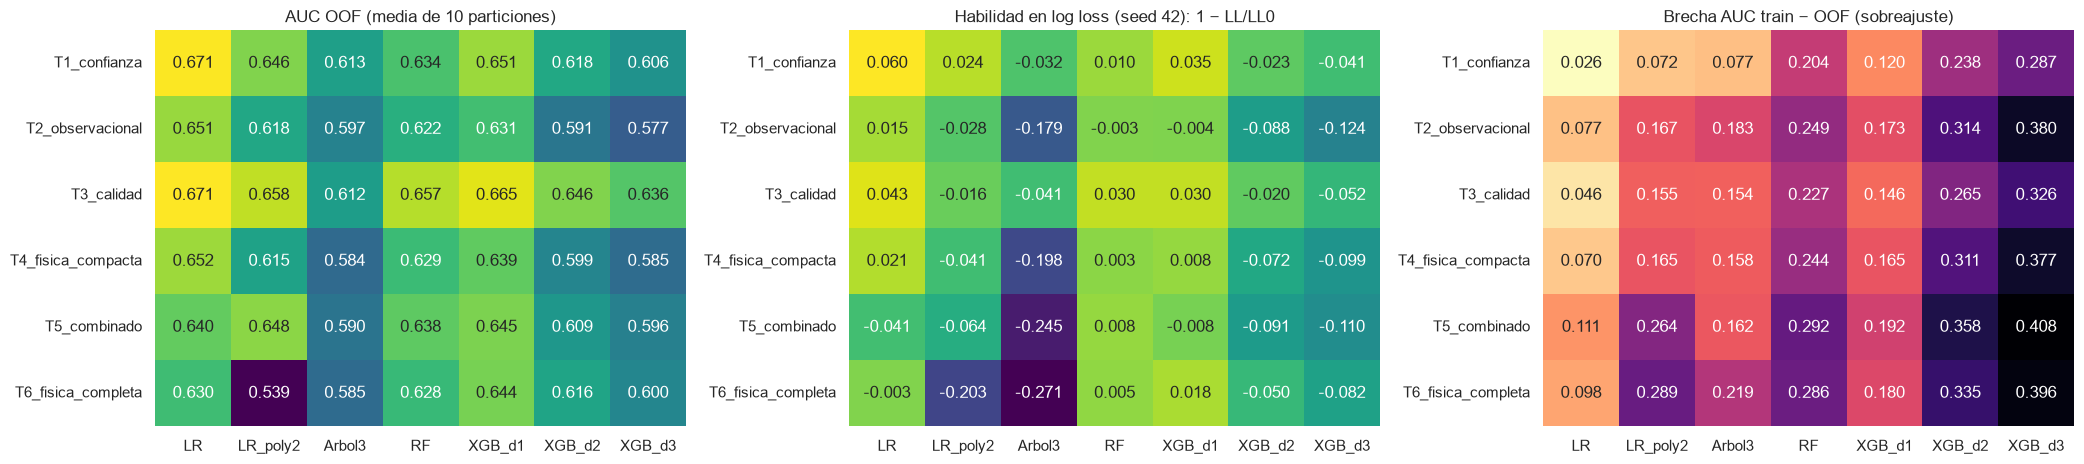

In [36]:
# Repetición con 10 particiones de folds (estabilidad frente a la partición)
nl_seed_auc = {}
for sname, feats in NL_SETS.items():
    for mname in NL_MODELS:
        nl_seed_auc[(sname, mname)] = np.array([roc_auc_score(y_dis, cv_model(y_dis, feats, mname, seed=s)) for s in ROBUSTNESS_SEEDS])

rows = []
for (sname, mname), o in nl_oof.items():
    sa = nl_seed_auc[(sname, mname)]
    rows.append({"conjunto": sname, "modelo": mname, "n_rasgos": len(NL_SETS[sname]), "AUC_OOF": roc_auc_score(y_dis, o), "AUC_seeds_media": sa.mean(),
                 "AUC_seeds_sd": sa.std(ddof=1), "AUC_seeds_min": sa.min(), "AUC_train": nl_trainauc[(sname, mname)],
                 "brecha_train_menos_OOF": nl_trainauc[(sname, mname)] - roc_auc_score(y_dis, o),
                 "logloss_OOF": ll_i(y_dis, o).mean(), "skill_logloss(1-LL/LL0)": 1 - ll_i(y_dis, o).mean() / base_ll,
                 "brier_OOF": brier_score_loss(y_dis, o)})
nl_main = pd.DataFrame(rows)
display(Markdown(f"**Rendimiento OOF por conjunto de rasgos y modelo** (n={len(dis)} desacuerdos; LL0 = log loss de la tasa base = {base_ll:.3f}; AUC_seeds = media ± sd sobre {len(ROBUSTNESS_SEEDS)} particiones)"))
display(nl_main.round(4))
save_table(nl_main, "nl_model_comparison")

fig, axes = plt.subplots(1, 3, figsize=(21, 4.8))
for ax, col, ttl, cm in [(axes[0], "AUC_seeds_media", f"AUC OOF (media de {len(ROBUSTNESS_SEEDS)} particiones)", "viridis"),
                         (axes[1], "skill_logloss(1-LL/LL0)", "Habilidad en log loss (seed 42): 1 − LL/LL0", "viridis"),
                         (axes[2], "brecha_train_menos_OOF", "Brecha AUC train − OOF (sobreajuste)", "magma_r")]:
    pv_ = nl_main.pivot(index="conjunto", columns="modelo", values=col).loc[list(NL_SETS), NL_MODELS]
    sns.heatmap(pv_, annot=True, fmt=".3f", cmap=cm, ax=ax, cbar=False)
    ax.set_title(ttl); ax.set_xlabel(""); ax.set_ylabel("")
fig.tight_layout(); save_fig(fig, "sec12_rendimiento_modelos"); plt.show()

**Cómo leer estas tablas.** La columna `AUC_seeds_sd` indica cuánto varía el AUC solo por cambiar la partición en folds: diferencias entre modelos menores que esa variación no son interpretables. La brecha train−OOF mide el sobreajuste (una brecha grande con AUC OOF igual o menor que la logística indica que el modelo flexible memoriza ruido). La habilidad en log loss es 0 cuando el modelo no supera a predecir la tasa base y puede ser negativa si las probabilidades están peor calibradas que la tasa base.

In [37]:
# Comparaciones pareadas frente a la LR con los mismos rasgos (diferencia = modelo − LR)
def paired_boot(y, p_ref, p_new, n_boot=N_BOOT_AUC, alpha=0.05, seed=SEED):
    r_ = np.random.default_rng(seed); n = len(y)
    dll = ll_i(y, p_new) - ll_i(y, p_ref)
    da, dl = [], []
    for _ in range(n_boot):
        i = r_.integers(0, n, n)
        if len(np.unique(y[i])) < 2:
            continue
        da.append(roc_auc_score(y[i], p_new[i]) - roc_auc_score(y[i], p_ref[i])); dl.append(dll[i].mean())
    q = [100 * alpha / 2, 100 * (1 - alpha / 2)]
    return (roc_auc_score(y, p_new) - roc_auc_score(y, p_ref), *np.percentile(da, q), dll.mean(), *np.percentile(dl, q))


rows = []
for sname in NL_SETS:
    for mname in NL_MODELS[1:]:
        da, lo, hi, dl, llo, lhi = paired_boot(y_dis, nl_oof[(sname, "LR")], nl_oof[(sname, mname)])
        ds = nl_seed_auc[(sname, mname)] - nl_seed_auc[(sname, "LR")]
        rows.append({"conjunto": sname, "modelo": mname, "dAUC_vs_LR": da, "dAUC_lo": lo, "dAUC_hi": hi, "dLogLoss_vs_LR": dl, "dLL_lo": llo, "dLL_hi": lhi,
                     "dAUC_seeds_media": ds.mean(), "dAUC_seeds_positivas": int((ds > 0).sum()), "n_seeds": len(ds)})
nl_cmp = pd.DataFrame(rows)

# Prueba de permutación de ΔAUC (XGB primario − LR): bajo H0 (sin señal) los modelos flexibles puntúan algo peor
perm_rows = []
for sname, feats in NL_SETS.items():
    r_ = np.random.default_rng(SEED + 1)
    nd = []
    for _ in range(NL_N_PERM):
        yp = r_.permutation(y_dis)
        nd.append(roc_auc_score(yp, cv_model(yp, feats, TREE_PRIMARY)) - roc_auc_score(yp, cv_model(yp, feats, "LR")))
    nd = np.array(nd)
    obs = roc_auc_score(y_dis, nl_oof[(sname, TREE_PRIMARY)]) - roc_auc_score(y_dis, nl_oof[(sname, "LR")])
    perm_rows.append({"conjunto": sname, "modelo": TREE_PRIMARY, "dAUC_obs": obs, "dAUC_nulo_medio": nd.mean(), "dAUC_nulo_p97.5": np.percentile(nd, 97.5),
                      "p_perm": (1 + (nd >= obs).sum()) / (len(nd) + 1)})
nl_perm = pd.DataFrame(perm_rows)
nl_perm["p_holm"] = holm(nl_perm.p_perm.values)
nl_cmp = nl_cmp.merge(nl_perm[["conjunto", "modelo", "dAUC_nulo_medio", "p_perm", "p_holm"]], on=["conjunto", "modelo"], how="left")
save_table(nl_cmp, "nl_paired_comparisons")
display(Markdown(f"**Diferencia pareada respecto de la LR con los mismos rasgos** (IC95% bootstrap; `dAUC_seeds_positivas`: de {len(ROBUSTNESS_SEEDS)} particiones en cuántas el modelo supera a la LR). "
                 f"Para el modelo primario `{TREE_PRIMARY}` se añade la prueba de permutación con {NL_N_PERM} permutaciones y ajuste de Holm sobre los {len(NL_SETS)} conjuntos."))
display(nl_cmp.round(4))
R["nl_cmp"] = nl_cmp; R["nl_perm"] = nl_perm

**Diferencia pareada respecto de la LR con los mismos rasgos** (IC95% bootstrap; `dAUC_seeds_positivas`: de 10 particiones en cuántas el modelo supera a la LR). Para el modelo primario `XGB_d2` se añade la prueba de permutación con 200 permutaciones y ajuste de Holm sobre los 6 conjuntos.

,conjunto,modelo,dAUC_vs_LR,dAUC_lo,dAUC_hi,dLogLoss_vs_LR,dLL_lo,dLL_hi,dAUC_seeds_media,dAUC_seeds_positivas,n_seeds,dAUC_nulo_medio,p_perm,p_holm
0,T1_confianza,LR_poly2,-0.0370,-0.0599,-0.0144,0.0227,0.0097,0.0357,-0.0245,0,10,NaN,NaN,NaN
1,T1_confianza,Arbol3,-0.0039,-0.0485,0.0410,0.0587,-0.0134,0.1796,-0.0579,0,10,NaN,NaN,NaN
2,T1_confianza,RF,-0.0494,-0.0852,-0.0138,0.0319,0.0088,0.0555,-0.0372,0,10,NaN,NaN,NaN
3,T1_confianza,XGB_d1,-0.0291,-0.0529,-0.0066,0.0160,0.0024,0.0311,-0.0194,0,10,NaN,NaN,NaN
4,T1_confianza,XGB_d2,-0.0764,-0.1184,-0.0343,0.0524,0.0261,0.0789,-0.0525,0,10,0.0071,0.9602,1.0000
5,T1_confianza,XGB_d3,-0.0829,-0.1309,-0.0384,0.0641,0.0302,0.0966,-0.0647,0,10,NaN,NaN,NaN
6,T2_observacional,LR_poly2,-0.0463,-0.0812,-0.0123,0.0275,0.0032,0.0521,-0.0334,0,10,NaN,NaN,NaN
7,T2_observacional,Arbol3,-0.0573,-0.1163,-0.0041,0.1236,0.0410,0.2348,-0.0541,0,10,NaN,NaN,NaN
8,T2_observacional,RF,-0.0290,-0.0631,0.0041,0.0116,-0.0073,0.0324,-0.0286,0,10,NaN,NaN,NaN
9,T2_observacional,XGB_d1,-0.0261,-0.0571,0.0028,0.0122,-0.0068,0.0318,-0.0197,1,10,NaN,NaN,NaN


In [38]:
# ¿Mejora algo añadir calidad / física frente a usar solo la confianza (T1)? Misma comparación en LR y en el árbol primario
rows = []
for mname in ["LR", TREE_PRIMARY]:
    for sname in list(NL_SETS)[1:]:
        da, lo, hi, dl, llo, lhi = paired_boot(y_dis, nl_oof[("T1_confianza", mname)], nl_oof[(sname, mname)], alpha=0.05 / (len(NL_SETS) - 1))
        rows.append({"modelo": mname, "conjunto_vs_T1": sname, "dAUC": da, "dAUC_lo(Bonferroni)": lo, "dAUC_hi(Bonferroni)": hi, "dLogLoss": dl, "dLL_lo": llo, "dLL_hi": lhi})
nl_add = pd.DataFrame(rows)
display(Markdown("**Aporte de los rasgos de contexto sobre la confianza** (diferencia respecto de T1 con el mismo modelo; IC con corrección de Bonferroni por 5 comparaciones). "
                 "Un IC que incluye 0 significa que no se detecta aporte."))
display(nl_add.round(4))
save_table(nl_add, "nl_context_vs_confidence")
R["nl_add"] = nl_add

**Aporte de los rasgos de contexto sobre la confianza** (diferencia respecto de T1 con el mismo modelo; IC con corrección de Bonferroni por 5 comparaciones). Un IC que incluye 0 significa que no se detecta aporte.

,modelo,conjunto_vs_T1,dAUC,dAUC_lo(Bonferroni),dAUC_hi(Bonferroni),dLogLoss,dLL_lo,dLL_hi
0,LR,T2_observacional,-0.0430,-0.0691,-0.0158,0.0283,0.0115,0.0472
1,LR,T3_calidad,-0.0067,-0.0344,0.0186,0.0105,-0.0070,0.0336
2,LR,T4_fisica_compacta,-0.0396,-0.0663,-0.0152,0.0245,0.0104,0.0399
3,LR,T5_combinado,-0.0607,-0.1045,-0.0154,0.0639,0.0242,0.1101
4,LR,T6_fisica_completa,-0.0565,-0.0991,-0.0160,0.0401,0.0104,0.0753
5,XGB_d2,T2_observacional,-0.0426,-0.0789,-0.0111,0.0417,0.0161,0.0699
6,XGB_d2,T3_calidad,0.0206,-0.0274,0.0649,-0.0014,-0.0329,0.0332
7,XGB_d2,T4_fisica_compacta,-0.0387,-0.0845,0.0050,0.0314,0.0055,0.0609
8,XGB_d2,T5_combinado,-0.0426,-0.1012,0.0134,0.0431,0.0041,0.0826
9,XGB_d2,T6_fisica_completa,-0.0200,-0.0690,0.0401,0.0171,-0.0230,0.0495


**Cribado univariado de no linealidad** (modelo con un solo rasgo; IC con corrección de Bonferroni por 12 rasgos). Ojo: el AUC OOF de un rasgo sin señal queda por debajo de 0.5 por el artefacto de la CV; interesa la diferencia pareada.

,rasgo,AUC_LR,AUC_XGB_d1,dAUC,dAUC_lo(Bonferroni),dAUC_hi(Bonferroni),dLogLoss,dLL_lo,dLL_hi
0,confidence_rgb,0.6853,0.6533,-0.0320,-0.0655,-0.0004,0.0100,-0.0049,0.0255
1,confidence_spectrum,0.5441,0.4827,-0.0614,-0.1306,0.0052,0.0181,0.0025,0.0362
2,probability_gap,0.6215,0.5902,-0.0313,-0.0906,0.0248,0.0078,-0.0119,0.0328
3,nsa_z,0.4811,0.5063,0.0253,-0.1138,0.1673,0.0078,-0.0160,0.0329
4,PETRO_TH90,0.4038,0.4384,0.0345,-0.1126,0.1654,0.0121,-0.0129,0.0358
5,LogMass,0.4472,0.4568,0.0096,-0.0969,0.1143,0.0130,-0.0063,0.0337
6,sn_window,0.5739,0.5403,-0.0335,-0.0899,0.0179,0.0013,-0.0201,0.0251
7,adev_pct,0.5253,0.4468,-0.0786,-0.1889,0.0410,0.0157,-0.0018,0.0323
8,chi2_nl_eff,0.4974,0.3992,-0.0982,-0.2302,0.0487,0.0229,0.0046,0.0402
9,age_mean_light_gyr,0.4952,0.4588,-0.0365,-0.2065,0.1170,0.0115,-0.0060,0.0319


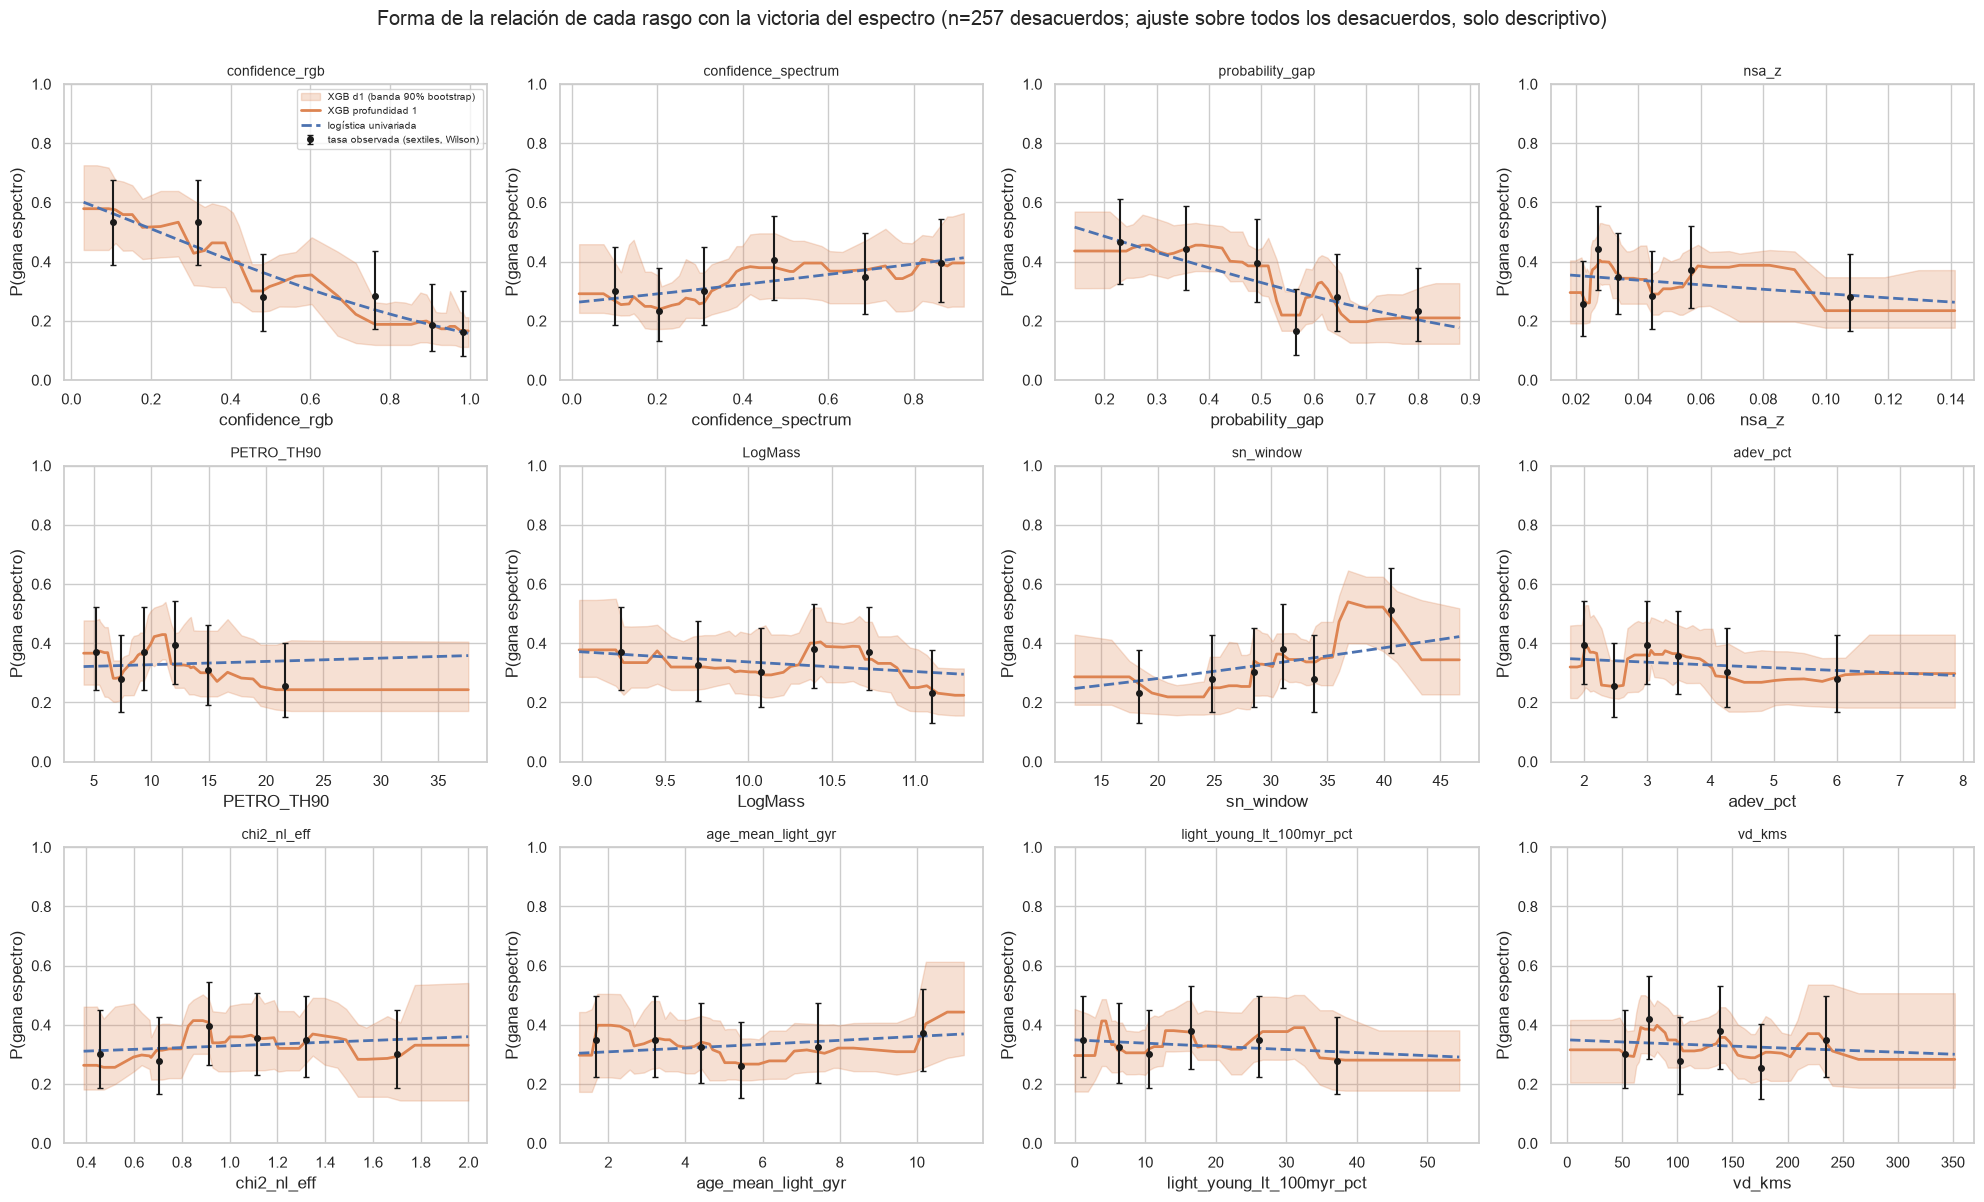

In [39]:
# Curvas univariadas: ¿es no lineal la relación de cada rasgo con P(gana espectro)? LR (monótona) vs XGB profundidad 1 (flexible)
UNI = ["confidence_rgb", "confidence_spectrum", "probability_gap"] + VARS_OBS + VARS_QUALITY + PHYS_COMPACT
rows = []
for f in UNI:
    o_lr = cv_model(y_dis, [f], "LR"); o_xg = cv_model(y_dis, [f], "XGB_d1")
    da, lo, hi, dl, llo, lhi = paired_boot(y_dis, o_lr, o_xg, n_boot=N_BOOT, alpha=0.05 / len(UNI))
    rows.append({"rasgo": f, "AUC_LR": roc_auc_score(y_dis, o_lr), "AUC_XGB_d1": roc_auc_score(y_dis, o_xg), "dAUC": da, "dAUC_lo(Bonferroni)": lo, "dAUC_hi(Bonferroni)": hi,
                 "dLogLoss": dl, "dLL_lo": llo, "dLL_hi": lhi})
nl_uni = pd.DataFrame(rows)
display(Markdown("**Cribado univariado de no linealidad** (modelo con un solo rasgo; IC con corrección de Bonferroni por 12 rasgos). "
                 "Ojo: el AUC OOF de un rasgo sin señal queda por debajo de 0.5 por el artefacto de la CV; interesa la diferencia pareada."))
display(nl_uni.round(4))
save_table(nl_uni, "nl_univariate_screen")

grid_f = lambda s: np.quantile(s, np.linspace(0.02, 0.98, 40))
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
r_ = np.random.default_rng(SEED)
for ax, f in zip(axes.ravel(), UNI):
    x = dis[[f]]; g = grid_f(dis[f].values); gdf = pd.DataFrame({f: g})
    m_lr = make_model("LR").fit(x, y_dis); m_xg = make_model("XGB_d1").fit(x, y_dis)
    bands = []
    for _ in range(40):
        i = r_.integers(0, len(dis), len(dis))
        if len(np.unique(y_dis[i])) < 2:
            continue
        bands.append(make_model("XGB_d1").fit(x.iloc[i], y_dis[i]).predict_proba(gdf)[:, 1])
    lo_, hi_ = np.percentile(bands, [5, 95], axis=0)
    ax.fill_between(g, lo_, hi_, color="C1", alpha=0.25, label="XGB d1 (banda 90% bootstrap)")
    ax.plot(g, m_xg.predict_proba(gdf)[:, 1], color="C1", lw=2, label="XGB profundidad 1")
    ax.plot(g, m_lr.predict_proba(gdf)[:, 1], color="C0", lw=2, ls="--", label="logística univariada")
    qb = pd.qcut(dis[f], 6, duplicates="drop")
    for b, gg in dis.groupby(qb, observed=True):
        k_, n_ = int(gg.selector_target.sum()), len(gg); lo_w, hi_w = wilson(k_, n_)
        ax.errorbar(gg[f].median(), k_ / n_, yerr=[[k_ / n_ - lo_w], [hi_w - k_ / n_]], fmt="ko", ms=4, capsize=2, label="tasa observada (sextiles, Wilson)" if b == qb.cat.categories[0] else None)
    ax.set_title(f"{f}", fontsize=10); ax.set_xlabel(f); ax.set_ylabel("P(gana espectro)"); ax.set_ylim(0, 1)
axes[0, 0].legend(fontsize=7)
fig.suptitle(f"Forma de la relación de cada rasgo con la victoria del espectro (n={len(dis)} desacuerdos; ajuste sobre todos los desacuerdos, solo descriptivo)", y=1.0)
fig.tight_layout(); save_fig(fig, "sec12_curvas_univariadas"); plt.show()

**Interpretación.** Si la relación fuera lineal en la escala logit, la curva de XGBoost quedaría dentro de la banda alrededor de la logística y su AUC OOF no superaría al de la LR; una curva con escalones, saturaciones o forma de U que la logística no reproduce, **acompañada de un ΔAUC con IC positivo**, sería evidencia de no linealidad. Las curvas se ajustan con todos los desacuerdos (son descriptivas, no OOF) y los puntos negros dan la tasa observada por sextiles.

**Limitación:** un rasgo individual puede tener forma no lineal sin aportar predicción útil; por eso la decisión se apoya en las diferencias OOF pareadas de la tabla anterior, no en el aspecto de las curvas.

**Importancia por permutación (caída media del AUC en el fold retenido al permutar el rasgo; T5 + ruido)**. La fila `_ruido_control` es una variable sin información: un rasgo cuya importancia no supera claramente la del ruido no es distinguible de él.

modelo,LR,XGB_d2
rasgo,,
confidence_rgb,0.1303,0.0835
sn_window,0.0256,0.0117
probability_gap,0.0234,0.0043
chi2_nl_eff,0.0054,0.0003
p_spectrum,0.0134,-0.0005
confidence_spectrum,0.0221,-0.0019
_ruido_control,-0.0015,-0.0024
age_mean_light_gyr,-0.0008,-0.0052
adev_pct,0.0061,-0.0065


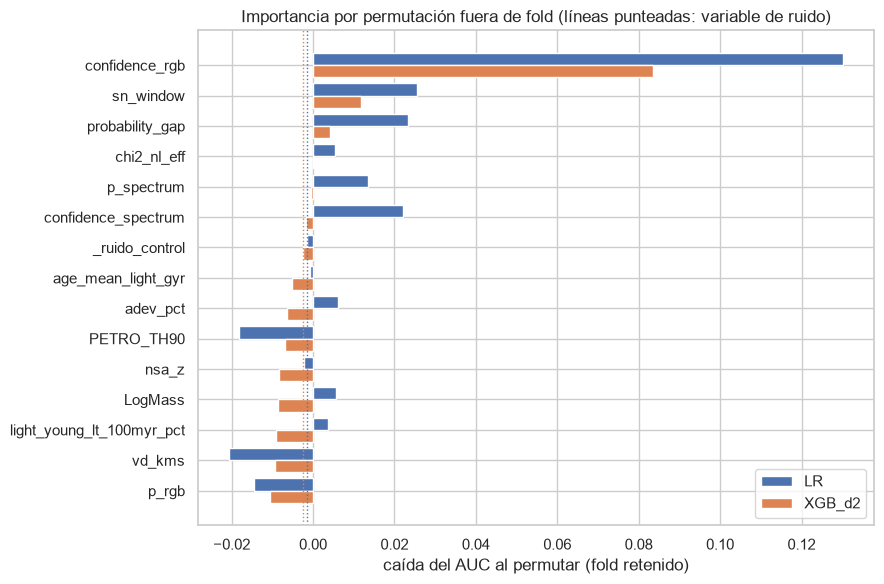

In [40]:
# Importancia por permutación FUERA de fold (conjunto T5 + una variable de ruido de control), LR vs XGB primario
r_ = np.random.default_rng(SEED + 7)
Xn = dis.copy(); Xn["_ruido_control"] = r_.normal(size=len(dis))
feats_imp = NL_SETS["T5_combinado"] + ["_ruido_control"]
fold42 = get_folds(y_dis)
imp_rows = []
for mname in ["LR", TREE_PRIMARY]:
    drops = {f: [] for f in feats_imp}
    for k in range(N_FOLDS):
        tr, te = fold42 != k, fold42 == k
        m = make_model(mname).fit(Xn.loc[tr, feats_imp], y_dis[tr])
        Xte = Xn.loc[te, feats_imp].copy(); base_auc = roc_auc_score(y_dis[te], m.predict_proba(Xte)[:, 1])
        for f in feats_imp:
            for _ in range(10):
                Xp = Xte.copy(); Xp[f] = r_.permutation(Xp[f].values)
                drops[f].append(base_auc - roc_auc_score(y_dis[te], m.predict_proba(Xp)[:, 1]))
    for f in feats_imp:
        imp_rows.append({"modelo": mname, "rasgo": f, "caida_AUC_media": np.mean(drops[f]), "caida_AUC_sd": np.std(drops[f], ddof=1)})
nl_imp = pd.DataFrame(imp_rows)
save_table(nl_imp, "nl_feature_importance")
pv_imp = nl_imp.pivot(index="rasgo", columns="modelo", values="caida_AUC_media").sort_values(TREE_PRIMARY, ascending=False)
display(Markdown("**Importancia por permutación (caída media del AUC en el fold retenido al permutar el rasgo; T5 + ruido)**. La fila `_ruido_control` es una variable sin información: "
                 "un rasgo cuya importancia no supera claramente la del ruido no es distinguible de él."))
display(pv_imp.round(4))
R["imp"] = pv_imp

fig, ax = plt.subplots(figsize=(9, 6))
y_pos = np.arange(len(pv_imp)); w = 0.4
ax.barh(y_pos - w / 2, pv_imp["LR"], w, label="LR", color="C0"); ax.barh(y_pos + w / 2, pv_imp[TREE_PRIMARY], w, label=TREE_PRIMARY, color="C1")
ax.axvline(pv_imp.loc["_ruido_control", TREE_PRIMARY], color="C1", ls=":", lw=1); ax.axvline(pv_imp.loc["_ruido_control", "LR"], color="C0", ls=":", lw=1)
ax.set_yticks(y_pos); ax.set_yticklabels(pv_imp.index); ax.invert_yaxis(); ax.set_xlabel("caída del AUC al permutar (fold retenido)")
ax.set_title("Importancia por permutación fuera de fold (líneas punteadas: variable de ruido)"); ax.legend()
fig.tight_layout(); save_fig(fig, "sec12_importancia_permutacion"); plt.show()

**Interpretación.** La importancia por permutación se mide sobre galaxias *no usadas para ajustar* el modelo, por lo que no premia el sobreajuste. Los rasgos están correlacionados (`p_*`, `confidence_*` y `probability_gap` son transformaciones unas de otras), de modo que su importancia se reparte y un valor bajo no implica que carezcan de información. Que un rasgo de contexto supere claramente al ruido en el árbol y no en la LR sería indicio de relaciones no lineales o de interacciones; si no se distingue del ruido en ninguno, no hay evidencia de que aporte.

**Ganancia neta frente a RGB sola por selector** (IC95% bootstrap sobre galaxias, decisiones OOF fijas; referencia: fusión fija α=0.85 → +3; oráculo → +85)

modelo,LR,LR_poly2,Arbol3,RF,XGB_d1,XGB_d2,XGB_d3
conjunto,,,,,,,
T1_confianza,5,-3,5,2,6,4,2
T2_observacional,-4,-8,-16,-4,0,-6,-14
T3_calidad,2,1,-4,7,10,1,-3
T4_fisica_compacta,1,-6,0,3,0,-9,-7
T5_combinado,-3,1,-6,3,0,-4,-11
T6_fisica_completa,1,-8,-11,-6,-2,-11,-15


,conjunto,modelo,AUC_OOF,n_cambios_a_espectro,rescued_rgb_errors,lost_rgb_correct,net_gain,net_gain_lo,net_gain_hi,delta_acc_vs_rgb,delta_acc_lo,delta_acc_hi
0,T1_confianza,LR,0.6753,49,27,22,5,-8.0000,19.0000,0.0036,-0.0057,0.0135
1,T1_confianza,XGB_d2,0.5989,50,27,23,4,-9.0000,18.0000,0.0029,-0.0064,0.0128
2,T2_observacional,LR,0.6324,52,24,28,-4,-18.0000,10.0000,-0.0029,-0.0128,0.0071
3,T2_observacional,XGB_d2,0.5562,54,24,30,-6,-20.0000,8.0000,-0.0043,-0.0143,0.0057
4,T3_calidad,LR,0.6686,48,25,23,2,-11.0250,16.0000,0.0014,-0.0079,0.0114
5,T3_calidad,XGB_d2,0.6194,53,27,26,1,-13.0000,14.0250,0.0007,-0.0093,0.0100
6,T4_fisica_compacta,LR,0.6357,45,23,22,1,-12.0000,15.0000,0.0007,-0.0086,0.0107
7,T4_fisica_compacta,XGB_d2,0.5601,55,23,32,-9,-24.0000,5.0000,-0.0064,-0.0171,0.0036
8,T5_combinado,LR,0.6146,51,24,27,-3,-17.0000,11.0000,-0.0021,-0.0121,0.0078
9,T5_combinado,XGB_d2,0.5563,60,28,32,-4,-19.0000,12.0000,-0.0029,-0.0135,0.0086


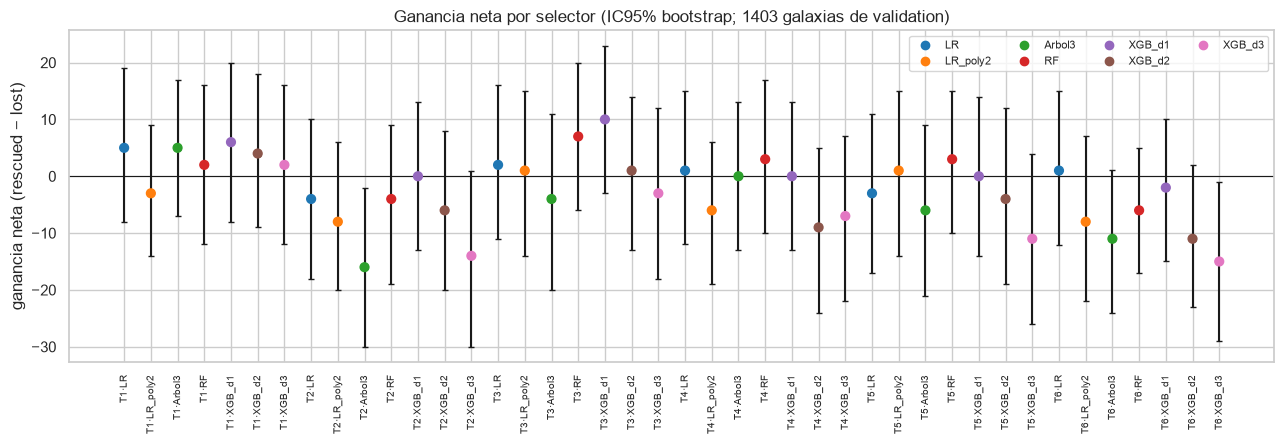

In [41]:
# Simulación de selección (mismo sistema del §8) con cada selector flexible: umbral 0.5 sobre la probabilidad sin ponderar
nl_rows = []
for (sname, mname), o in nl_oof.items():
    key = f"{sname}|{mname}"
    choice[key] = (o >= THRESHOLD).astype(int)
    r = system_eval(dev, full_choice(key), key, key)
    r.update(conjunto=sname, modelo=mname, AUC_OOF=roc_auc_score(y_dis, o))
    nl_rows.append(r)
nl_sim = pd.DataFrame(nl_rows)
cols_sim = ["conjunto", "modelo", "AUC_OOF", "n_cambios_a_espectro", "rescued_rgb_errors", "lost_rgb_correct", "net_gain", "net_gain_lo", "net_gain_hi",
            "delta_acc_vs_rgb", "delta_acc_lo", "delta_acc_hi"]
save_table(nl_sim[cols_sim], "nl_selection_simulation")
display(Markdown("**Ganancia neta frente a RGB sola por selector** (IC95% bootstrap sobre galaxias, decisiones OOF fijas; referencia: fusión fija α=0.85 → "
                 f"{int(S.loc[f'Fusión fija α={ALPHA_FIXED}'].net_gain):+d}; oráculo → {int(S.loc['Oráculo (cota superior, no alcanzable)'].net_gain):+d})"))
display(nl_sim.pivot(index="conjunto", columns="modelo", values="net_gain").loc[list(NL_SETS), NL_MODELS].astype(int))
display(nl_sim[nl_sim.modelo.isin(["LR", TREE_PRIMARY])][cols_sim].round(4).reset_index(drop=True))
R["nl_sim"] = nl_sim

pd.DataFrame([{"conjunto": s, "modelo": m, "name": nm, "fold": f, "y_gana_espectro": yy, "proba_gana_espectro": p}
              for (s, m), o in nl_oof.items() for nm, f, yy, p in zip(dis.name, folds, y_dis, o)]).pipe(lambda d: save_table(d, "nl_oof_predictions"))

fig, ax = plt.subplots(figsize=(13, 4.6))
sub = nl_sim.copy(); sub["x"] = np.arange(len(sub))
ax.errorbar(sub.x, sub.net_gain, yerr=[sub.net_gain - sub.net_gain_lo, sub.net_gain_hi - sub.net_gain], fmt="o", color="k", capsize=2, ms=4)
colors = {m: c for m, c in zip(NL_MODELS, sns.color_palette("tab10", len(NL_MODELS)))}
ax.scatter(sub.x, sub.net_gain, c=[colors[m] for m in sub.modelo], zorder=3, s=40)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(sub.x); ax.set_xticklabels([f"{r.conjunto[:2]}·{r.modelo}" for r in sub.itertuples()], rotation=90, fontsize=7)
ax.set_ylabel("ganancia neta (rescued − lost)"); ax.set_title(f"Ganancia neta por selector (IC95% bootstrap; {len(dev)} galaxias de validation)")
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=m) for m, c in colors.items()]; ax.legend(handles=handles, fontsize=8, ncol=4)
fig.tight_layout(); save_fig(fig, "sec12_ganancia_neta"); plt.show()

**Interpretación.** Esta tabla traduce el AUC a lo que importa para un gate: cuántos errores de RGB se corrigen y cuántos aciertos se pierden. Al ser 42 selectores evaluados sobre las mismas galaxias, el mejor de ellos se verá optimista por simple selección; por eso la valoración se hace con el modelo arbóreo **primario fijado de antemano** y no con el máximo de la tabla.

In [42]:
# Síntesis y veredicto de la sección 12 (generado a partir de los resultados)
c = R["nl_cmp"]; pri = c[c.modelo == TREE_PRIMARY].set_index("conjunto")
sim_ = R["nl_sim"].set_index(["conjunto", "modelo"])
ok_auc = pri[(pri.dAUC_lo > 0) & (pri.p_holm < 0.05)]
n_seeds_ok = pri[pri.dAUC_seeds_positivas >= int(0.8 * len(ROBUSTNESS_SEEDS))]
gain_ok = [s for s in NL_SETS if sim_.loc[(s, TREE_PRIMARY), "net_gain_lo"] > 0]
add = R["nl_add"]; add_tree = add[(add.modelo == TREE_PRIMARY) & (add["dAUC_lo(Bonferroni)"] > 0)]
uni_nl = nl_uni[nl_uni["dAUC_lo(Bonferroni)"] > 0]
best_tree = nl_main[nl_main.modelo != "LR"].sort_values("AUC_seeds_media", ascending=False).iloc[0]
best_lr = nl_main[nl_main.modelo == "LR"].sort_values("AUC_seeds_media", ascending=False).iloc[0]
imp_ = R["imp"]; nz = nl_imp[(nl_imp.rasgo == "_ruido_control") & (nl_imp.modelo == TREE_PRIMARY)].iloc[0]
noise_thr = nz.caida_AUC_media + 2 * nz.caida_AUC_sd   # umbral conservador: media del ruido + 2 sd de sus caídas individuales
above_noise = [f for f in imp_.index if f != "_ruido_control" and imp_.loc[f, TREE_PRIMARY] > noise_thr]
t1_lr = nl_main[(nl_main.conjunto == "T1_confianza") & (nl_main.modelo == "LR")].iloc[0]
t1_xg = nl_main[(nl_main.conjunto == "T1_confianza") & (nl_main.modelo == TREE_PRIMARY)].iloc[0]
gap_xg = nl_main[nl_main.modelo == TREE_PRIMARY]["brecha_train_menos_OOF"].mean(); gap_lr = nl_main[nl_main.modelo == "LR"]["brecha_train_menos_OOF"].mean()

lines = [
 f"**Resultados observados.**",
 f"* **H1 (árboles > logística con los mismos rasgos).** Con `{TREE_PRIMARY}` el ΔAUC frente a la LR tiene IC95% > 0 *y* p de permutación ajustado (Holm) < 0.05 en {len(ok_auc)} de {len(NL_SETS)} conjuntos"
 + (f" ({', '.join(ok_auc.index)})" if len(ok_auc) else "") + f"; supera a la LR en ≥ 80 % de las particiones en {len(n_seeds_ok)} de {len(NL_SETS)}. "
 f"En T1 (solo confianza): AUC {t1_xg.AUC_seeds_media:.3f} (árbol) vs {t1_lr.AUC_seeds_media:.3f} (LR).",
 f"* **Mejor modelo flexible** (promedio de particiones; selección optimista): {best_tree.modelo} con {best_tree.conjunto}, AUC {best_tree.AUC_seeds_media:.3f}; mejor LR: {best_lr.conjunto}, AUC {best_lr.AUC_seeds_media:.3f}.",
 f"* **No linealidad univariada.** {len(uni_nl)} de {len(nl_uni)} rasgos muestran un ΔAUC (XGB d1 − LR) con IC > 0 tras Bonferroni" + (f": {', '.join(uni_nl.rasgo)}." if len(uni_nl) else "."),
 f"* **H2 (el contexto ayuda a los árboles).** {len(add_tree)} de {len(add[add.modelo == TREE_PRIMARY])} conjuntos con contexto mejoran a T1 con `{TREE_PRIMARY}` (IC Bonferroni > 0)" + (f": {', '.join(add_tree.conjunto_vs_T1)}." if len(add_tree) else "."),
 f"* **Importancia fuera de fold:** rasgos con importancia mayor que el umbral de ruido ({noise_thr:.3f}) en `{TREE_PRIMARY}`: " + (", ".join(above_noise) if above_noise else "ninguno") + ".",
 f"* **Sobreajuste:** brecha media AUC train−OOF {gap_xg:.3f} en `{TREE_PRIMARY}` vs {gap_lr:.3f} en LR.",
 f"* **Ganancia neta:** el selector `{TREE_PRIMARY}` tiene ganancia neta con IC95% > 0 en {len(gain_ok)} de {len(NL_SETS)} conjuntos" + (f" ({', '.join(gain_ok)})" if gain_ok else "")
 + f"; en T1 obtiene {int(sim_.loc[('T1_confianza', TREE_PRIMARY), 'net_gain']):+d} [{sim_.loc[('T1_confianza', TREE_PRIMARY), 'net_gain_lo']:.0f}, {sim_.loc[('T1_confianza', TREE_PRIMARY), 'net_gain_hi']:.0f}] frente a "
   f"{int(sim_.loc[('T1_confianza', 'LR'), 'net_gain']):+d} [{sim_.loc[('T1_confianza', 'LR'), 'net_gain_lo']:.0f}, {sim_.loc[('T1_confianza', 'LR'), 'net_gain_hi']:.0f}] de la LR.",
]
tree_better = len(ok_auc) > 0
if tree_better and gain_ok:
    verdict12 = "HAY EVIDENCIA de estructura no lineal aprovechable por árboles Y de ganancia neta: justifica incluir un gate basado en árboles en la Fase 2 (con evaluación confirmatoria)."
elif tree_better:
    verdict12 = "HAY EVIDENCIA de estructura no lineal aprovechable (mejor discriminación que la logística), pero no se traduce en ganancia neta demostrada: se recomienda confirmarla con OOF de los encoders antes de la Fase 2."
else:
    verdict12 = ("NO HAY EVIDENCIA de que los árboles aprovechen estructura no lineal adicional respecto de la logística con confianzas: "
                 "la recomendación del §10 no cambia por este diagnóstico.")
R["verdict12"] = verdict12
lines.append(f"\n### Veredicto del diagnóstico no lineal: {verdict12}")
display(Markdown("\n".join(lines)))

**Resultados observados.**
* **H1 (árboles > logística con los mismos rasgos).** Con `XGB_d2` el ΔAUC frente a la LR tiene IC95% > 0 *y* p de permutación ajustado (Holm) < 0.05 en 0 de 6 conjuntos; supera a la LR en ≥ 80 % de las particiones en 0 de 6. En T1 (solo confianza): AUC 0.618 (árbol) vs 0.671 (LR).
* **Mejor modelo flexible** (promedio de particiones; selección optimista): XGB_d1 con T3_calidad, AUC 0.665; mejor LR: T3_calidad, AUC 0.671.
* **No linealidad univariada.** 0 de 12 rasgos muestran un ΔAUC (XGB d1 − LR) con IC > 0 tras Bonferroni.
* **H2 (el contexto ayuda a los árboles).** 0 de 5 conjuntos con contexto mejoran a T1 con `XGB_d2` (IC Bonferroni > 0).
* **Importancia fuera de fold:** rasgos con importancia mayor que el umbral de ruido (0.041) en `XGB_d2`: confidence_rgb.
* **Sobreajuste:** brecha media AUC train−OOF 0.304 en `XGB_d2` vs 0.071 en LR.
* **Ganancia neta:** el selector `XGB_d2` tiene ganancia neta con IC95% > 0 en 0 de 6 conjuntos; en T1 obtiene +4 [-9, 18] frente a +5 [-8, 19] de la LR.

### Veredicto del diagnóstico no lineal: NO HAY EVIDENCIA de que los árboles aprovechen estructura no lineal adicional respecto de la logística con confianzas: la recomendación del §10 no cambia por este diagnóstico.

### Hipótesis plausibles y limitaciones de este diagnóstico

* **Plausible, no probado:** la información útil de la confianza podría ser casi toda monótona una vez expresada como `2|p−0.5|`, por lo que un modelo flexible aporta poco; y la calidad y las propiedades físicas podrían ser predictores de la morfología más que de la fiabilidad, enmascarados por la dependencia de la dirección del desacuerdo.
* **Potencia limitada:** con unas decenas de galaxias por fold y modelos de árboles, solo se detectarían efectos grandes; un resultado nulo no descarta no linealidad pequeña o interacciones complejas.
* **Hiperparámetros fijos:** no se ajustaron (para no sobreajustar la validación); otros valores podrían cambiar los resultados, aunque la comparación con profundidades 1–3, RF y árbol único acota esa sensibilidad.
* **Sesgos heredados:** las predicciones base proceden de redes cuyos checkpoints se eligieron con `validation`; los selectores se evalúan con OOF *solo del selector*, no de los encoders.
* **Selección múltiple:** se evaluaron 42 combinaciones; por eso el veredicto se basa en el modelo primario prefijado, con prueba de permutación y ajuste de comparaciones múltiples, y no en el máximo.
* **Siguiente paso si hubiera señal:** repetir el análisis con predicciones OOF de los propios encoders (más desacuerdos) y una evaluación final reservada.

In [43]:
# Exportación de la configuración de esta sección (config.json del §11 no se modifica)
cfg12 = {"conjuntos_de_rasgos": NL_SETS, "modelos": NL_MODELS, "modelo_arboreo_primario": TREE_PRIMARY, "motor_boosting": f"xgboost {xgb.__version__}" if HAS_XGB else "HistGradientBoosting (fallback)",
         "hiperparametros": {"XGB": dict(n_estimators=150, learning_rate=0.05, min_child_weight=3, subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0, max_depth="1/2/3"),
                           "RF": dict(n_estimators=200, min_samples_leaf=10, max_features="sqrt"), "Arbol3": dict(max_depth=3, min_samples_leaf=15),
                           "LR": dict(C=LOGREG_C), "LR_poly2": dict(C=0.1, grado=2)},
         "umbral_decision": THRESHOLD, "folds": N_FOLDS, "seed": SEED, "semillas_robustez": ROBUSTNESS_SEEDS, "n_permutaciones_dAUC": NL_N_PERM,
         "n_bootstrap": {"auc": N_BOOT_AUC, "univariado": N_BOOT}, "split_usado": DEV_SPLIT, "veredicto_seccion12": R["verdict12"]}
if SAVE_OUTPUTS:
    (OUT_DIR / "config_seccion12_arboles.json").write_text(json.dumps(cfg12, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
    print("Archivos nuevos de la sección 12:", sorted(p.relative_to(OUT_DIR).as_posix() for p in OUT_DIR.rglob("*") if (p.name.startswith(("nl_", "sec12_", "config_seccion12")))))

Archivos nuevos de la sección 12: ['config_seccion12_arboles.json', 'figuras/sec12_curvas_univariadas.png', 'figuras/sec12_ganancia_neta.png', 'figuras/sec12_importancia_permutacion.png', 'figuras/sec12_rendimiento_modelos.png', 'nl_context_vs_confidence.csv', 'nl_feature_importance.csv', 'nl_model_comparison.csv', 'nl_oof_predictions.csv', 'nl_paired_comparisons.csv', 'nl_selection_simulation.csv', 'nl_univariate_screen.csv']


### Resumen de uso

Para reproducir: ejecutar todas las celdas desde la raíz del proyecto (o cualquier subcarpeta). Para usar otros experimentos, editar `REQUIRED_MODELS` / `OPTIONAL_MODELS` en la configuración. Para cambiar la cuadrícula, los umbrales o los rasgos de cada variante del selector, editar la misma celda; la sección 12 requiere `xgboost` (si no está instalado, usa `HistGradientBoostingClassifier` como alternativa); el resto del notebook (tablas, figuras, conclusiones y veredicto) se recalcula.